# Model analysis: current saved models and observational preferences

This is an exploratory snapshot of ongoing modelling. “Best” means lowest saved score in the stated candidate pool; “competitive” means passing an analysis cutoff. Neither selects a final physical model. New evaluations and different model setups can change every result.

| View | Candidates | Question |
|---|---|---|
| A — available per objective | Eligible models with the scores needed for that objective | Which saved models and parameter ranges currently give lower scores? |
| B — shared per comparison | The same eligible candidates for both objectives | How does adding an observation group change the selected parameter distribution? |
| Fully scored supplement | One compatible subgroup with every observable | What trade-offs, alternative families and weight sensitivity appear in that subgroup? |

Keep physical/numerical setups separate. `RUN_FOLDERS` chooses the collections; `POOL_ID` chooses a compatible physical pool. Read each figure's objective, pool and selection rule before comparing it with another figure or notebook.

**Budget terminology:** “configured final budget” means the target fidelity stage within a run. Models can reach that stage while the optimiser is still running; it does not mean the experiment or model choice is final.

The notebook reads saved evaluations, retains repeats and launches no simulations. Parameter distributions describe this adaptive search sample. Fit quality is assessed separately using model/data predictions and residuals in `run_summary`.


In [1]:
from pathlib import Path
import sys, json, hashlib, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
# Explicit inline backend ensures figures are embedded in executed notebook outputs.
get_ipython().run_line_magic('matplotlib', 'inline')

# Locate the notebook helpers whether Jupyter starts here or at the workspace root.
search = [p/q for p in [Path.cwd(), *Path.cwd().parents]
          for q in [Path('.'), Path('scripts/post-processing'), Path('modelling_optimisation/scripts/post-processing')]]
NOTEBOOK_DIR = next(p for p in search if (p/'model_analysis_utils.py').is_file())
REPOSITORY = NOTEBOOK_DIR.parents[1]
sys.path.insert(0, str(NOTEBOOK_DIR))
from parameter_labels import parameter_label, parameter_description
from run_summary_utils import load_runs, coverage_table, SUBSETS, scoring_fingerprint
from observation_convergence_utils import (readable_model_labels, parameter_reference,
    parameter_values, plot_restriction, parameter_score_diagnostic)
from model_analysis_utils import (GROUPS, objective_design, addition_design, score_matrix,
    competitive_mask, restriction_tables, association_table, alternative_families,
    pareto_mask, empirical_profiles, distribution_effect, bootstrap_history_effects, plot_heatmap)
pd.set_option('display.max_columns', 24)
figures = {}
def show(name, figure):
    if figure is not None:
        figures[name] = figure
        display(figure)
        plt.close(figure)

from model_analysis_utils import eligible_pool_candidates, analyse_pool_views, plot_available_pool_costs


## 1. Analysis controls

These settings select and display saved results; they do not change the physical model or its original scores.

| Controls | Meaning |
|---|---|
| `RUN_FOLDERS`, `POOL_ID` | Input collections and one compatible physical/numerical setup; `None` selects the largest eligible physical pool. |
| `PARAMETERS` | Parameters shown in the main summaries. `None` uses independently varied parameters in the selected pool. |
| `RELATIVE_ALLOWANCES`, `ABSOLUTE_ALLOWANCE` | Score tolerances: keep `score <= best + max(abs(best) * allowance, absolute_allowance)`. |
| `MATCHED_FRACTIONS` | Keep the lowest-scoring fraction by count, including cutoff ties. Used to compare selections of similar size. |
| `DISPLAY_ALLOWANCE`, `DISPLAY_FRACTION` | Which of those selections is displayed in the main summaries. |
| `MIN_MODELS`, `PROFILE_MIN_MODELS` | Minimum valid counts for summary effects or binned envelopes. A display guard, not a convergence criterion. |
| `FAMILY_ALLOWANCE`, `FAMILY_DISTANCE_CUTS` | Score cutoff and parameter-space grouping scales for exploratory families. |
| `WEIGHT_FACTORS` | Temporary observable-weight multipliers in the supplemental sensitivity check. |
| `PREFIX_FRACTIONS` | Fractions of each saved search inspected in completion order. |
| `SCORE_WEIGHTED_*` | Separate controls for the weighted corner plots; explained immediately before those plots. |
| `SAVE_OUTPUTS`, `OUTPUT_DIR` | Whether and where to export this snapshot. |

For example, with best score 100, an allowance of 0.5 keeps scores up to 150. A retained fraction of 0.4 instead keeps the best 40% of evaluations. These rules answer different questions and need not retain the same models.


In [2]:
# Input: each root may contain multiple histories and optimiser seeds.
RUN_FOLDERS = {"seed1": Path("/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1")}
POOL_ID = None                 # None: largest eligible physical/numerical pool, including partial-score models.
# Copy a 'Physical pool NN' label from physical_pool_inventory to select another setup.
PARAMETERS = None              # None: all varied, nonconstant, independent parameters in that pool.

# Selection rules for the main summaries
RELATIVE_ALLOWANCES = [0.10, 0.25, 0.50, 1.0]  # Cost tolerances for robustness, not confidence levels.
ABSOLUTE_ALLOWANCE = 0.0        # Minimum additive slack in original score units; useful when best=0.
MATCHED_FRACTIONS = [0.05, 0.10, 0.20]    # Approximate retained fractions; cutoff ties stay included.
DISPLAY_ALLOWANCE = 0.50       # Main selected sample; not a change to the optimiser.
DISPLAY_FRACTION = 0.10        # Equal-size comparison shown in attribution heatmaps.

# Display support and plot detail
MIN_MODELS = 20                # Minimum valid values before reporting a supported effect.
HISTOGRAM_BINS = 15            # Shared fixed parameter bins; rerun with 10/25 to assess bin sensitivity.
PROFILE_MIN_MODELS = 10        # Sparse profile bins retain counts but have masked plotted summaries.
# Profile plots automatically include every parameter in references; no parameter shortlist.
VIEW_A_COST_ALLOWANCES = (0.10, 0.50, 1.0)  # Relative excess: 10%, 50%, 100% above best.
VIEW_A_PANELS_PER_PAGE = 6  # All parameters are shown, across as many pages as needed.
POINT_SIZE = 16                # Circle area in points squared, identical for all/selected candidates.
POINT_ALPHA = 0.55             # Opacity, identical for all/selected candidates; black/blue distinguish them.
PAIR_PLOTS = 4                 # Display strongest selected numeric associations; all pairs stay in the table.

# Optional checks within the fully scored supplement
FAMILY_ALLOWANCE = 0.10        # Near-best all-data sample for searching distinct alternatives.
FAMILY_DISTANCE_CUTS = [0.10, 0.20, 0.30] # Diagnostic mixed-distance thresholds, not physical equivalence tests.
WEIGHT_FACTORS = [0.5, 1.0, 2.0]         # Explicit stress test of one group's weight; original scores untouched.
PREFIX_FRACTIONS = [0.50, 0.75, 1.0]     # Chronological saved-search prefixes; not independent replicates.
# Optional history-level repeatability check; disabled while the history list is empty.
# Only fill after confirming same design, scoring, numerical setup and independent optimiser histories.
VERIFIED_REPLICATE_HISTORIES = []        # At least 5 verified comparable histories if enabled.
BOOTSTRAP_REPETITIONS = 1000             # Resamples whole run effects, never individual adaptive trials.
RANDOM_SEED = 42                         # Reproducibility of bootstrap only; no new simulation seeds are generated.

# Snapshot export
SAVE_OUTPUTS = True                     # Set True to export all evidence tables, plots and provenance.
OUTPUT_DIR = RUN_FOLDERS['seed1']/'model_analysis_outputs'

# View A descriptive score weighting: delta is the score increase that HALVES weight.
SCORE_WEIGHTED_ENABLED = True
SCORE_WEIGHTED_RETAIN_FRACTION = 0.40  # Lowest-scoring 40% per objective/pool, including cutoff ties.
SCORE_WEIGHTED_OBJECTIVES = None  # None: every available View-A objective, each pool separately.
# None includes ALL independent varied parameters, regardless of PARAMETERS above.
SCORE_WEIGHTED_PARAMETERS = None
# None: default physical grouping, applied only to independent parameters in this pool.
# Override with {'Group title': ['parameter_name', ...], ...}; unassigned names remain in Other parameters.
SCORE_WEIGHTED_PARAMETER_GROUPS = None
SCORE_WEIGHTED_COLOR_SCALE = 'auto'  # Log for positive varying scores; otherwise linear.
SCORE_WEIGHTED_STYLE = 'reference'  # 'reference': one black chain + score cloud; 'sensitivity': overlays.
SCORE_WEIGHTED_REFERENCE_SETTING = None  # None: middle configured setting (25% by default).
# Explicit setting IDs, e.g. 'half_weight_01', are listed in score_temperatures.
SCORE_WEIGHTED_HALF_WEIGHT_FRACTIONS = (0.10, 0.25, 0.50)  # delta = fraction * abs(pool best).
# Absolute deltas REPLACE fractions. Keys: objective or (objective, full score_pool_key).
# Illustrative syntax only: {'PDI': [2., 5., 10.], 'ALMA': [1., 2., 4.]}.
# These numbers are NOT calibrated values. A best score of zero requires an override.
SCORE_WEIGHTED_ABSOLUTE_DELTAS = {}
SCORE_WEIGHTED_CONTOUR_MASSES = (0.68, 0.95, 0.997)  # Fractions of plotted weight, not confidence levels.
SCORE_WEIGHTED_BINS = 20
SCORE_WEIGHTED_SMOOTH = 2  # Gaussian histogram smoothing for the reference style; 0 shows raw bins.
SCORE_WEIGHTED_MIN_ESS = 20  # Weight-concentration guard, not independent sample size.


## 2. Read and audit the saved scores

The audit checks whether the recorded native cost equals the sum of the observation terms requested for that evaluation. Missing terms are not replaced by zero. Failures and mismatches remain visible in the audit, while Views A/B use successful, audited target-budget candidates.

| Score group | Current implementation | Read alongside |
|---|---|---|
| SED | Squared residuals divided by variances, summed and divided by N−1; extinction is fitted | SED points, adopted errors and residuals versus wavelength |
| INT | Sum of four instrument scores, each normalised by N−1 | Visibilities and residuals for each instrument |
| PDI | Weighted squared differences of polarised fraction, normalised radial profile and quadrants | Absolute fraction as well as morphology; recorded correction state |
| ALMA | `100 * sum((model-data)**2) / sum(data**2)` in an aperture | Flux ratio, image residuals and absolute radial brightness |

The total is a composite optimisation score, not one reduced chi-square. A lower value ranks saved candidates under that objective; it does not by itself establish an adequate fit. The notebook preserves the original terms and units.

Historical runs may use different scoring/data conventions. Compatibility uses available metadata, not proof of identical historical inputs; in particular, the loader has no SED-specific data hash. The PDI loss descriptor may say “mean” although the current implementation sums weighted terms. Current source hashes identify the code inspected now, not necessarily the code that generated an old run.


In [3]:
# Hash source files before analysis; these are CURRENT-code hashes, not historical run hashes.
source_paths = [REPOSITORY/'SMAC3.py', *sorted((REPOSITORY/'lib').glob('*.py'))]
source_hashes_before = {str(path): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_paths}
evaluations, inventory, records, configspaces = load_runs(RUN_FOLDERS)
evaluations = readable_model_labels(evaluations)
coverage = coverage_table(evaluations)
display(inventory[['history','optimizer_seed','configured_max_budget','recorded_trials',
                   'configspace_hash','template_hash','photon_settings','stages']])
display(coverage)
cost_audit = evaluations.groupby(['history','cost_audit_status','exclusion']).size().rename('n').reset_index()
display(cost_audit)
# Recorded descriptors can differ from current source. Keep them reviewable.
recorded_scoring = pd.DataFrame([{'history': row.history, 'objective': row.objective_key,
    'comparison_key': row.comparison_key,
    'scoring_metadata': json.dumps(records[row.evaluation_id]['scoring_metadata'], sort_keys=True)}
    for row in evaluations.drop_duplicates(['history','comparison_key']).itertuples()])
display(recorded_scoring)
print('Snapshot inputs:', {label: str(path) for label, path in RUN_FOLDERS.items()})
print('Recorded evaluations:', len(evaluations), '| histories:', len(inventory))


,history,optimizer_seed,configured_max_budget,recorded_trials,configspace_hash,template_hash,photon_settings,stages
0,seed1/int_pdi_alma [seed 878561],878561,1.0,565,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""no_sed"", ""products"": [""vis2_1perba..."
1,seed1/sed [seed 193544],193544,1.0,1000,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""sed"", ""products"": [""sed""], ""budget..."
2,seed1/sed_all_pdi_unres_corr [seed 358239],358239,1.0,285,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""all"", ""products"": [""sed"", ""vis2_1p..."
3,seed1/sed_alma [seed 769887],769887,1.0,1000,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""alma"", ""products"": [""sed"", ""alma""]..."
4,seed1/sed_int_alma [seed 987212],987212,1.0,332,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""no_pdi"", ""products"": [""sed"", ""vis2..."
5,seed1/sed_int_pdi [seed 724769],724769,1.0,552,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""no_alma"", ""products"": [""sed"", ""vis..."
6,seed1/sed_interf [seed 128278],128278,1.0,1000,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""interf"", ""products"": [""sed"", ""vis2..."
7,seed1/sed_pdi_alma [seed 171866],171866,1.0,886,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""all"", ""products"": [""sed"", ""pdi_V"",..."
8,seed1/sed_pdi_unres_corr [seed 823308],823308,1.0,832,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,1.28e5 nbr_photons_eq_th : T...,"[{""stage"": ""pdi"", ""products"": [""sed"", ""pdi_V"",..."


,history,budget,stage,products,recorded,usable,excluded,failures,unfinished,best_cost,evaluation_wall_hours
0,seed1/int_pdi_alma [seed 878561],1.0,no_sed,"alma, pdi_H, pdi_I, pdi_V, vis2_1perband",555,530,25,25,0,690.455441,132.162342
1,seed1/int_pdi_alma [seed 878561],1.0,no_sed,,10,0,10,0,10,NaN,0.000000
2,seed1/sed [seed 193544],1.0,sed,sed,1000,955,45,45,0,14.735357,70.326790
3,seed1/sed_all_pdi_unres_corr [seed 358239],1.0,all,"alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",280,262,18,18,0,1870.782329,123.888341
4,seed1/sed_all_pdi_unres_corr [seed 358239],1.0,all,,5,0,5,0,5,NaN,0.000000
5,seed1/sed_alma [seed 769887],1.0,alma,"alma, sed",995,968,27,27,0,35.606875,109.306499
6,seed1/sed_alma [seed 769887],1.0,alma,,5,0,5,0,5,NaN,0.000000
7,seed1/sed_int_alma [seed 987212],1.0,no_pdi,"alma, sed, vis2_1perband",327,309,18,18,0,202.657751,74.565131
8,seed1/sed_int_alma [seed 987212],1.0,no_pdi,,5,0,5,0,5,NaN,0.000000
9,seed1/sed_int_pdi [seed 724769],1.0,no_alma,"pdi_H, pdi_I, pdi_V, sed, vis2_1perband",542,520,22,22,0,518.188818,156.455663


,history,cost_audit_status,exclusion,n
0,seed1/int_pdi_alma [seed 878561],incomplete_terms,recorded_failure,25
1,seed1/int_pdi_alma [seed 878561],incomplete_terms,unfinished,10
2,seed1/int_pdi_alma [seed 878561],match,usable,530
3,seed1/sed [seed 193544],incomplete_terms,recorded_failure,45
4,seed1/sed [seed 193544],match,usable,955
5,seed1/sed_all_pdi_unres_corr [seed 358239],incomplete_terms,recorded_failure,18
6,seed1/sed_all_pdi_unres_corr [seed 358239],incomplete_terms,unfinished,5
7,seed1/sed_all_pdi_unres_corr [seed 358239],match,usable,262
8,seed1/sed_alma [seed 769887],incomplete_terms,recorded_failure,27
9,seed1/sed_alma [seed 769887],incomplete_terms,unfinished,5


,history,objective,comparison_key,scoring_metadata
0,seed1/int_pdi_alma [seed 878561],"INT(band)+PDI(V,I,H)+ALMA",9cc73bbc105abdfd9dd81c492982775152b8ea69ace6a4...,"{""alma_observed"": {""aperture_pixel_count"": 325..."
1,seed1/int_pdi_alma [seed 878561],"INT(band)+PDI(V,I,H)+ALMA",fb90891c7aa620ec657322e520650f7b4022812024b673...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
2,seed1/int_pdi_alma [seed 878561],No products,7ffe9be754f1f787ae56f63dcfa14d329a252ab8186cc8...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
3,seed1/int_pdi_alma [seed 878561],"INT(band)+PDI(V,I,H)+ALMA",22d266d9f6cb4b339458e3360f73918b9ce342035be1fd...,"{""alma_observed"": {""aperture_pixel_count"": 325..."
4,seed1/sed [seed 193544],SED,04fd74a5e5ea70fed891d054f7aa97bee9a56442340747...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
5,seed1/sed_all_pdi_unres_corr [seed 358239],"SED+INT(band)+PDI(V,I,H)+ALMA",53b5191ef93607d23a49ceb86f4666b1644db3c0490c43...,"{""alma_observed"": {""aperture_pixel_count"": 325..."
6,seed1/sed_all_pdi_unres_corr [seed 358239],"SED+INT(band)+PDI(V,I,H)+ALMA",31c85b2c2dcd0e525ec40596151510f6d859c74d2e79e8...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
7,seed1/sed_all_pdi_unres_corr [seed 358239],No products,7ffe9be754f1f787ae56f63dcfa14d329a252ab8186cc8...,"{""alma_observed"": {""aperture_pixel_count"": nul..."
8,seed1/sed_alma [seed 769887],SED+ALMA,337d40888a19674e75a4cd7a794f31cb5ce5799852603e...,"{""alma_observed"": {""aperture_pixel_count"": 325..."
9,seed1/sed_alma [seed 769887],SED+ALMA,fb696ec79a4e60b5cf2dea0574405dcfc31f89c3b110ba...,"{""alma_observed"": {""aperture_pixel_count"": nul..."


Snapshot inputs: {'seed1': '/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1'}
Recorded evaluations: 6452 | histories: 9


## 3. Compare available and shared candidate pools

View A finds the current lowest score and selected ranges separately for each objective. View B compares two objectives on exactly the same candidates, requiring only the observation terms relevant to that comparison.

The tables retain all cutoffs and within-history results. The main displays use `DISPLAY_ALLOWANCE`; matched-fraction controls are also stored. Counts and missing-score availability show where comparisons have limited support.

- `shift` measures a distribution change, not necessarily a tighter constraint.
- `width_ratio` is the new/old 10–90% numeric width; categories use fractions.
- `sample_jaccard` measures overlap between selected evaluation IDs.
- `supported` indicates whether the configured valid-count threshold is met.

The parameter guide below combines brief meanings with the selected pool's recorded types, bounds and choices. Fixed and tied values are not additional independent dimensions. The run configuration and writer define how parameters are coupled; those couplings can differ between setups.


,n,unique_parameters,histories,physical_pool_key
physical_pool,,,,
Physical pool 01,6165,4019,9,2ce15581a2e1cf1663fdb220005723a557b74f77bf5da1...


,parameter,meaning,recorded_type,lower,upper,choices,coordinates
0,alpha_viscosity,Dimensionless viscosity parameter; affects set...,categorical,NaN,NaN,"[0.1, 0.01, 0.001, 0.0001, 1e-05]",categorical
1,disk_Rmid,Joining radius of the two zones [au] in the co...,uniform_float,10.0000,40.0,None,linear
2,disk_pa,"Disc position angle [degrees], using the run's...",uniform_int,90.0000,180.0,None,linear
3,disk_total_dust_mass,Combined dust mass [solar masses]; zone masses...,uniform_float,0.0001,0.1,None,log10
4,inclination,Viewing inclination [degrees]; the writer sets...,uniform_int,0.0000,50.0,None,linear
5,zone_1_Rin,Inner radius of zone 1 [au].,uniform_float,5.0000,10.0,None,linear
6,zone_1_flaring_exp,Exponent controlling the radial change of scal...,uniform_float,0.7000,2.0,None,linear
7,zone_1_scale_height,Scale height [au] at zone_1_Rref; the referenc...,uniform_float,0.5000,3.0,None,linear
8,zone_1_species_1_Vmax,Maximum DHS void fraction; distinct from mater...,uniform_float,0.6000,0.9,None,linear
9,zone_1_species_1_aexp,Exponent of the grain-size distribution.,uniform_float,2.0000,4.5,None,linear


,view,comparison,n_eligible,n_score_pools
0,available_per_objective,SED,5635,1
1,available_per_objective,SED+INT,2057,1
2,available_per_objective,SED+PDI,2437,1
3,available_per_objective,SED+ALMA,2394,1
4,available_per_objective,SED+INT+PDI,782,1
5,available_per_objective,SED+INT+ALMA,571,1
6,available_per_objective,SED+PDI+ALMA,1117,1
7,available_per_objective,All,262,1
8,available_per_objective,INT,2587,1
9,available_per_objective,PDI,2967,2


### A — Available models per objective

**Winners**

,view,comparison,score_pool_key,selected_by,model_id,objective_score
0,available_per_objective,SED,4016ff656864ab1d6fab37728bd838ef6937c1025b1644...,SED,Model 1565,14.735357
1,available_per_objective,SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED+INT,Model 4642,154.382096
2,available_per_objective,SED+PDI,58c68d21c5d81e5e70598830116922aa63327855d638b3...,SED+PDI,Model 5597,156.703066
3,available_per_objective,SED+ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,SED+ALMA,Model 2830,35.606875
4,available_per_objective,SED+INT+PDI,66b7dacb87e5f439117f5b815c0a6a59bcee9636bcd942...,SED+INT+PDI,Model 3644,518.188818
5,available_per_objective,SED+INT+ALMA,533a9a472659940a1555ef852693221eabaf9c88af9778...,SED+INT+ALMA,Model 3058,202.657751
6,available_per_objective,SED+PDI+ALMA,d5c3700676ef7c0526c1edd1ee767d19711b2207099ad9...,SED+PDI+ALMA,Model 5552,186.669877
7,available_per_objective,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,All,Model 1738,1870.782329
8,available_per_objective,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,INT,Model 3036,109.038315
9,available_per_objective,PDI,322a76029944bc790547fe9bd3347a140fbc665a15e2f8...,PDI,Model 0320,159.453809


**Counts**

,view,comparison,score_pool_key,objective,n_pool,n_selected,best_score,cutoff
2,available_per_objective,SED,4016ff656864ab1d6fab37728bd838ef6937c1025b1644...,SED,5635,153,14.735357,22.103035
65,available_per_objective,SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED+INT,2057,116,154.382096,231.573144
100,available_per_objective,SED+PDI,58c68d21c5d81e5e70598830116922aa63327855d638b3...,SED+PDI,2437,307,156.703066,235.054599
135,available_per_objective,SED+ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,SED+ALMA,2394,358,35.606875,53.410312
170,available_per_objective,SED+INT+PDI,66b7dacb87e5f439117f5b815c0a6a59bcee9636bcd942...,SED+INT+PDI,782,12,518.188818,777.283228
191,available_per_objective,SED+INT+ALMA,533a9a472659940a1555ef852693221eabaf9c88af9778...,SED+INT+ALMA,571,10,202.657751,303.986626
212,available_per_objective,SED+PDI+ALMA,d5c3700676ef7c0526c1edd1ee767d19711b2207099ad9...,SED+PDI+ALMA,1117,269,186.669877,280.004815
233,available_per_objective,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,All,262,4,1870.782329,2806.173493
247,available_per_objective,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,INT,2587,110,109.038315,163.557472
289,available_per_objective,PDI,322a76029944bc790547fe9bd3347a140fbc665a15e2f8...,PDI,425,13,159.453809,239.180714


**Metrics**

,view,comparison,score_pool_key,objective,parameter,n_pool,n_selected,supported,minimum_in_parameter_units,median_in_parameter_units,maximum_in_parameter_units,category_fractions,best_parameter_values
36,available_per_objective,SED,4016ff656864ab1d6fab37728bd838ef6937c1025b1644...,SED,alpha_viscosity,5635,153,True,NaN,NaN,NaN,"{""0.1"": 0.0457516339869281, ""0.01"": 0.07843137...",[0.01]
37,available_per_objective,SED,4016ff656864ab1d6fab37728bd838ef6937c1025b1644...,SED,disk_Rmid,5635,153,True,15.958652,28.054083,39.859877,NaN,[23.9772650174809]
38,available_per_objective,SED,4016ff656864ab1d6fab37728bd838ef6937c1025b1644...,SED,disk_pa,5635,153,True,90.000000,99.000000,158.000000,NaN,[98]
39,available_per_objective,SED,4016ff656864ab1d6fab37728bd838ef6937c1025b1644...,SED,disk_total_dust_mass,5635,153,True,0.000880,0.007545,0.028475,NaN,[0.0073569541933]
40,available_per_objective,SED,4016ff656864ab1d6fab37728bd838ef6937c1025b1644...,SED,inclination,5635,153,True,0.000000,44.000000,50.000000,NaN,[44]
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7357,available_per_objective,INT+PDI+ALMA,a3b1c17c86cdcccd0b417d2ede1a1fd2ca3bea42dc3d5a...,INT+PDI+ALMA,zone_1_species_1_porosity,425,8,False,0.018278,0.146374,0.162522,NaN,[0.0182783698745]
7358,available_per_objective,INT+PDI+ALMA,a3b1c17c86cdcccd0b417d2ede1a1fd2ca3bea42dc3d5a...,INT+PDI+ALMA,zone_1_surface_density_exp,425,8,False,2.537512,3.083867,3.129239,NaN,[2.5375116462871]
7359,available_per_objective,INT+PDI+ALMA,a3b1c17c86cdcccd0b417d2ede1a1fd2ca3bea42dc3d5a...,INT+PDI+ALMA,zone_2_Rc,425,8,False,184.000000,223.000000,236.000000,NaN,[230]
7360,available_per_objective,INT+PDI+ALMA,a3b1c17c86cdcccd0b417d2ede1a1fd2ca3bea42dc3d5a...,INT+PDI+ALMA,zone_2_Rout,425,8,False,314.000000,363.500000,393.000000,NaN,[393]


**Effects**

,view,comparison,score_pool_key,parameter,supported,shift,width_ratio,sample_jaccard


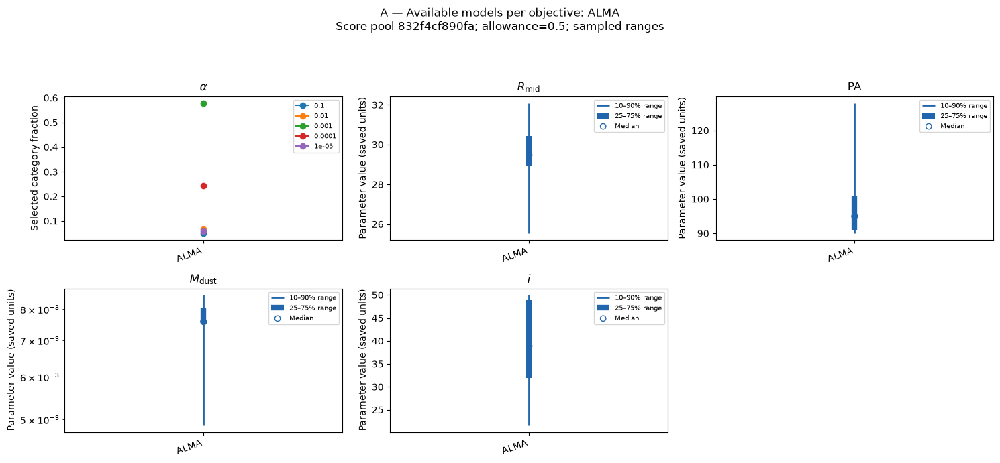

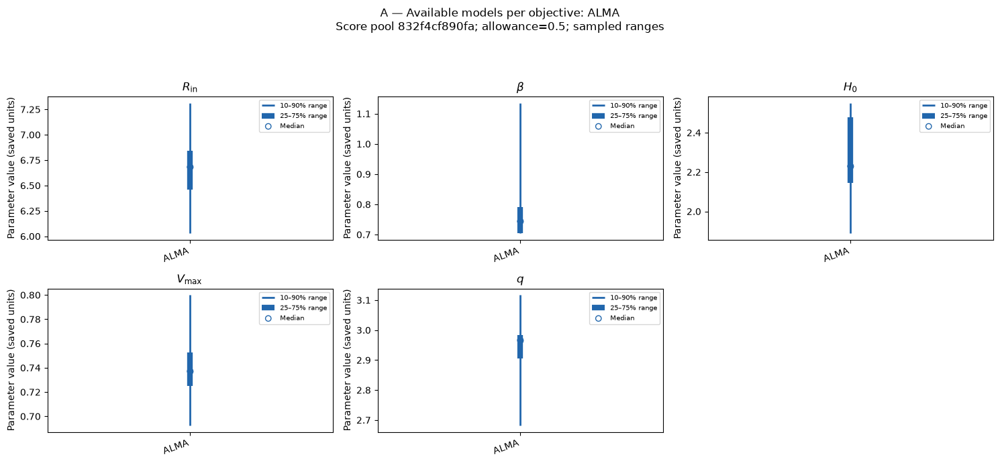

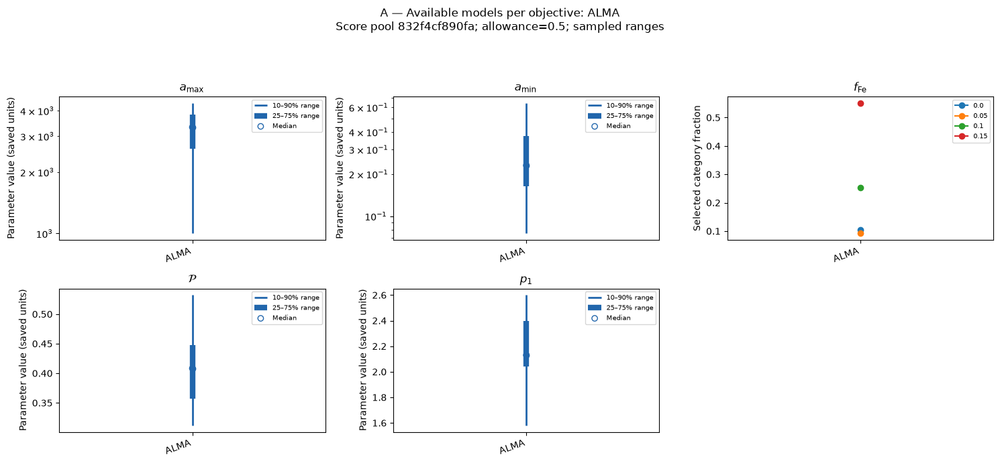

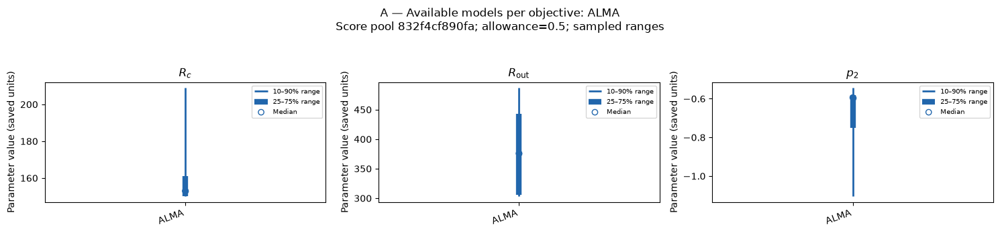

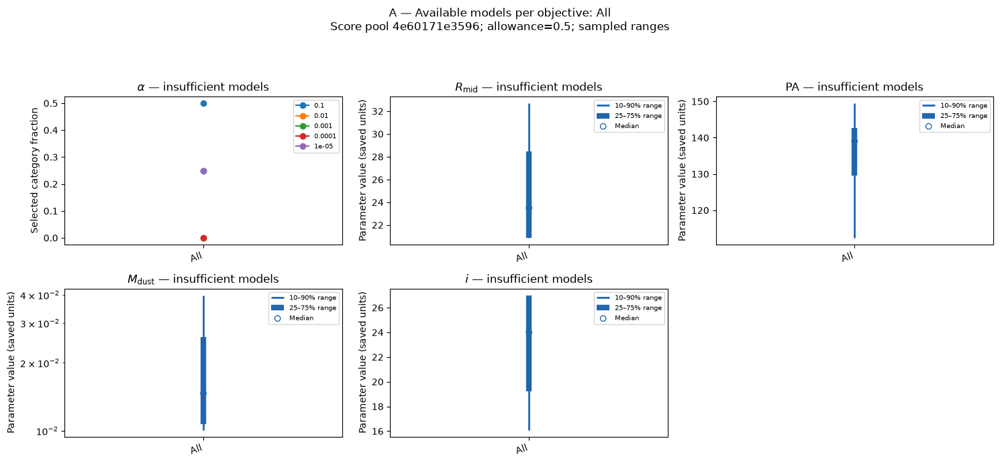

...

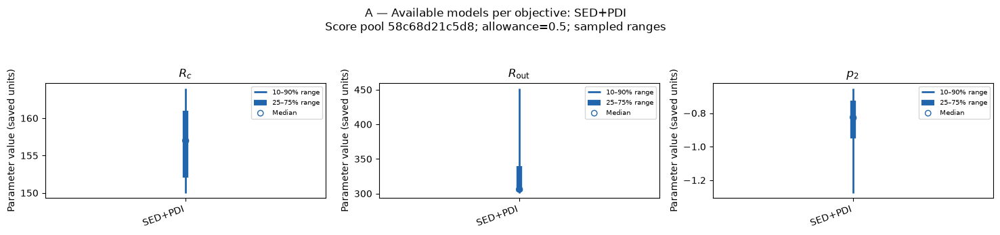

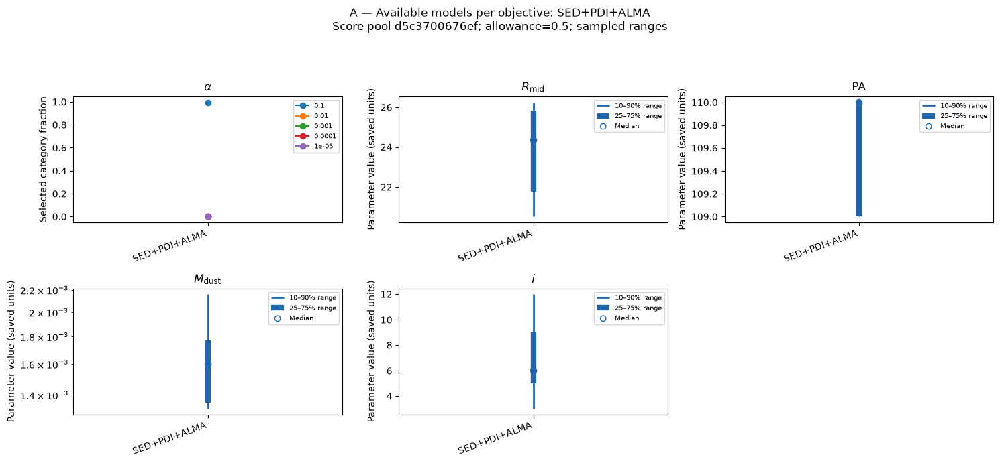

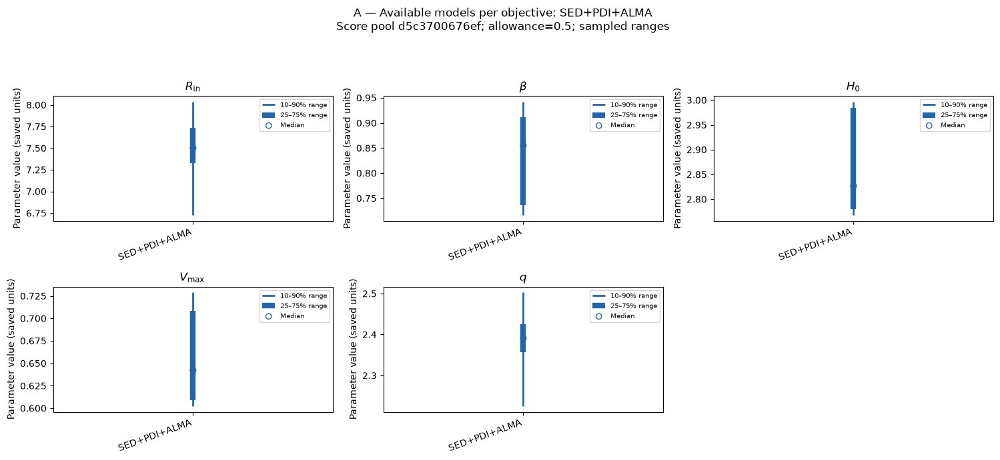

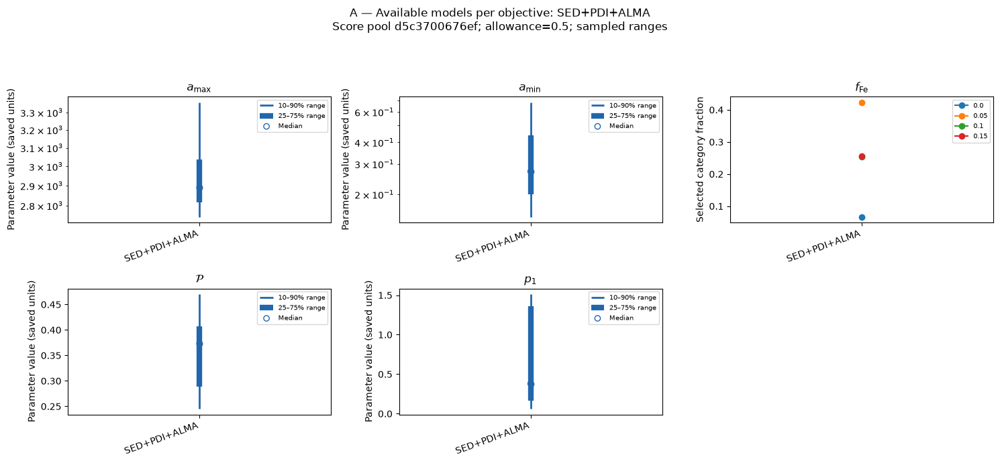

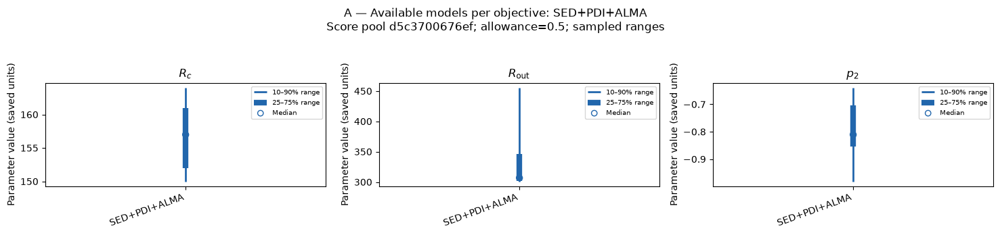

### B — Shared candidates for each comparison

**Winners**

,view,comparison,score_pool_key,selected_by,model_id,objective_score
14,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED,Model 3941,19.925855
15,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED+INT,Model 4642,154.382096
16,shared_per_comparison,SED → SED+PDI,58c68d21c5d81e5e70598830116922aa63327855d638b3...,SED,Model 5509,18.070076
17,shared_per_comparison,SED → SED+PDI,58c68d21c5d81e5e70598830116922aa63327855d638b3...,SED+PDI,Model 5597,156.703066
18,shared_per_comparison,SED → SED+ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,SED,Model 2479,17.494229
19,shared_per_comparison,SED → SED+ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,SED+ALMA,Model 2830,35.606875
20,shared_per_comparison,SED+INT → SED+INT+PDI,66b7dacb87e5f439117f5b815c0a6a59bcee9636bcd942...,SED+INT,Model 1738,204.632617
21,shared_per_comparison,SED+INT → SED+INT+PDI,66b7dacb87e5f439117f5b815c0a6a59bcee9636bcd942...,SED+INT+PDI,Model 3644,518.188818
22,shared_per_comparison,SED+INT → SED+INT+ALMA,533a9a472659940a1555ef852693221eabaf9c88af9778...,SED+INT,Model 3058,180.038262
23,shared_per_comparison,SED+INT → SED+INT+ALMA,533a9a472659940a1555ef852693221eabaf9c88af9778...,SED+INT+ALMA,Model 3058,202.657751


**Counts**

,view,comparison,score_pool_key,objective,n_pool,n_selected,best_score,cutoff
424,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED,2057,21,19.925855,29.888783
425,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED+INT,2057,116,154.382096,231.573144
494,shared_per_comparison,SED → SED+PDI,58c68d21c5d81e5e70598830116922aa63327855d638b3...,SED,2437,72,18.070076,27.105114
495,shared_per_comparison,SED → SED+PDI,58c68d21c5d81e5e70598830116922aa63327855d638b3...,SED+PDI,2437,307,156.703066,235.054599
564,shared_per_comparison,SED → SED+ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,SED,2394,253,17.494229,26.241343
565,shared_per_comparison,SED → SED+ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,SED+ALMA,2394,358,35.606875,53.410312
634,shared_per_comparison,SED+INT → SED+INT+PDI,66b7dacb87e5f439117f5b815c0a6a59bcee9636bcd942...,SED+INT,782,6,204.632617,306.948926
635,shared_per_comparison,SED+INT → SED+INT+PDI,66b7dacb87e5f439117f5b815c0a6a59bcee9636bcd942...,SED+INT+PDI,782,12,518.188818,777.283228
676,shared_per_comparison,SED+INT → SED+INT+ALMA,533a9a472659940a1555ef852693221eabaf9c88af9778...,SED+INT,571,8,180.038262,270.057393
677,shared_per_comparison,SED+INT → SED+INT+ALMA,533a9a472659940a1555ef852693221eabaf9c88af9778...,SED+INT+ALMA,571,10,202.657751,303.986626


**Metrics**

,view,comparison,score_pool_key,objective,parameter,n_pool,n_selected,supported,minimum_in_parameter_units,median_in_parameter_units,maximum_in_parameter_units,category_fractions,best_parameter_values
7632,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED,alpha_viscosity,2057,21,True,NaN,NaN,NaN,"{""0.1"": 0.047619047619047616, ""0.01"": 0.0, ""0....",[0.001]
7633,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED,disk_Rmid,2057,21,True,17.277333,18.568376,39.859877,NaN,[17.9970531227126]
7634,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED,disk_pa,2057,21,True,95.000000,115.000000,158.000000,NaN,[139]
7635,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED,disk_total_dust_mass,2057,21,True,0.000880,0.007291,0.028475,NaN,[0.0008818553725]
7636,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,SED,inclination,2057,21,True,0.000000,1.000000,50.000000,NaN,[37]
...,...,...,...,...,...,...,...,...,...,...,...,...,...
21271,shared_per_comparison,INT+PDI+ALMA → All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,All,zone_1_species_1_porosity,262,4,False,0.091596,0.634496,0.729034,NaN,[0.6283334172519]
21272,shared_per_comparison,INT+PDI+ALMA → All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,All,zone_1_surface_density_exp,262,4,False,1.326847,3.002485,3.348757,NaN,[3.1532412461493]
21273,shared_per_comparison,INT+PDI+ALMA → All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,All,zone_2_Rc,262,4,False,151.000000,209.000000,337.000000,NaN,[209]
21274,shared_per_comparison,INT+PDI+ALMA → All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,All,zone_2_Rout,262,4,False,322.000000,351.000000,427.000000,NaN,[351]


**Effects**

,view,comparison,score_pool_key,parameter,supported,shift,width_ratio,sample_jaccard
36,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,alpha_viscosity,True,0.203612,NaN,0.078740
37,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,disk_Rmid,True,0.133910,0.083405,0.078740
38,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,disk_pa,True,0.087470,0.528846,0.078740
39,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,disk_total_dust_mass,True,0.060689,0.095426,0.078740
40,shared_per_comparison,SED → SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,inclination,True,0.164392,0.175676,0.078740
...,...,...,...,...,...,...,...,...
6853,shared_per_comparison,INT+PDI+ALMA → All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,zone_1_species_1_porosity,False,0.161583,0.778599,0.428571
6854,shared_per_comparison,INT+PDI+ALMA → All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,zone_1_surface_density_exp,False,0.152695,0.623982,0.428571
6855,shared_per_comparison,INT+PDI+ALMA → All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,zone_2_Rc,False,0.097500,0.845455,0.428571
6856,shared_per_comparison,INT+PDI+ALMA → All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,zone_2_Rout,False,0.251389,0.342657,0.428571


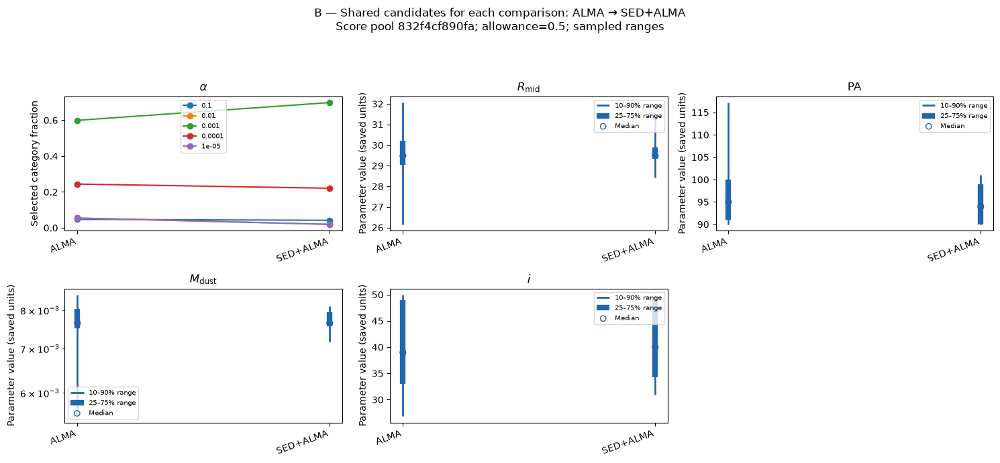

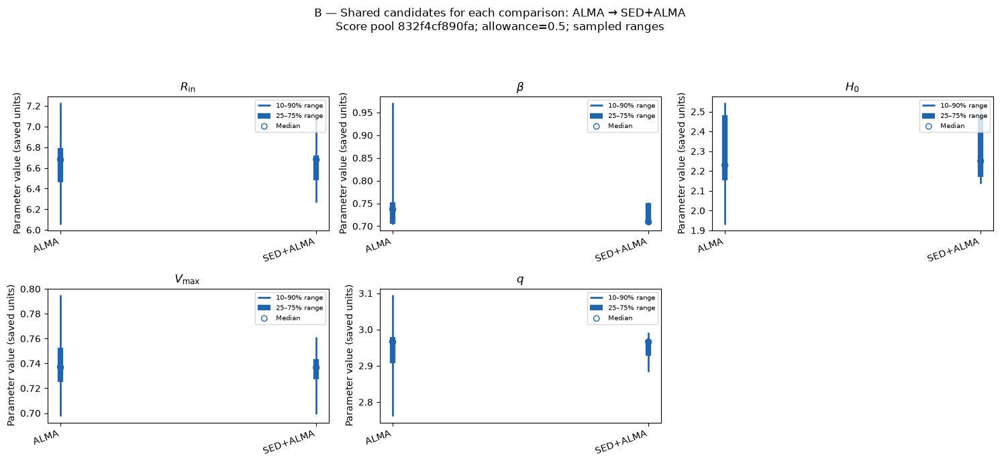

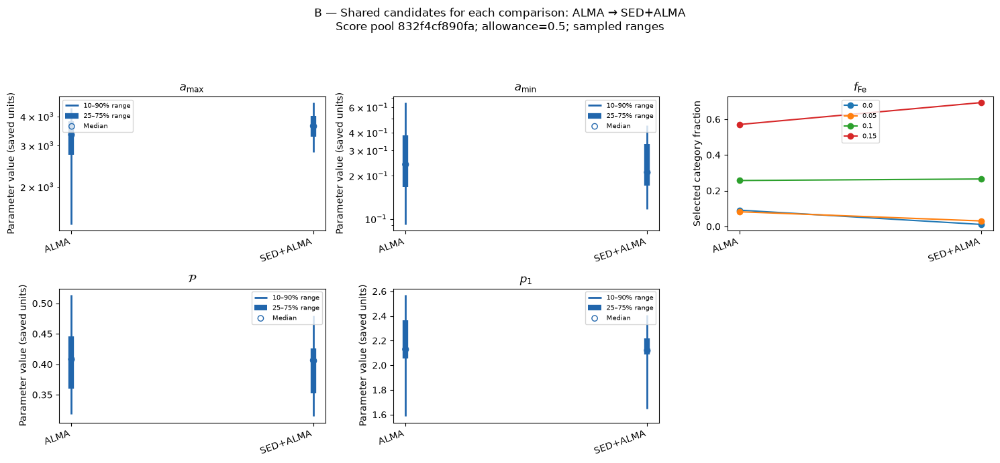

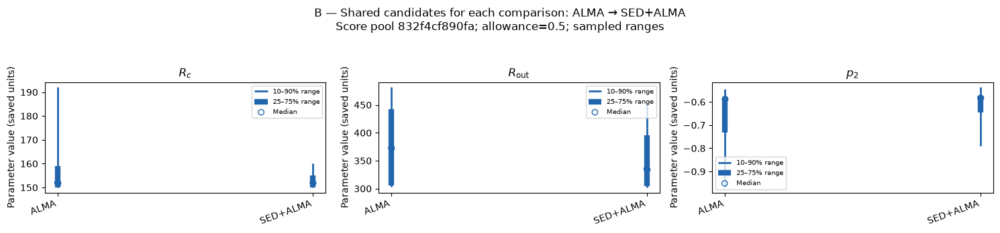

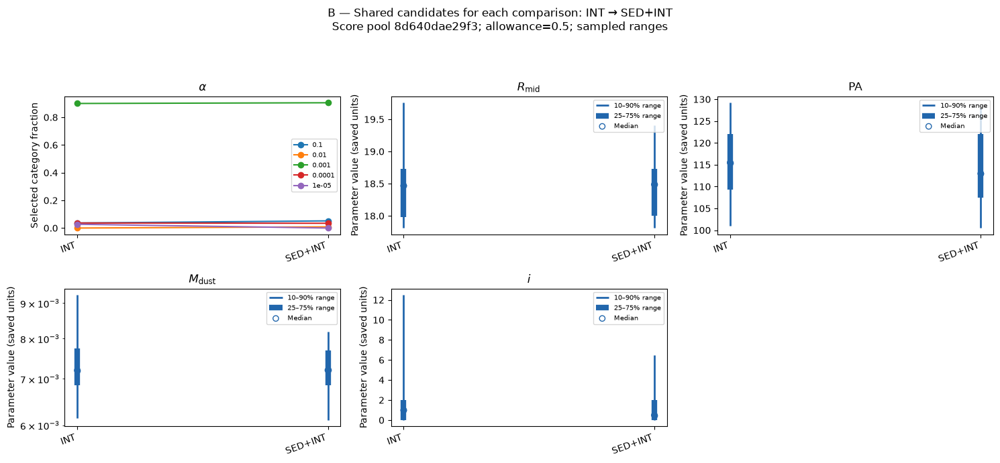

...

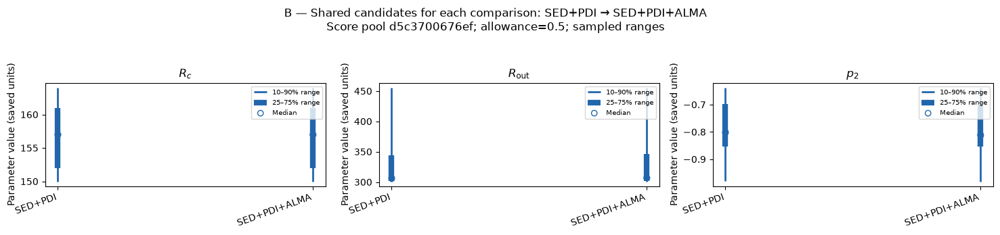

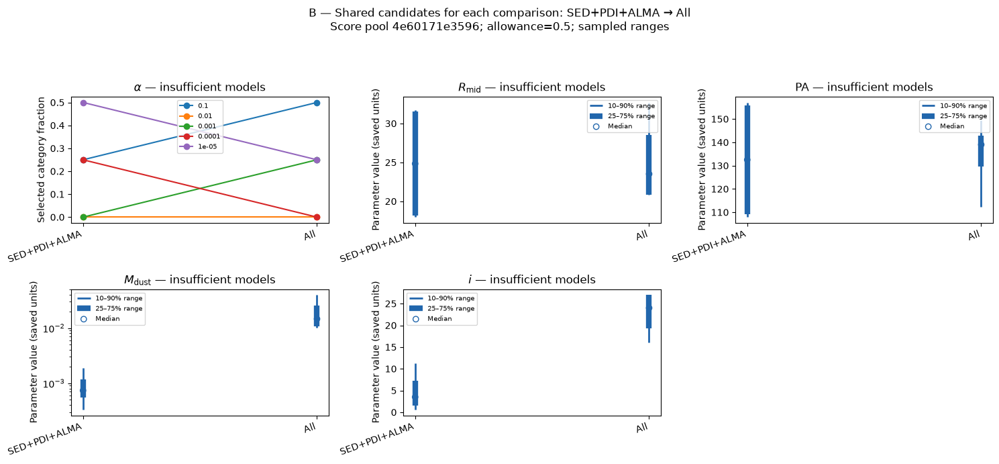

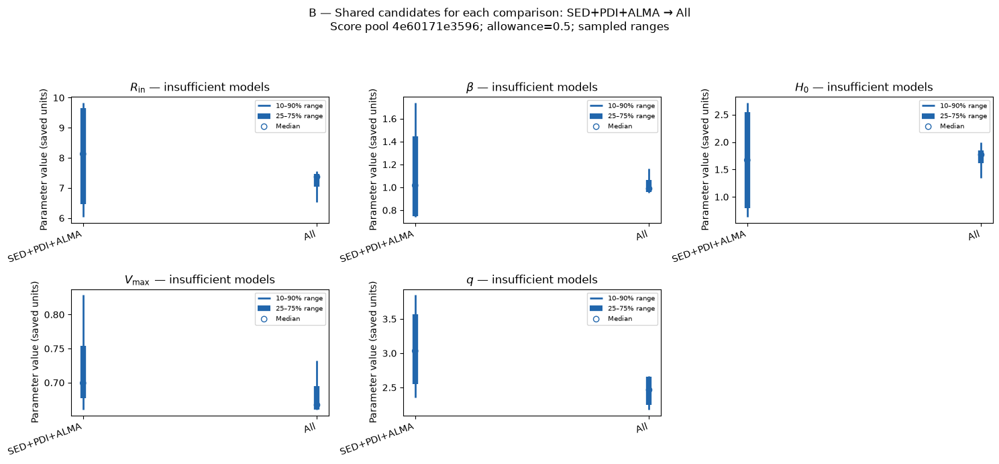

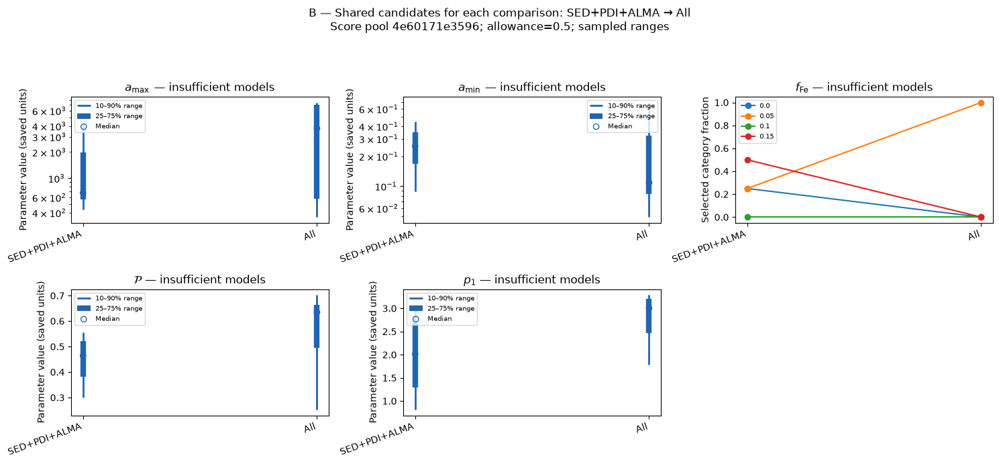

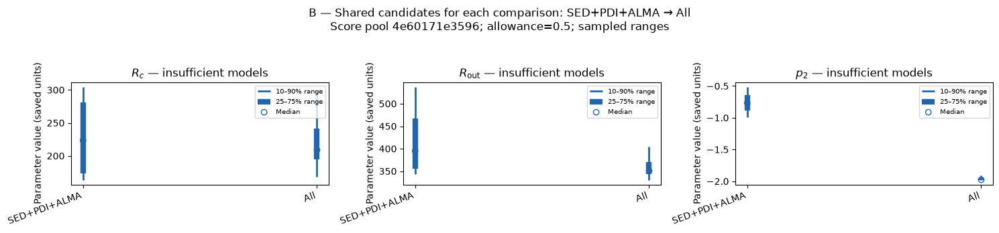

In [4]:
eligible_candidates = eligible_pool_candidates(evaluations, inventory, records)
if eligible_candidates.empty:
    raise ValueError('No eligible final-budget evaluations with known physical metadata and consistent native costs.')
physical_pool_inventory = eligible_candidates.groupby('physical_pool').agg(
    n=('evaluation_id','size'), unique_parameters=('parameter_hash','nunique'),
    histories=('history','nunique'), physical_pool_key=('physical_pool_key','first'))
display(physical_pool_inventory)
selected_physical_pool = POOL_ID if POOL_ID is not None else physical_pool_inventory.n.idxmax()
if selected_physical_pool not in physical_pool_inventory.index:
    raise ValueError('POOL_ID must match a Physical pool label in physical_pool_inventory.')
base_candidates = eligible_candidates.loc[
    eligible_candidates.physical_pool.eq(selected_physical_pool)].copy().reset_index(drop=True)
definitions = {item['name']:item for item in configspaces[base_candidates.history.iloc[0]]['hyperparameters']}
view_parameters = PARAMETERS if PARAMETERS is not None else [c[7:] for c in base_candidates
    if c.startswith('param__') and definitions.get(c[7:],{}).get('type') != 'constant'
    and base_candidates[c].nunique(dropna=True)>1
    and not base_candidates[c].dropna().map(lambda x:isinstance(x,str) and 'param__'+x in base_candidates).any()]
view_references = {name:parameter_reference(base_candidates,name,definitions[name],
    period=None,bins=HISTOGRAM_BINS) for name in view_parameters}
# Physical meanings accompany this pool's actual recorded parameter definitions.
parameter_guide = pd.DataFrame([
    dict(parameter=name, meaning=parameter_description(name),
         recorded_type=definitions[name].get('type'),
         lower=definitions[name].get('lower'), upper=definitions[name].get('upper'),
         choices=definitions[name].get('choices', definitions[name].get('sequence')),
         coordinates=view_references[name]['kind'])
    for name in view_parameters
])
display(parameter_guide)
view_selection_levels = {'allowance':sorted(set(RELATIVE_ALLOWANCES+[DISPLAY_ALLOWANCE])),
                         'fraction':sorted(set(MATCHED_FRACTIONS+[DISPLAY_FRACTION]))}
pool_views = analyse_pool_views(base_candidates,records,objective_design(),definitions,
    view_references,view_selection_levels,ABSOLUTE_ALLOWANCE,MIN_MODELS)
pool_views['parameter_guide'] = parameter_guide
display(pool_views['availability'])
for view, label in [('available_per_objective','A — Available models per objective'),
                    ('shared_per_comparison','B — Shared candidates for each comparison')]:
    display(Markdown('### '+label))
    for name in ['winners','counts','metrics','effects']:
        table=pool_views[name]
        if table.empty:
            continue
        table=table.loc[table.view.eq(view)]
        if 'scope' in table:
            table=table.loc[table.scope.eq('pooled') & table['mode'].eq('allowance')
                            & np.isclose(table.level,DISPLAY_ALLOWANCE)]
        columns=[c for c in ['view','comparison','score_pool_key','selected_by','model_id',
            'objective_score','objective','parameter','n_pool','n_selected','supported','best_score',
            'cutoff','minimum_in_parameter_units','median_in_parameter_units','maximum_in_parameter_units',
            'category_fractions','best_parameter_values','shift','width_ratio','sample_jaccard'] if c in table]
        display(Markdown('**'+name.capitalize()+'**'))
        display(table[columns])
    data=pool_views['metrics']
    if data.empty:
        continue
    data=data.loc[data.view.eq(view) & data.scope.eq('pooled')]
    for group_index,((comparison,key),rows) in enumerate(data.groupby(['comparison','score_pool_key']),1):
        order={name:i for i,name in enumerate(rows.objective.unique())}
        rows=rows.assign(step=rows.objective.map(order),subset=rows.objective)
        for first in range(0,len(view_parameters),5):
            fig=plot_restriction(rows,view_parameters[first:first+5],'allowance',DISPLAY_ALLOWANCE)
            if fig is not None:
                fig.suptitle(f'{label}: {comparison}\nScore pool {key[:12]}; allowance={DISPLAY_ALLOWANCE:g}; sampled ranges')
                fig.tight_layout(rect=(0,0,1,.92))
            show(f'{view}_{group_index:02d}_{first}',fig)
# Full tables retain both selection modes, every allowance and within-history controls.


## 4. View A — original score versus each parameter

Each page belongs to one objective and compatible pool. It includes all eligible evaluations in that pool, with nested score-allowance highlights controlled by `VIEW_A_COST_ALLOWANCES`. Legend counts include ties and overlaps; the dashed lines show the actual cutoffs.

`VIEW_A_PANELS_PER_PAGE` sets pagination. Numeric axes follow recorded linear/log coordinates; categories occupy separate slots. The score axis is logarithmic when all displayed scores are positive. Invalid parameter values are omitted only from their panel and counted in coverage.

Use these plots to locate sampled low-score regions and gaps in search coverage. Their dense regions also reflect where SMAC searched. This full-pool view complements the separately filtered weighted plots below.


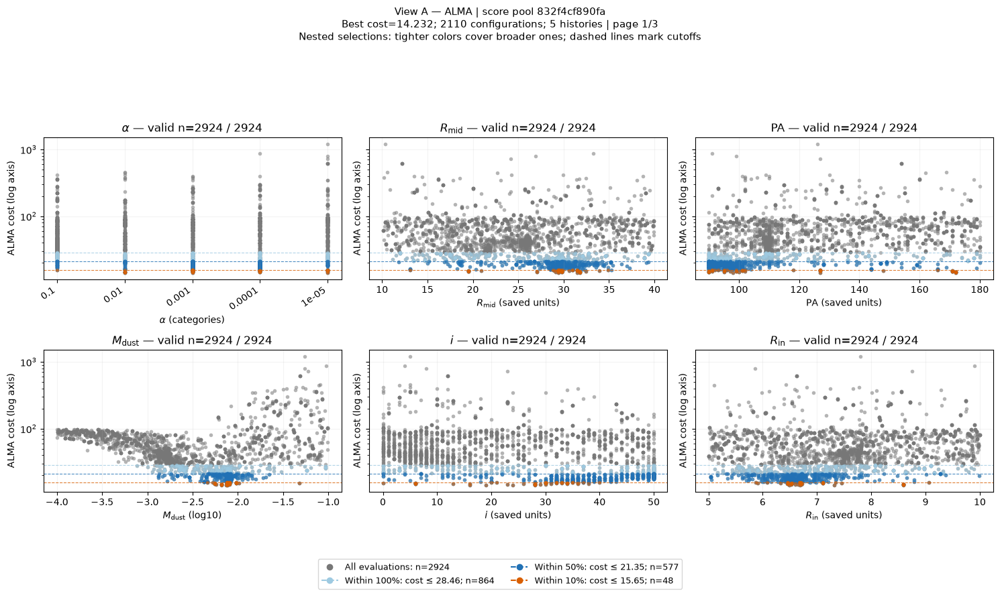

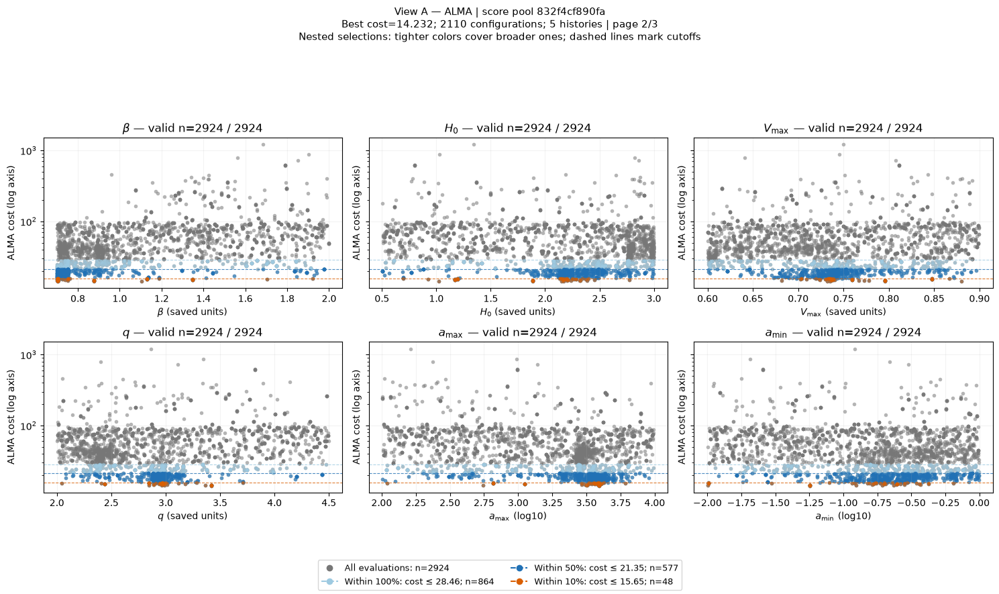

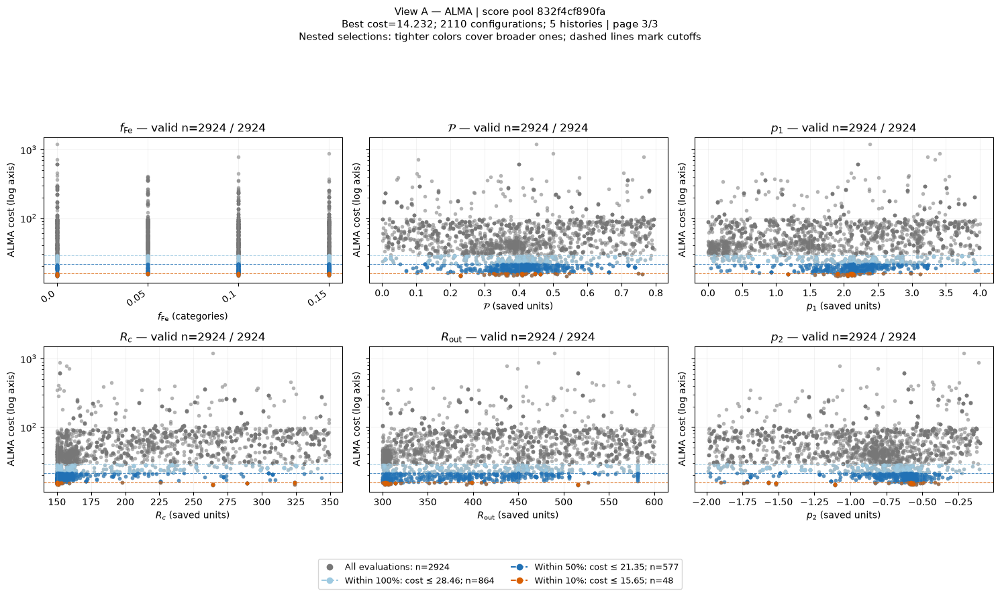

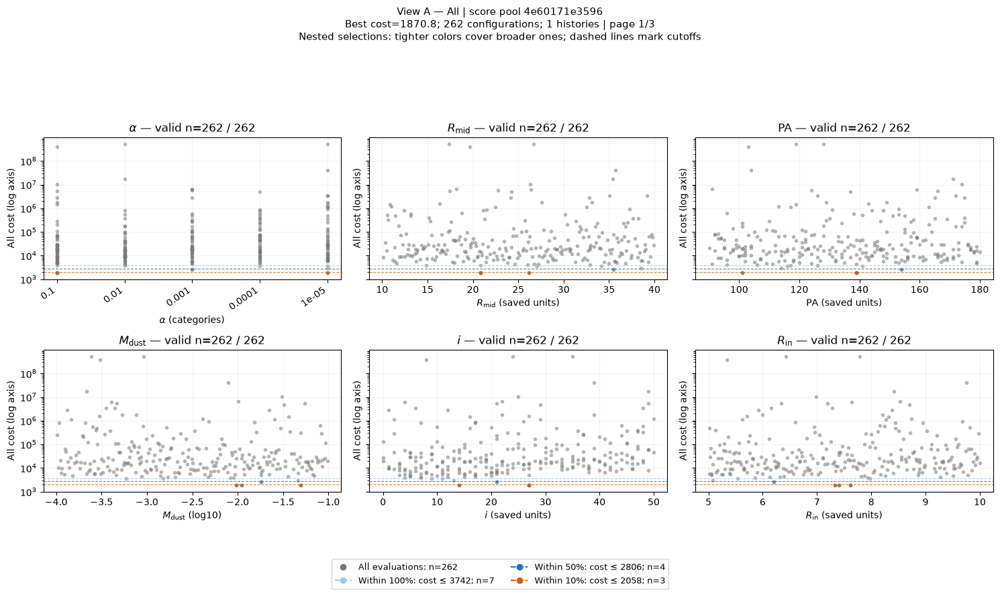

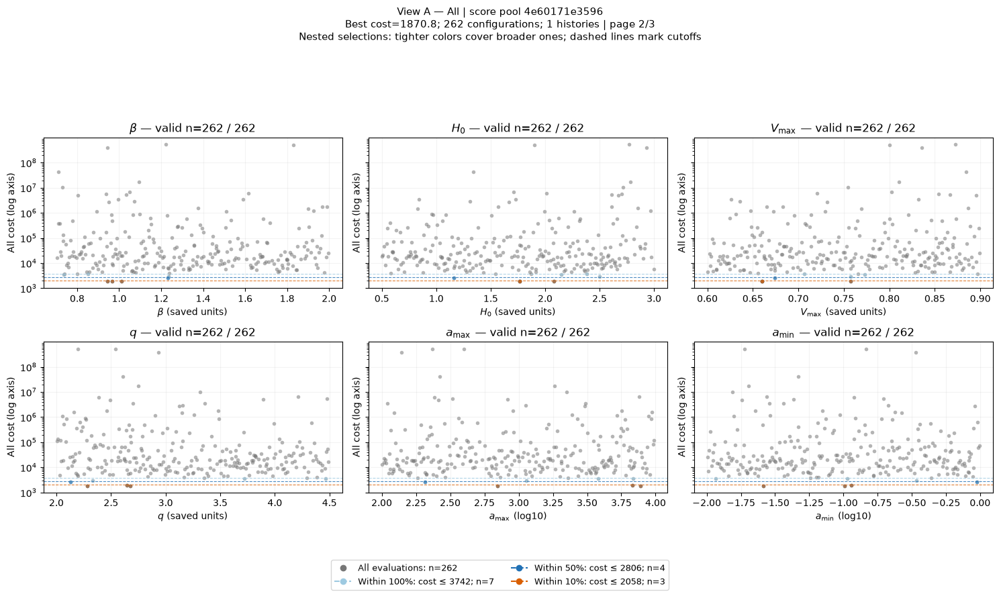

...

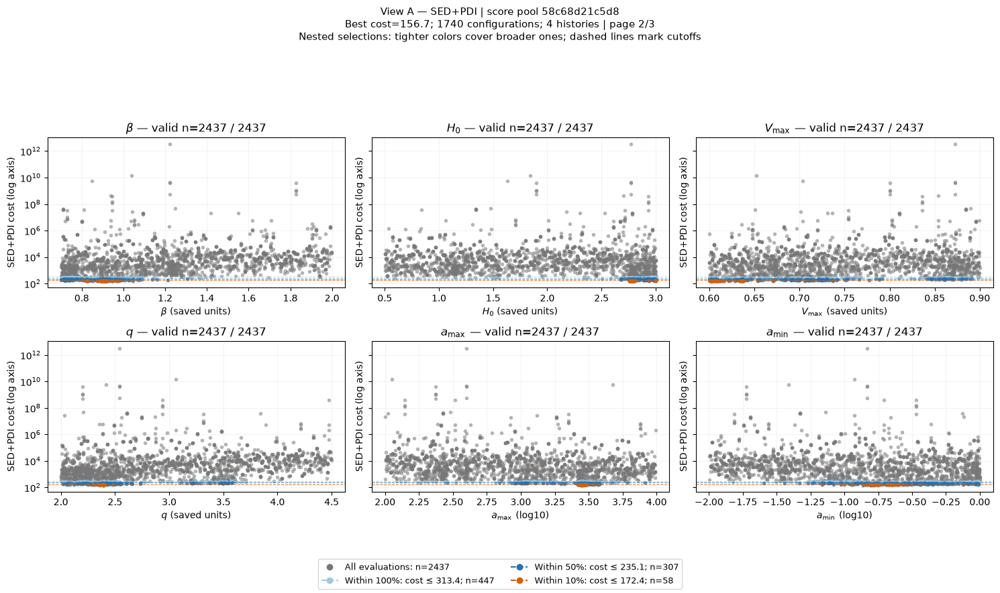

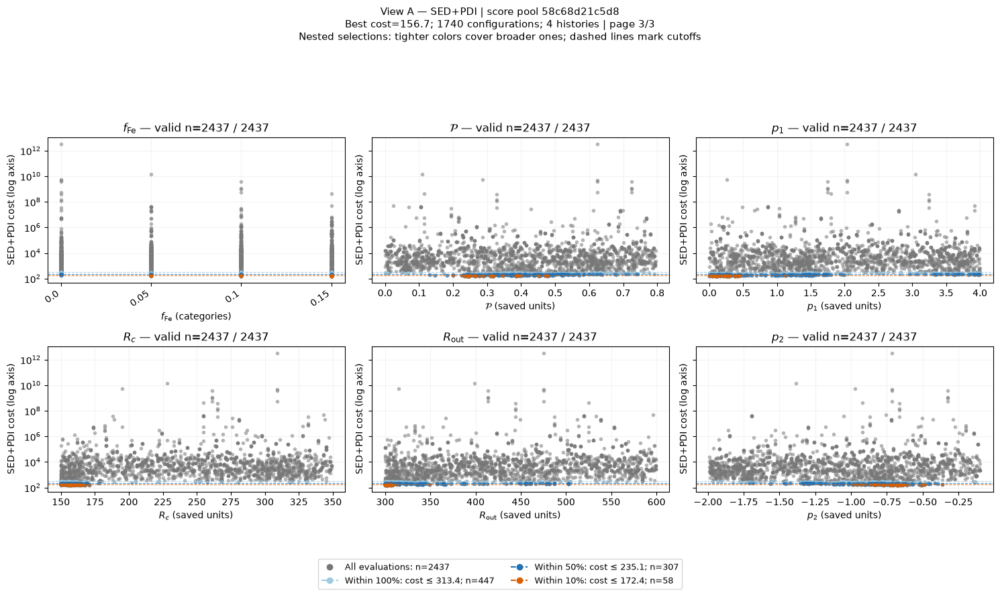

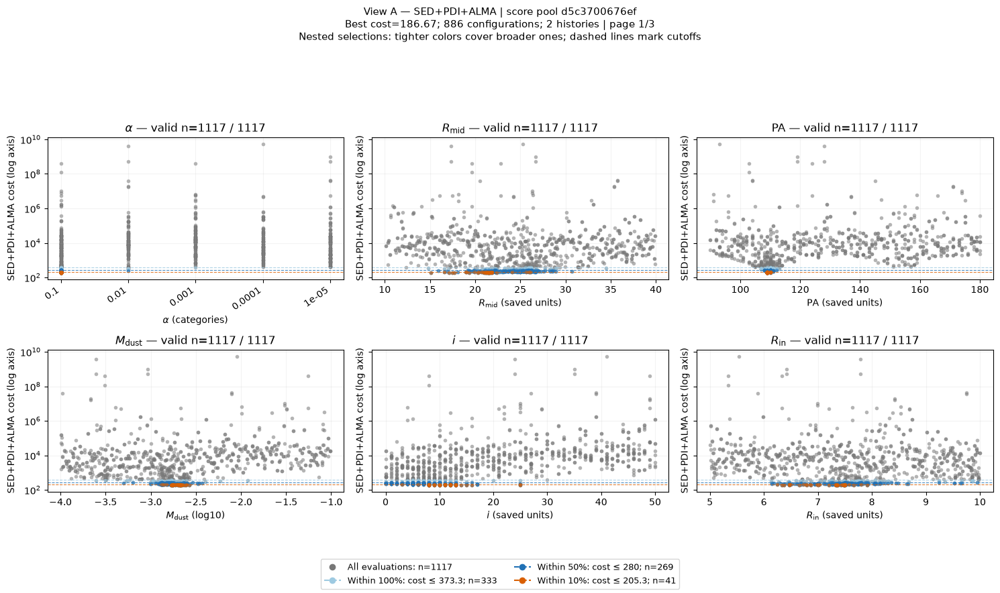

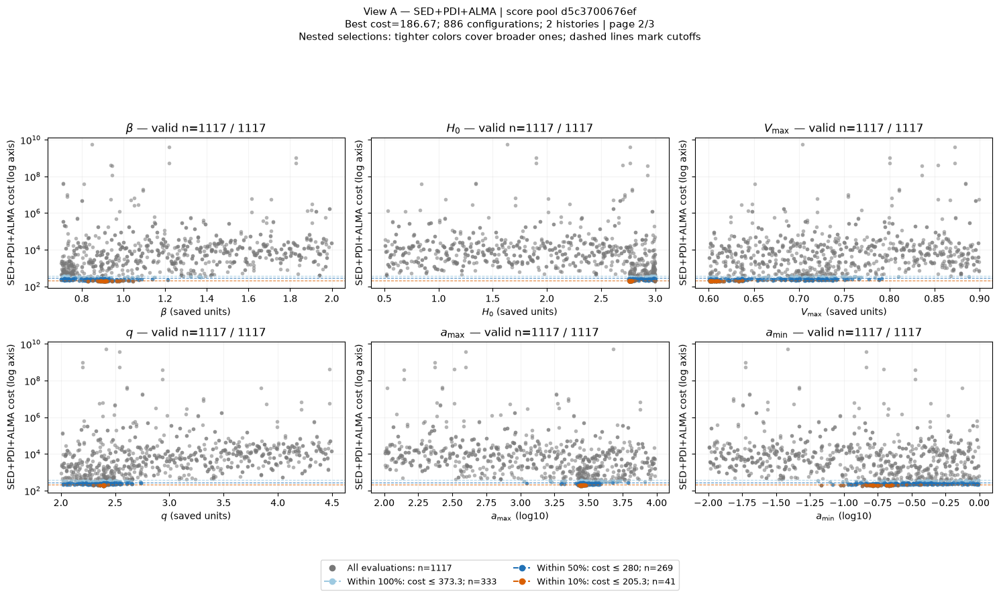

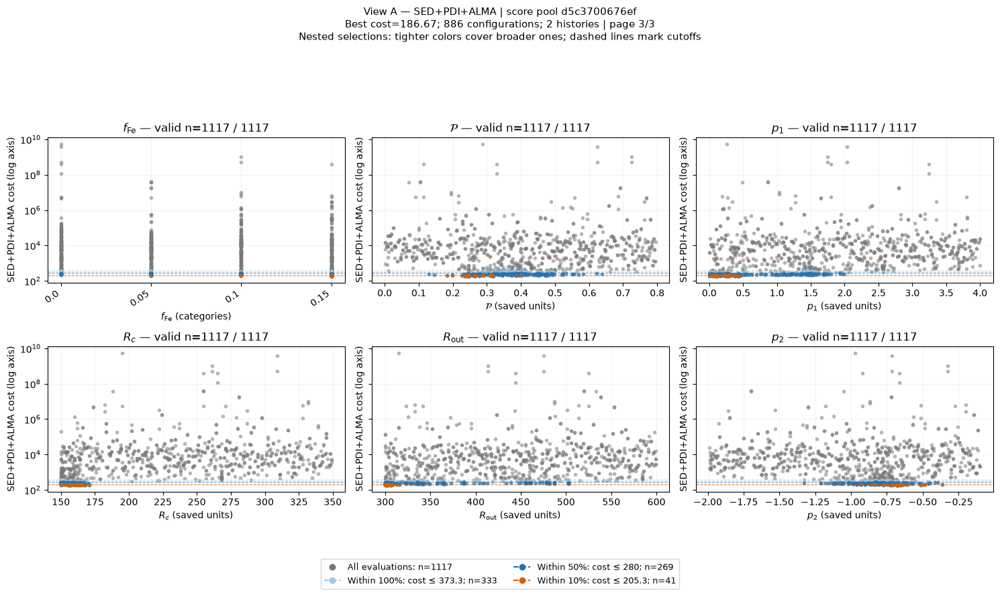

,objective,score_pool_key,allowance,best_score,cutoff,n_pool,n_selected,n_unique_configurations,n_histories
0,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,1.0,14.231622,28.463245,2924,864,2110,5
1,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,0.5,14.231622,21.347434,2924,577,2110,5
2,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,0.1,14.231622,15.654785,2924,48,2110,5
3,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,1.0,1870.782329,3741.564658,262,7,262,1
4,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,0.5,1870.782329,2806.173493,262,4,262,1
5,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,0.1,1870.782329,2057.860562,262,3,262,1
6,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,1.0,109.038315,218.076630,2587,218,1548,5
7,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,0.5,109.038315,163.557472,2587,110,1548,5
8,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,0.1,109.038315,119.942146,2587,1,1548,5
9,INT+PDI+ALMA,4e60171e35965935ca56d63f9b7813b84aec394147db95...,1.0,1239.506152,2479.012303,367,14,262,2


In [5]:
# Use all independent varied model parameters, even if PARAMETERS filters other summaries.
cost_parameters = [c[7:] for c in base_candidates if c.startswith('param__')
    and c[7:] in definitions and definitions[c[7:]].get('type') != 'constant'
    and not base_candidates[c].dropna().map(lambda x:isinstance(x,str) and 'param__'+x in base_candidates).any()]
cost_references = {name:parameter_reference(base_candidates,name,definitions[name],
    period=None,bins=HISTOGRAM_BINS) for name in cost_parameters}
cost_cutoff_parts, cost_coverage_parts = [], []
view_a_members = pool_views['members']
if not view_a_members.empty:
    view_a_members = view_a_members.loc[view_a_members.view.eq('available_per_objective')]
    for group_index,((objective,key),candidates) in enumerate(
            view_a_members.groupby(['comparison','score_pool_key'],sort=True),1):
        candidates=candidates.reset_index(drop=True)
        pages,cutoffs,coverage_rows=plot_available_pool_costs(candidates,objective,
            objective_design()[objective],cost_references,VIEW_A_COST_ALLOWANCES,
            VIEW_A_PANELS_PER_PAGE,POINT_SIZE,POINT_ALPHA)
        cost_cutoff_parts.append(cutoffs)
        cost_coverage_parts.append(coverage_rows)
        for page,fig in enumerate(pages,1):
            show(f'available_per_objective_costs_{group_index:02d}_{page:02d}',fig)
pool_views['cost_cutoffs']=pd.concat(cost_cutoff_parts,ignore_index=True) if cost_cutoff_parts else pd.DataFrame()
pool_views['cost_panel_coverage']=pd.concat(cost_coverage_parts,ignore_index=True) if cost_coverage_parts else pd.DataFrame()
display(pool_views['cost_cutoffs'])


## 5. View A — descriptive score-weighted distributions

For each objective and compatible pool, retain the lowest-scoring fraction set by `SCORE_WEIGHTED_RETAIN_FRACTION` (currently configured in the settings cell). Cutoff ties remain included. This is a fraction **by count**, applied before checking parameter completeness.

Assign each retained evaluation the descriptive weight
\[
w_i \propto \exp[-(J_i-J_{\min})/T],\qquad
T=\Delta J_{1/2}/\ln 2.
\]
A score increase of `delta` therefore halves the weight. Repeated evaluations receive separate baseline mass. The weights describe the retained search sample, not a posterior.

| Controls | What they define |
|---|---|
| `SCORE_WEIGHTED_OBJECTIVES` | Objectives to plot; `None` includes all available objectives, with separate compatible pools. |
| `SCORE_WEIGHTED_PARAMETERS` | Independent parameters to include, separately from `PARAMETERS`; `None` includes all available independent parameters. |
| `SCORE_WEIGHTED_PARAMETER_GROUPS` | Physical grouping of axes. `None` uses the helper's mapping; the actual assignment table is displayed and exported. Unassigned names remain in “Other parameters”. |
| `SCORE_WEIGHTED_HALF_WEIGHT_FRACTIONS` | Each fraction `f` sets `delta = f * abs(best score)` for that objective/pool. |
| `SCORE_WEIGHTED_ABSOLUTE_DELTAS` | Optional deltas in original score units, keyed by objective or `(objective, pool key)`; these replace the relative deltas. Required if the best score is zero. |
| `SCORE_WEIGHTED_STYLE`, `SCORE_WEIGHTED_REFERENCE_SETTING` | A single reference-style chain, or sensitivity overlays. `None` selects the middle configured weighting for reference style. |
| `SCORE_WEIGHTED_COLOR_SCALE` | Colour by original objective score: `auto` uses log for positive varying scores, otherwise linear. |
| `SCORE_WEIGHTED_CONTOUR_MASSES` | Fractions of plotted weight enclosed by 2D contours. |
| `SCORE_WEIGHTED_BINS`, `SCORE_WEIGHTED_SMOOTH` | Histogram resolution and Gaussian smoothing; smoothing can change visible peaks and bands. |
| `SCORE_WEIGHTED_MIN_ESS` | Minimum weight-concentration support for curves, checked over evaluations and configurations. This is not an independent-sample count. |

**Choosing delta:** the relative settings are a reproducible display experiment, not measured errors. For ALMA, delta=1 means a 0.01 increase in residual energy divided by observed energy, not a 1% flux error. PDI's weighted summary loss has no universal noise-based delta. An absolute tolerance should describe an acceptable increase in that saved objective. Combined objectives use one T on the original sum. Changing a relative score's zero point changes the relative-temperature rule; a fixed absolute delta avoids that dependence.

SED and INT scores are chi-square-based, but these descriptive weights are not Gaussian likelihood weights. For fixed errors, likelihood ratios require unreduced chi-square; SED uses N−1 normalisation and INT sums separately normalised instrument terms. The notebook does not convert those saved losses into likelihoods.

**Reading the figures:**
- Colour shows the original score, with brighter magma colours and a labelled colour scale. Equal-size points are evaluated locations, not weight-resampled points.
- Black contours enclose the configured weight masses. Marginals use `multimodal=True` with HDI summaries: the 68% mass applies to the displayed bands together. Exports record individual bands and their centre convention; these are not overall-median intervals or calibrated uncertainties.
- The star/dashed lines identify one lowest-score displayed evaluation. Ties use sorted evaluation IDs. This is a current sampled reference, not a known truth or final model.
- All groups share the same selected candidates and numeric complete-case mask. Categories use weighted bars and additionally require valid category values. Constants, missing values, omitted weight and support are reported.
- Grouped corners show within-group pairs only. Cross-group associations remain available in the supplemental analysis.

Types, bounds and ties come from each selected pool. For example, seed1 varies `Vmax` and porosity continuously, while some older runs use categories. Shared zone properties and derived zone masses are not added as axes. Changing the grouping does not change the selected model setup.

The selection, membership, weighting, temperatures, group assignment and coverage tables are exported separately. `reference` displays one weighting; `sensitivity` overlays the configured weightings. Check whether visible features persist across useful nearby settings before interpreting them physically. ChainConsumer is imported only for plotting; the installed version must support multimodal HDI summaries.


,parameter_group,parameter,coordinates
0,Disc geometry and orientation,inclination,linear
1,Disc geometry and orientation,disk_pa,linear
2,Disc geometry and orientation,disk_Rmid,linear
3,Disc geometry and orientation,zone_1_Rin,linear
4,Disc geometry and orientation,zone_1_scale_height,linear
5,Disc geometry and orientation,zone_1_flaring_exp,linear
6,Disc geometry and orientation,zone_1_surface_density_exp,linear
7,Disc geometry and orientation,zone_2_Rout,linear
8,Disc geometry and orientation,zone_2_Rc,linear
9,Disc geometry and orientation,zone_2_surface_density_exp,linear


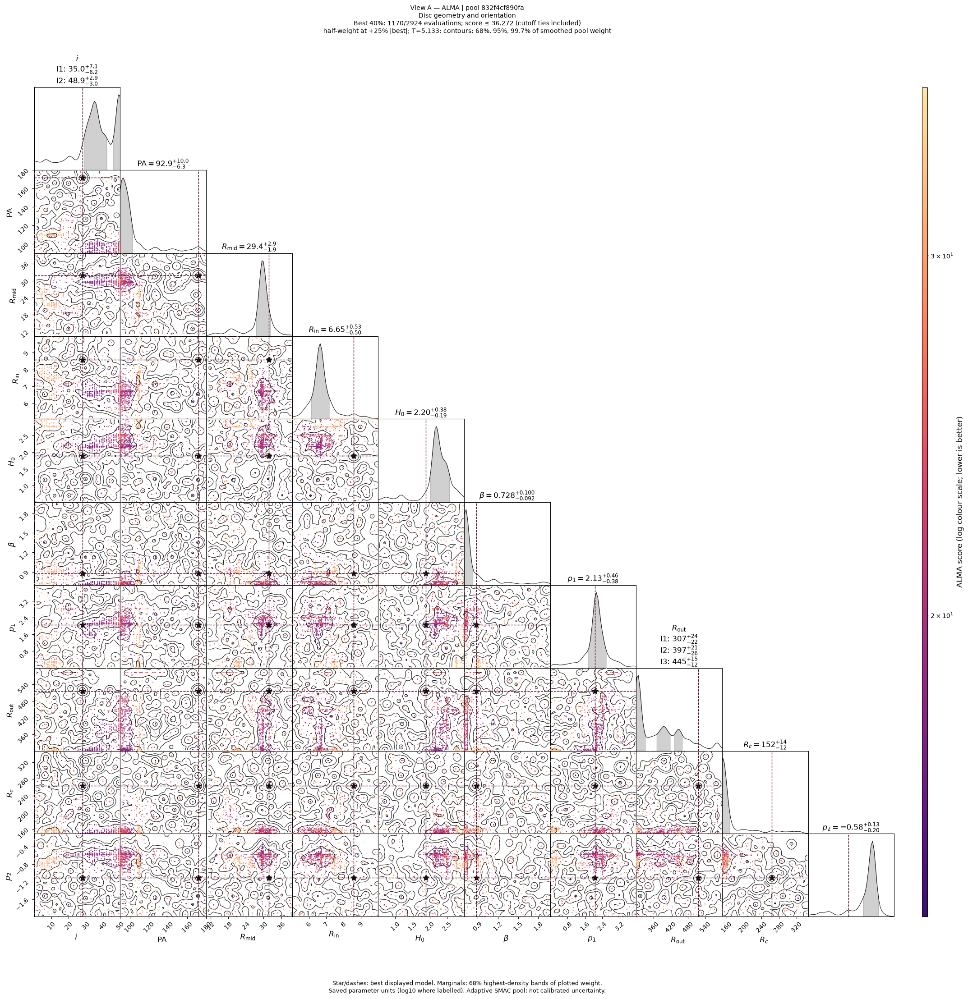

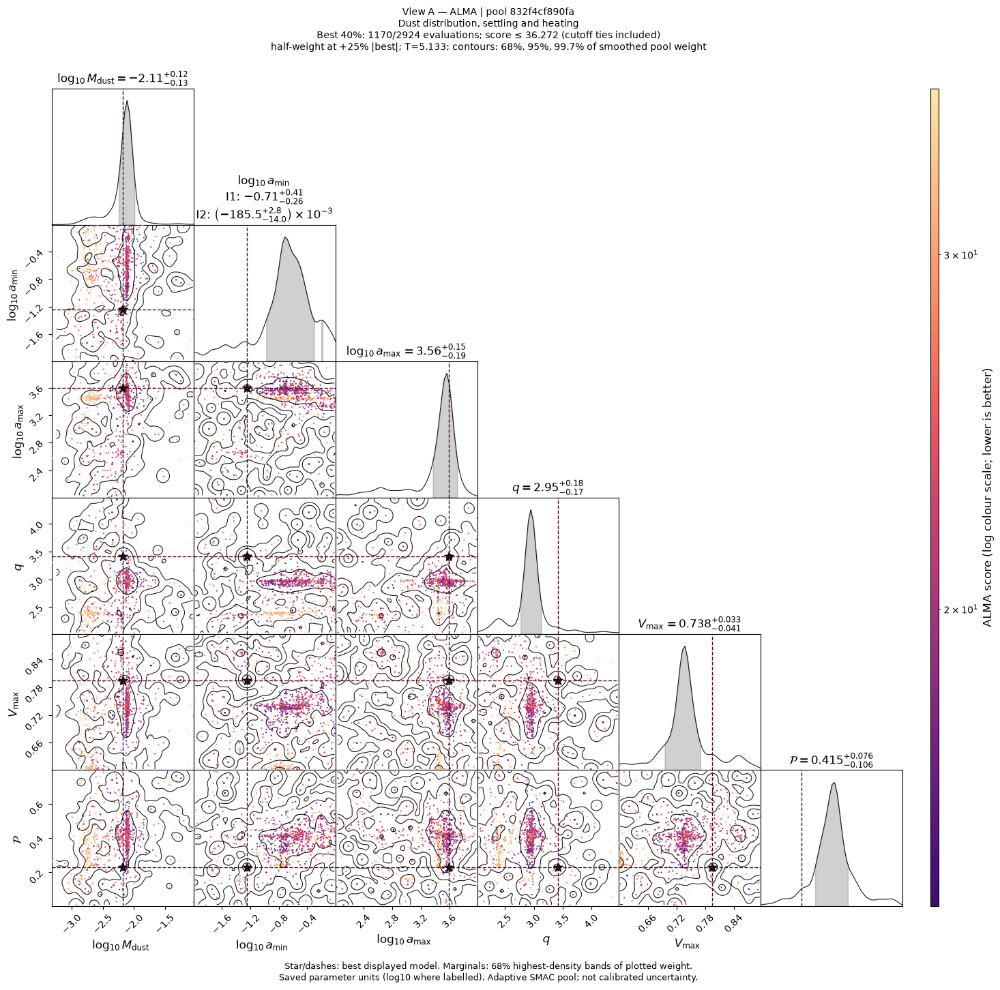

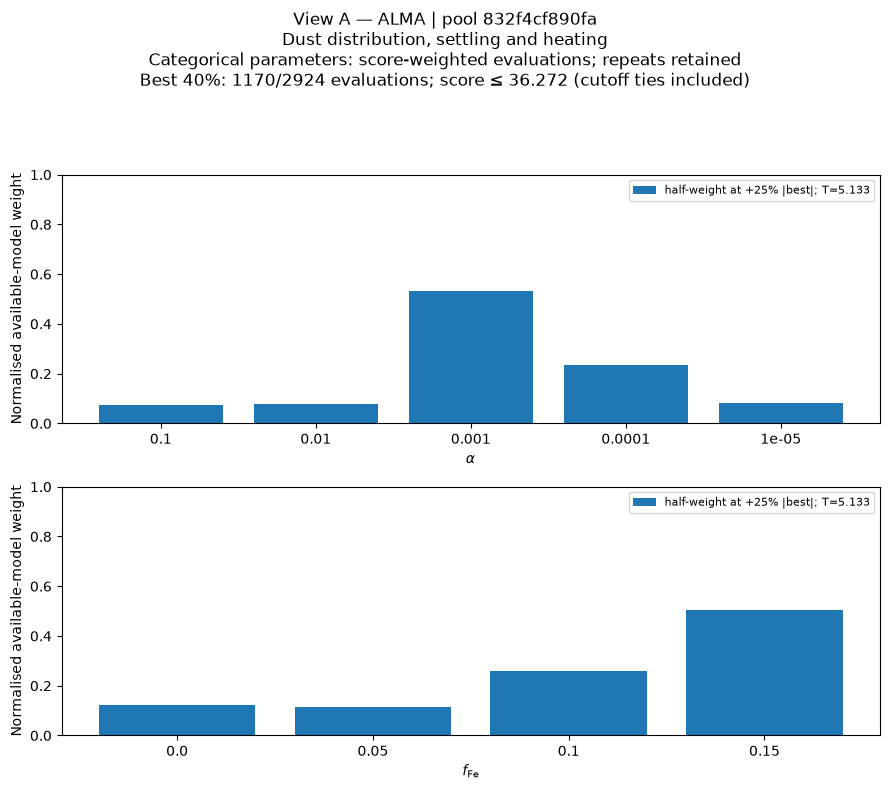

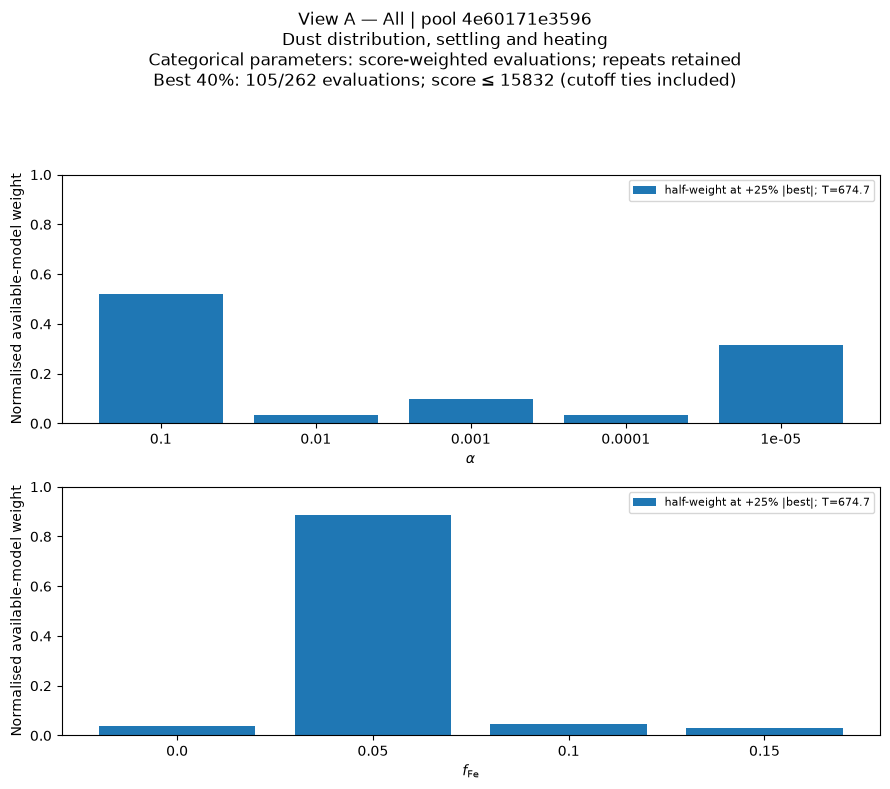

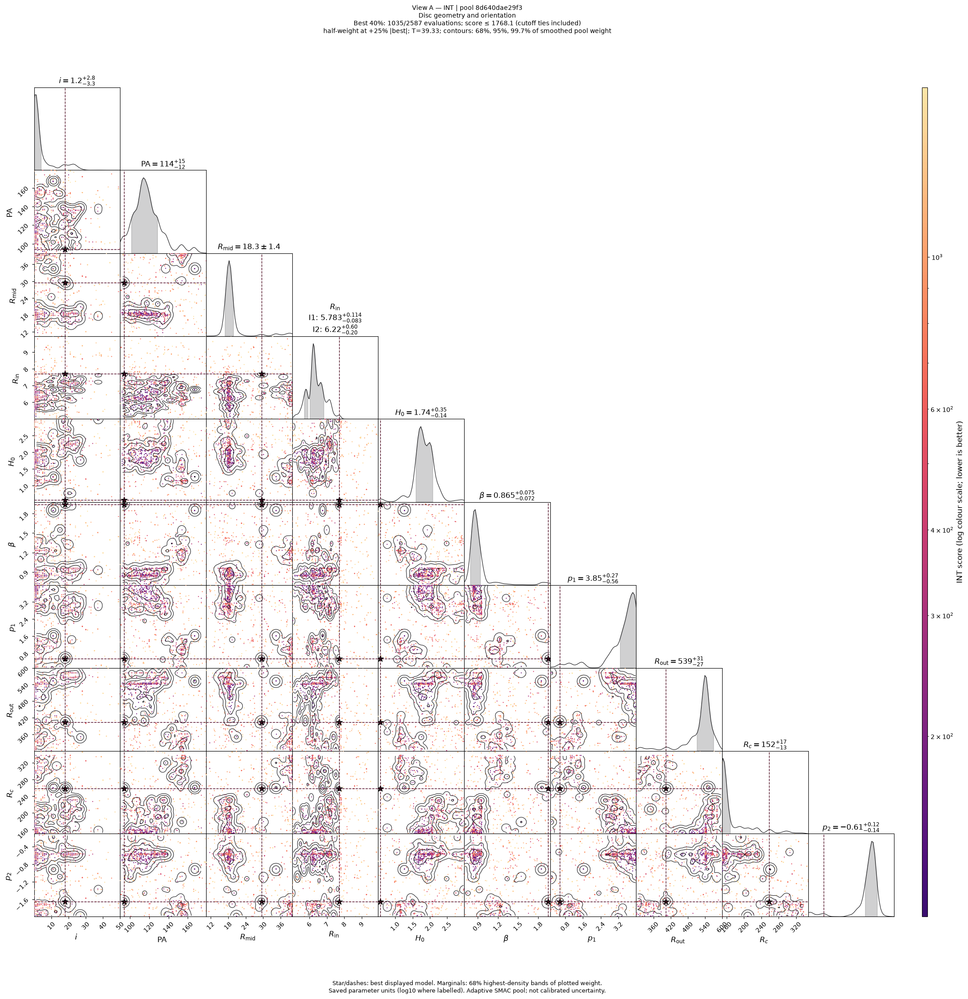

...

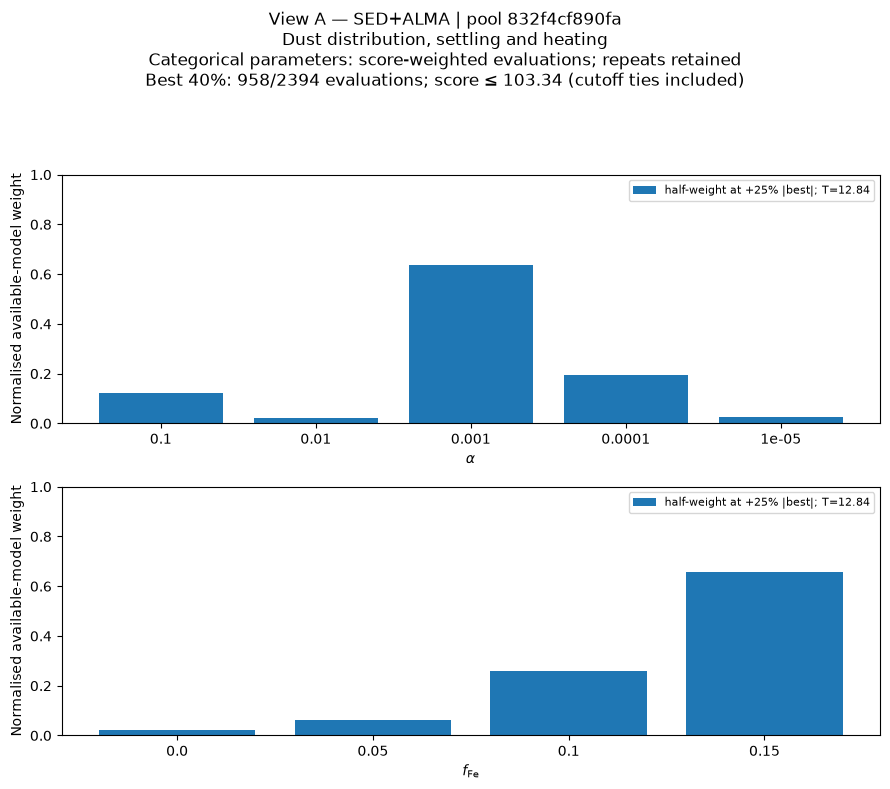

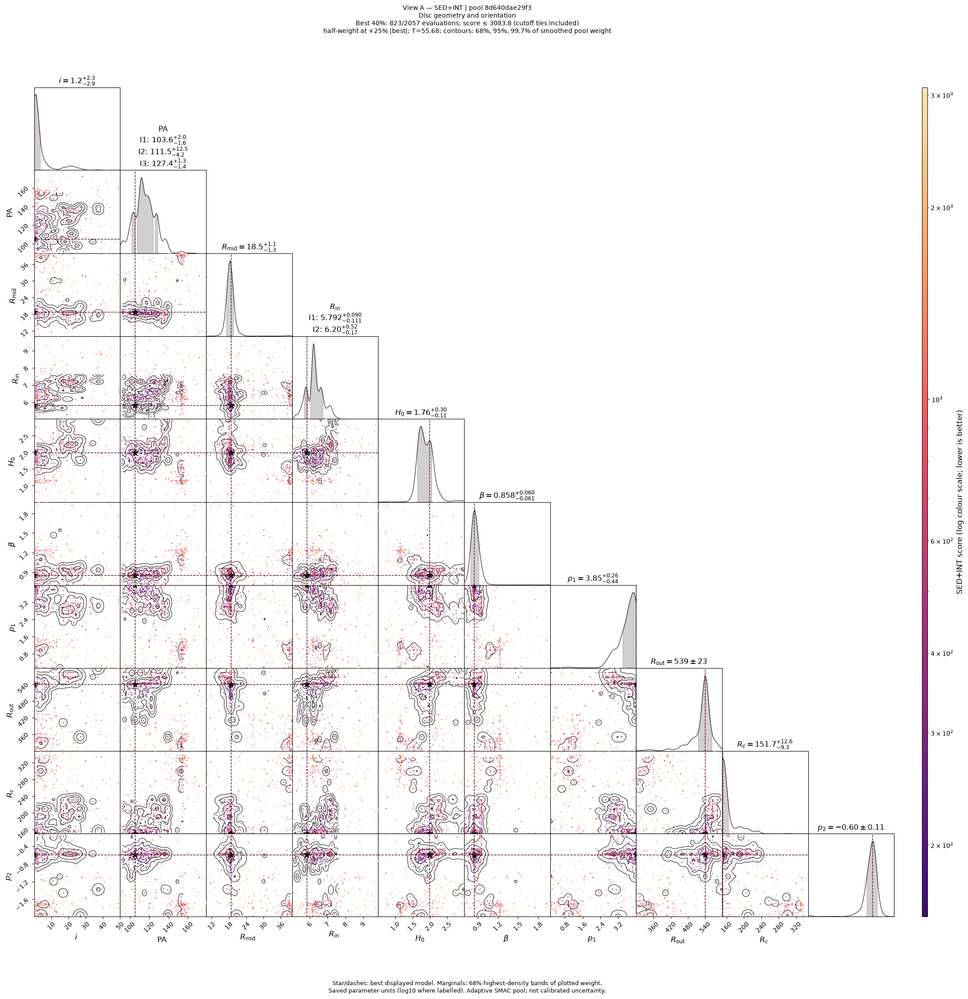

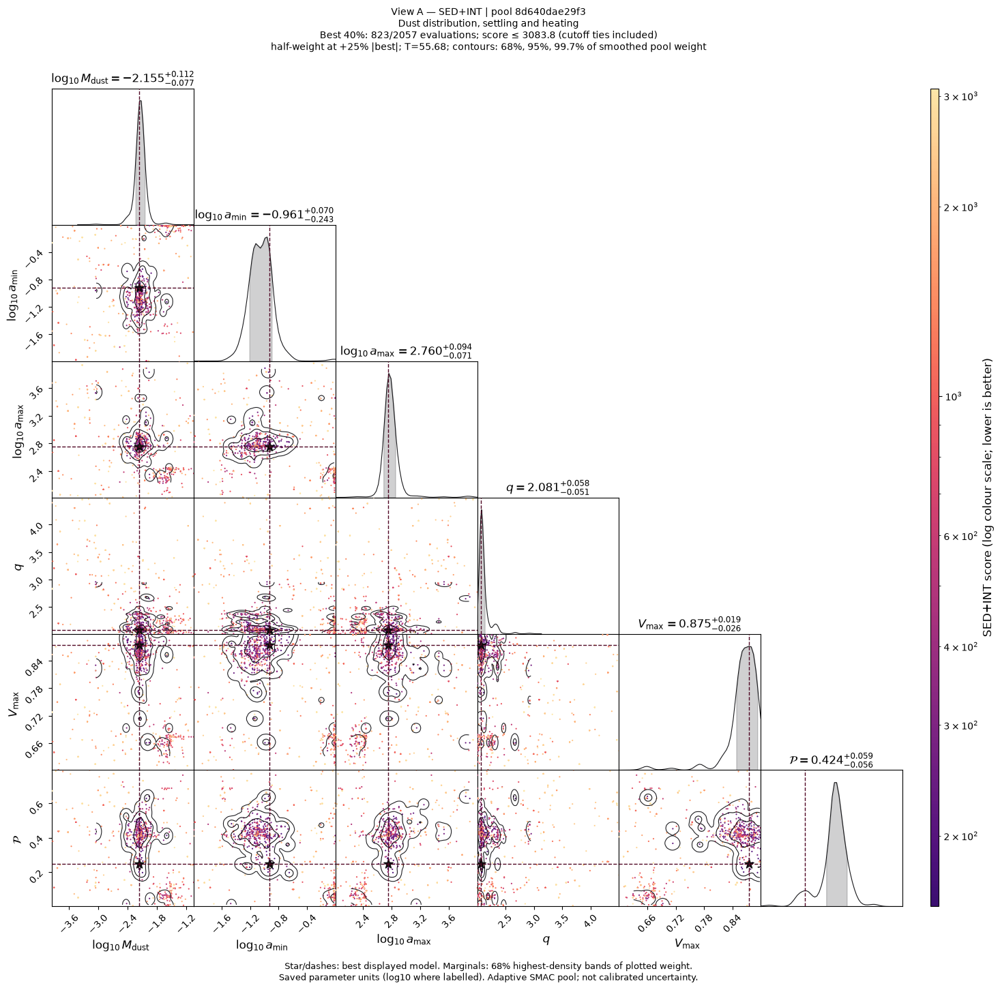

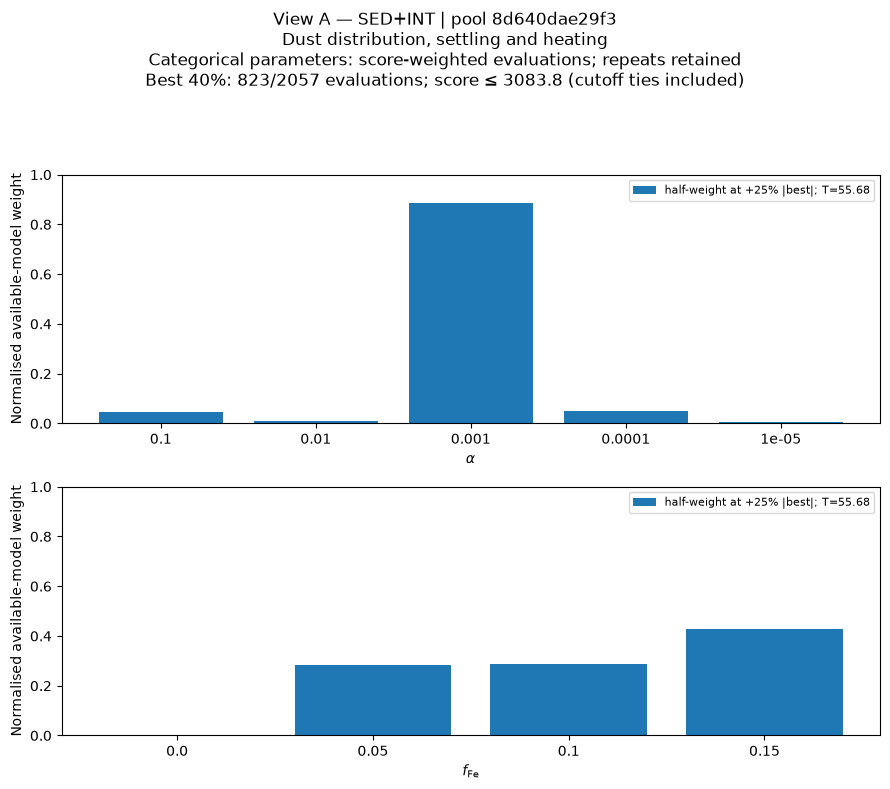

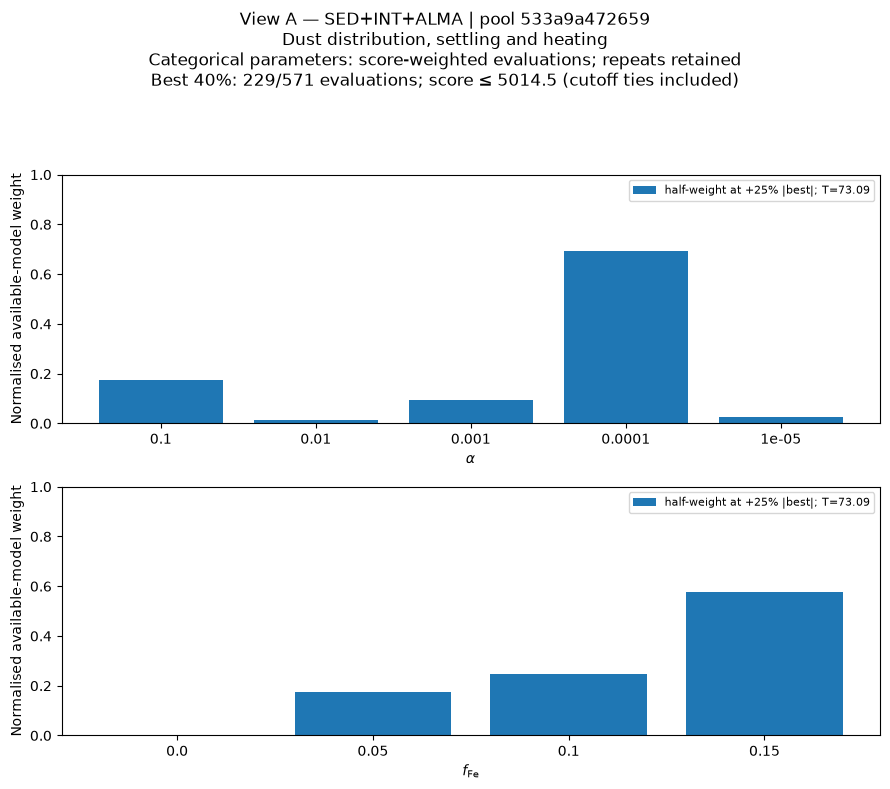

/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 313 samples available to compute an HDI for column 'inclination' in chain 'half-weight at +25% |best|; T=186.9'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:584: UserWarning: Only 313 samples available to compute an HDI for column 'inclination' in chain 'half-weight at +25% |best|; T=186.9'. Results may be unreliable; consider enabling KDE or providing more samples.
  summary = self.get_parameter_summary_hdi(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 313 samples available to compute an HDI for column 'disk_pa' in chain 'half-weight at +25% |best|; T=186.9'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chai

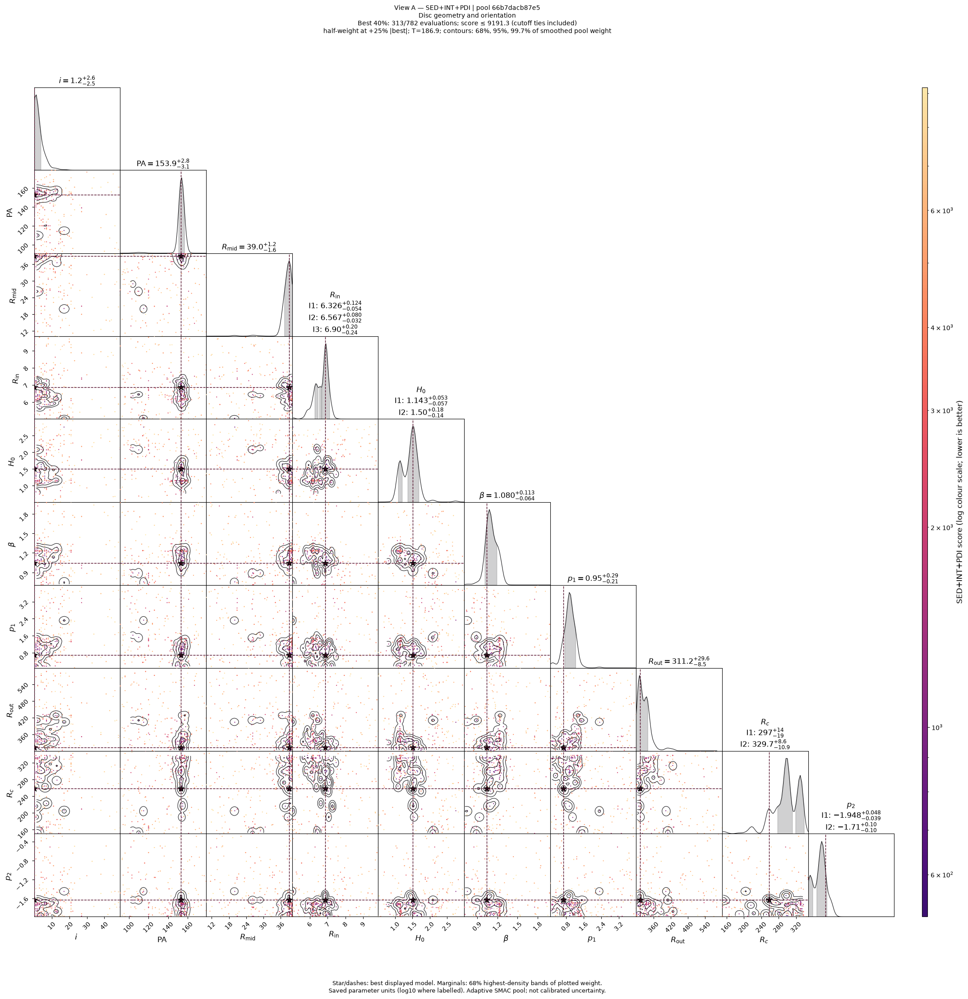

/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 313 samples available to compute an HDI for column 'disk_total_dust_mass' in chain 'half-weight at +25% |best|; T=186.9'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:584: UserWarning: Only 313 samples available to compute an HDI for column 'disk_total_dust_mass' in chain 'half-weight at +25% |best|; T=186.9'. Results may be unreliable; consider enabling KDE or providing more samples.
  summary = self.get_parameter_summary_hdi(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 313 samples available to compute an HDI for column 'zone_1_species_1_amin' in chain 'half-weight at +25% |best|; T=186.9'. Results may be unreliable; consider enabling KDE or providing more

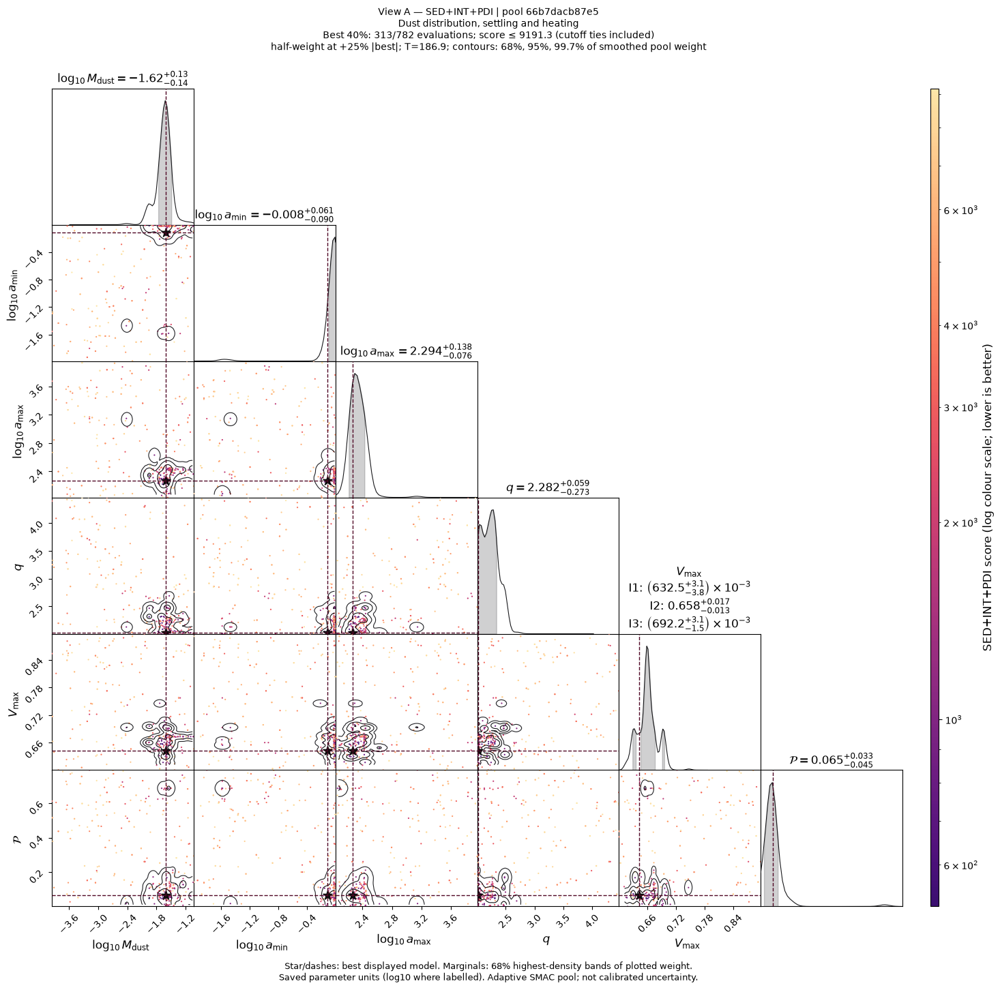

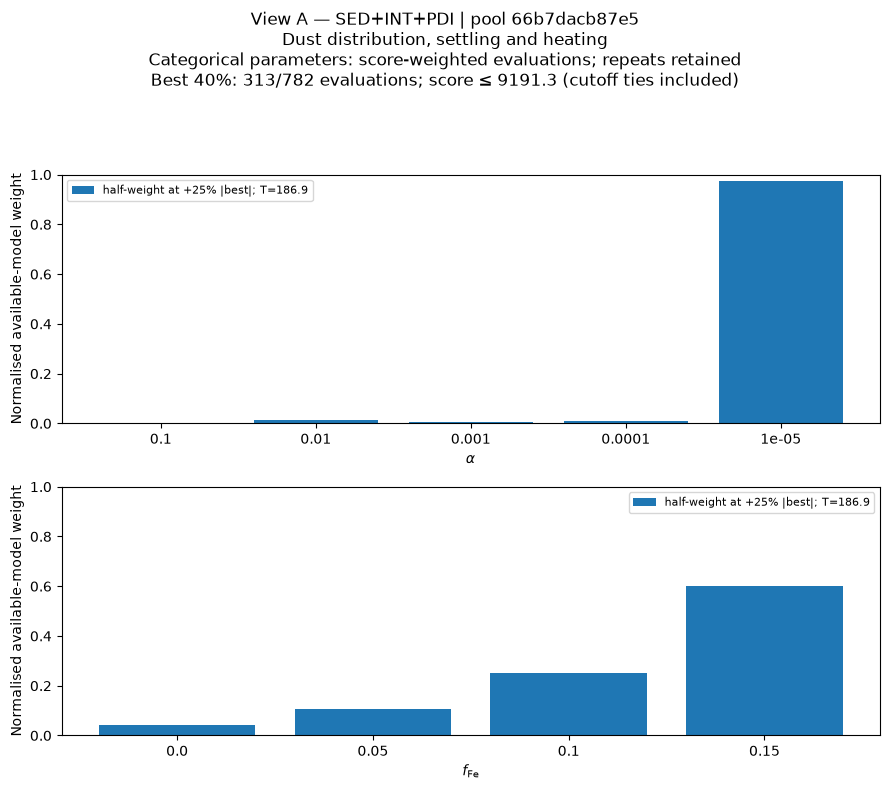

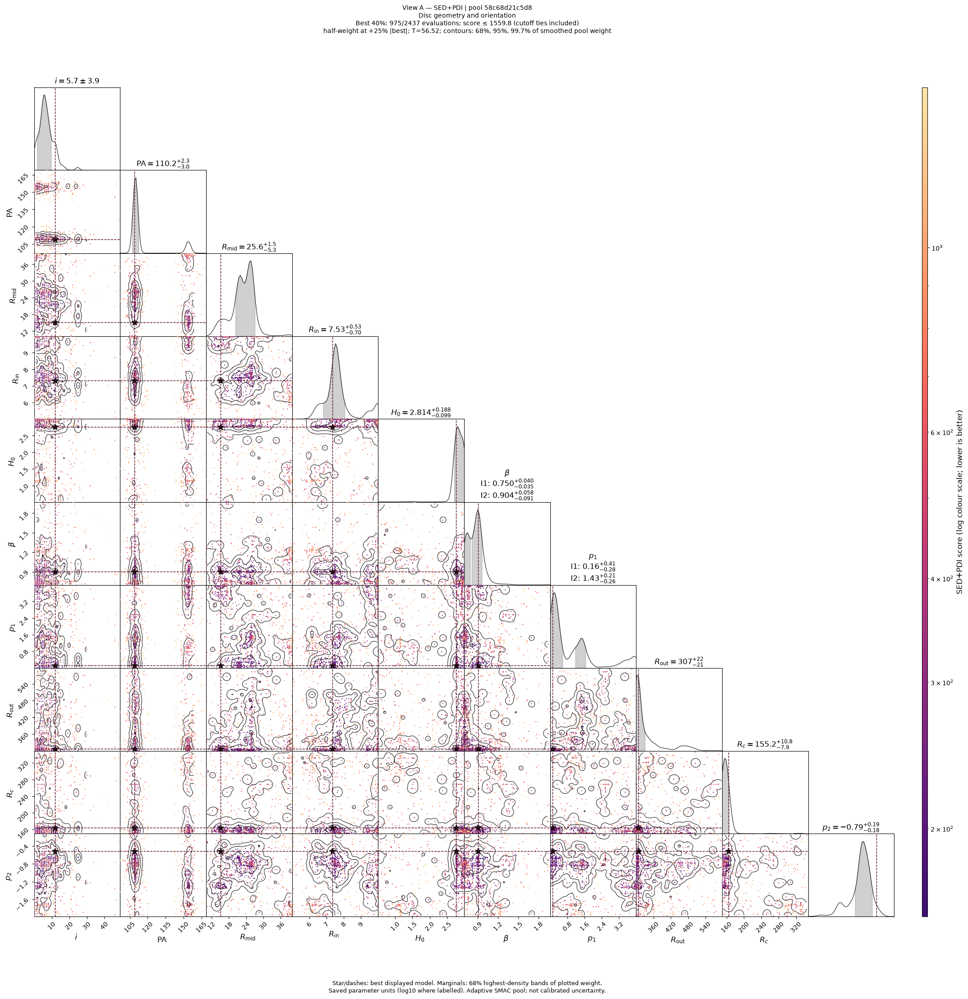

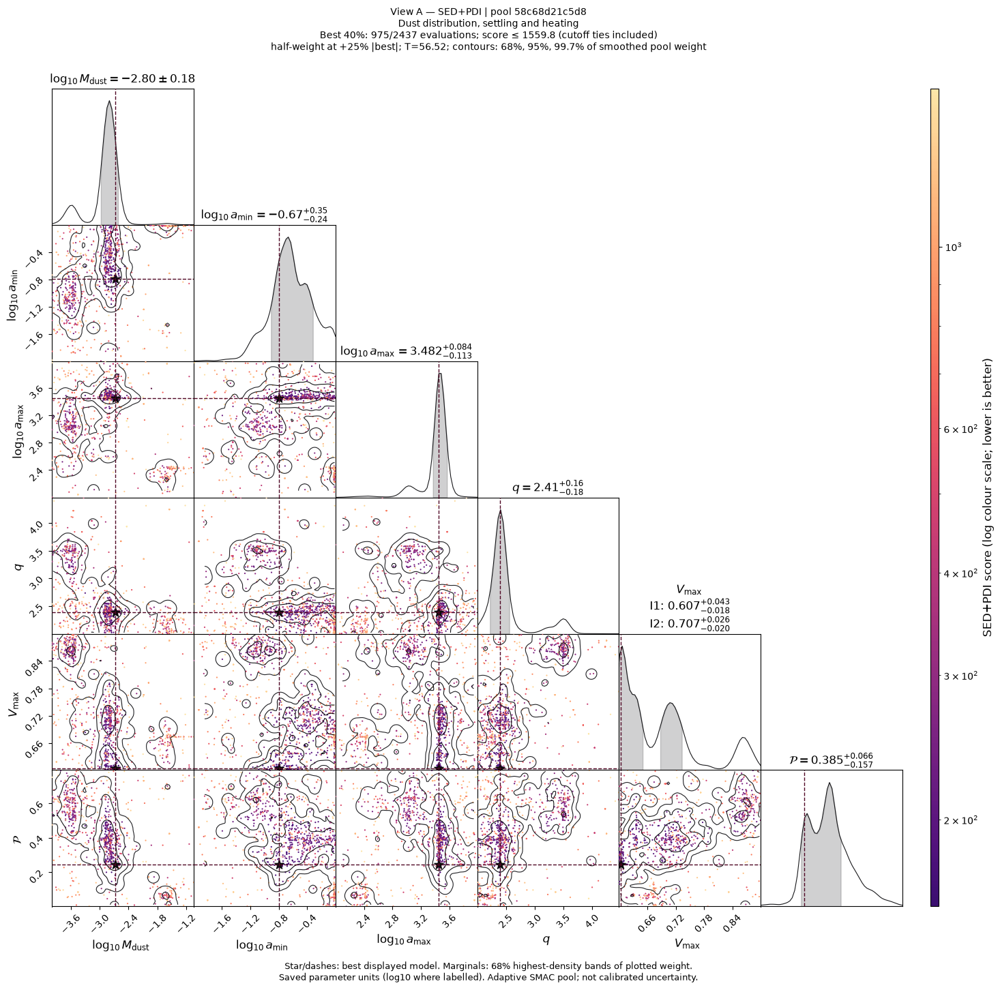

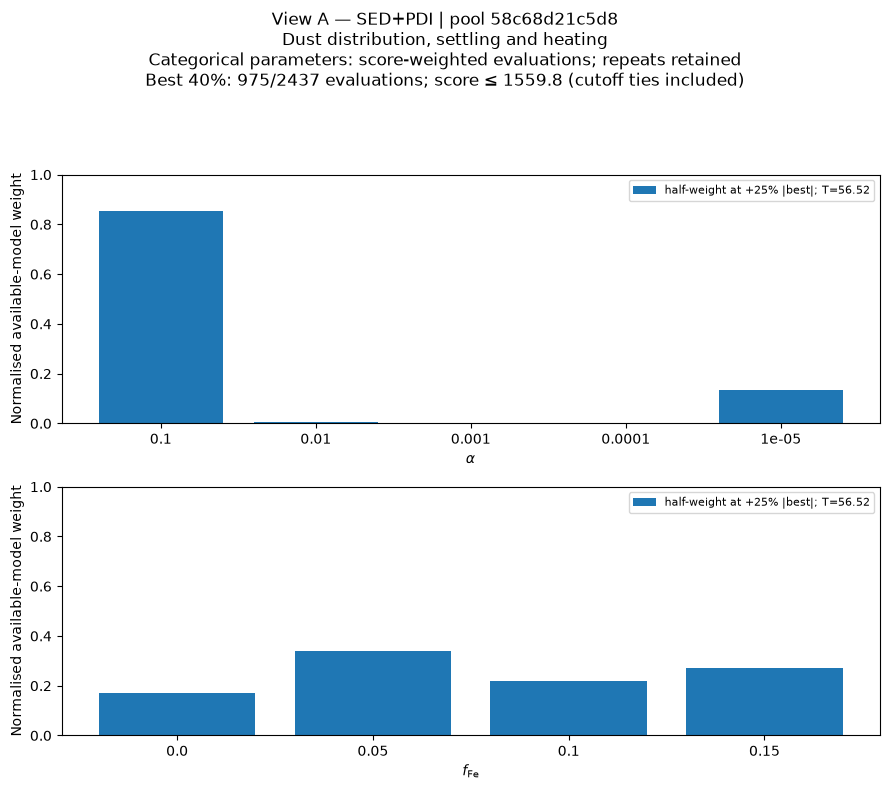

/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 447 samples available to compute an HDI for column 'inclination' in chain 'half-weight at +25% |best|; T=67.33'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:584: UserWarning: Only 447 samples available to compute an HDI for column 'inclination' in chain 'half-weight at +25% |best|; T=67.33'. Results may be unreliable; consider enabling KDE or providing more samples.
  summary = self.get_parameter_summary_hdi(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 447 samples available to compute an HDI for column 'disk_pa' in chain 'half-weight at +25% |best|; T=67.33'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chai

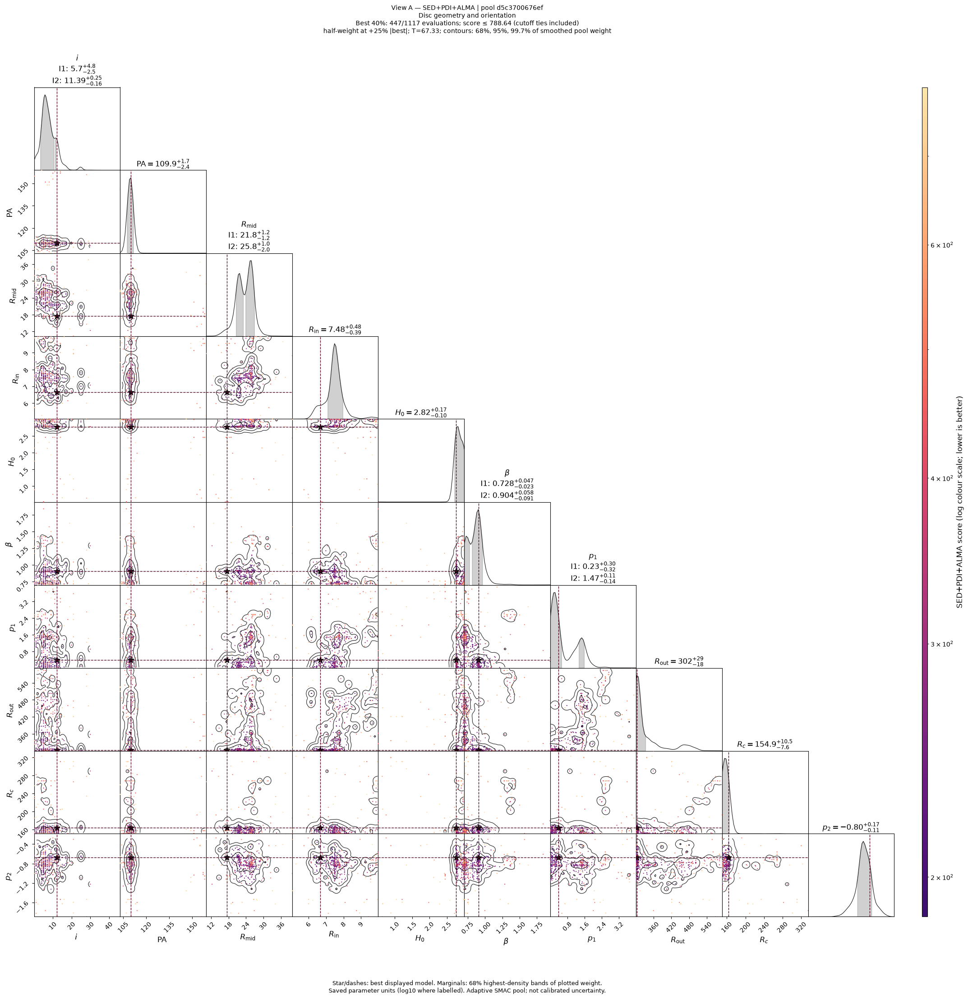

/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 447 samples available to compute an HDI for column 'disk_total_dust_mass' in chain 'half-weight at +25% |best|; T=67.33'. Results may be unreliable; consider enabling KDE or providing more samples.
  return callback(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:584: UserWarning: Only 447 samples available to compute an HDI for column 'disk_total_dust_mass' in chain 'half-weight at +25% |best|; T=67.33'. Results may be unreliable; consider enabling KDE or providing more samples.
  summary = self.get_parameter_summary_hdi(chain, column)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/chainconsumer/analysis.py:264: UserWarning: Only 447 samples available to compute an HDI for column 'zone_1_species_1_amin' in chain 'half-weight at +25% |best|; T=67.33'. Results may be unreliable; consider enabling KDE or providing more

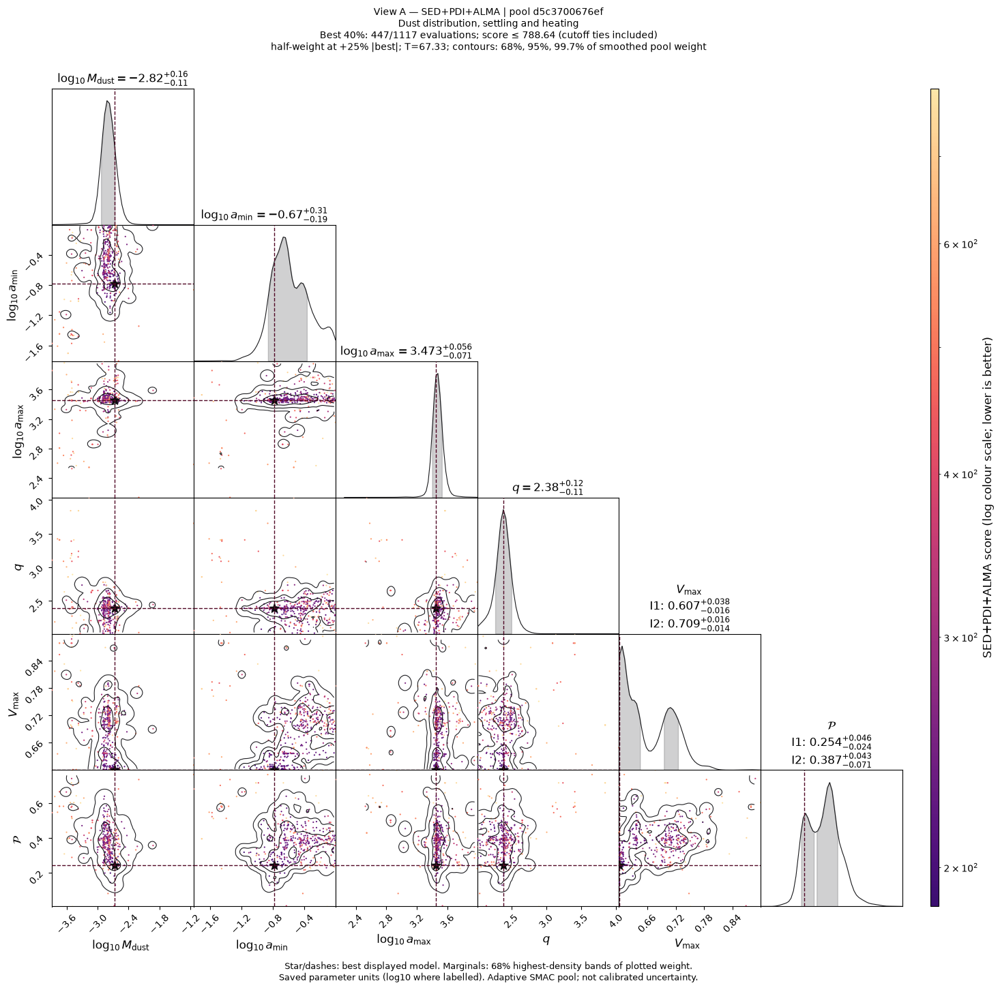

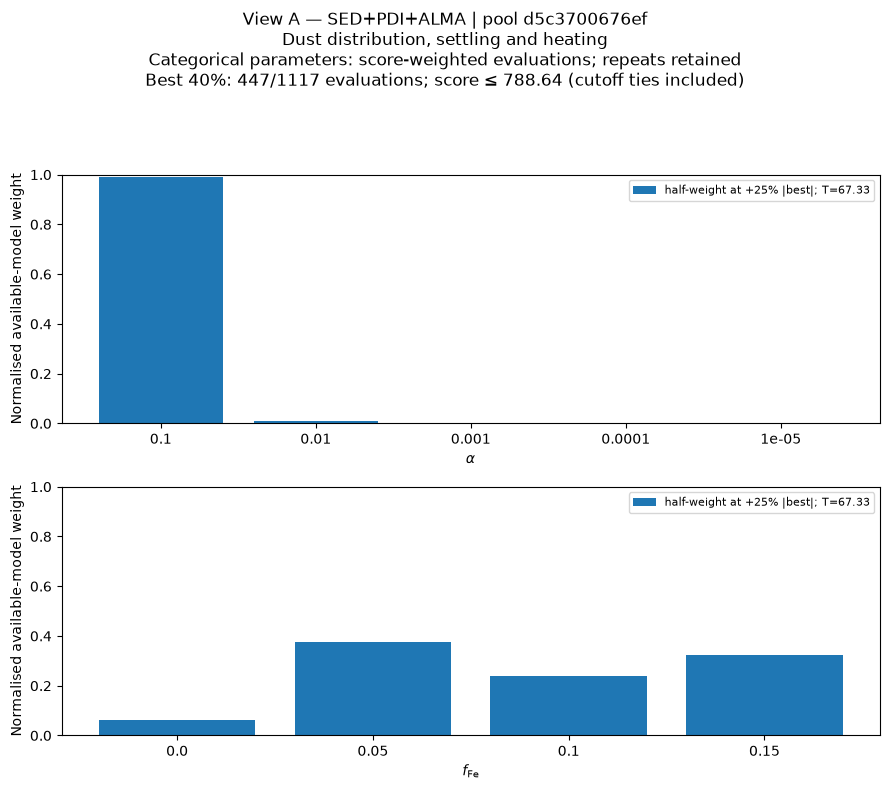

,objective,score_pool_key,requested_fraction,n_available,n_selected,realised_fraction,cutoff,cutoff_ties_included
0,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,0.4,2924,1170,0.400137,36.272329,True
1,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,0.4,262,105,0.400763,15831.724320,True
2,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,0.4,2587,1035,0.400077,1768.080423,True
3,INT+PDI+ALMA,4e60171e35965935ca56d63f9b7813b84aec394147db95...,0.4,367,147,0.400545,10161.449270,True
4,INT+PDI+ALMA,a3b1c17c86cdcccd0b417d2ede1a1fd2ca3bea42dc3d5a...,0.4,425,170,0.400000,6153.447854,True
5,PDI,322a76029944bc790547fe9bd3347a140fbc665a15e2f8...,0.4,425,170,0.400000,2014.588055,True
6,PDI,58c68d21c5d81e5e70598830116922aa63327855d638b3...,0.4,2542,1017,0.400079,1048.153374,True
7,SED,4016ff656864ab1d6fab37728bd838ef6937c1025b1644...,0.4,5635,2254,0.400000,107.103519,True
8,SED+ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,0.4,2394,958,0.400167,103.337155,True
9,SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,0.4,2057,823,0.400097,3083.769021,True


,objective,score_pool_key,setting,label,temperature,half_weight_delta,best_score,half_weight_fraction,temperature_rule,base_measure,n_evaluations,n_configurations,n_histories,n_zero_weights,max_evaluation_weight,evaluation_weight_ess,configuration_weight_ess,selection_fraction,n_before_selection,selection_cutoff
0,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,half_weight_01,half-weight at +10% |best|,2.053189,1.423162,14.231622,0.10,fraction_of_abs_best,equal_per_evaluation_including_repeats,1170,1002,5,0,0.008244,331.421568,195.113620,0.4,2924,36.272329
1,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,half_weight_02,half-weight at +25% |best|,5.132973,3.557906,14.231622,0.25,fraction_of_abs_best,equal_per_evaluation_including_repeats,1170,1002,5,0,0.003007,687.577270,479.222612,0.4,2924,36.272329
2,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,half_weight_03,half-weight at +50% |best|,10.265945,7.115811,14.231622,0.50,fraction_of_abs_best,equal_per_evaluation_including_repeats,1170,1002,5,0,0.001791,937.439267,651.078330,0.4,2924,36.272329
3,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,half_weight_01,half-weight at +10% |best|,269.896839,187.078233,1870.782329,0.10,fraction_of_abs_best,equal_per_evaluation_including_repeats,105,105,1,0,0.343610,3.174031,3.174031,0.4,262,15831.724320
4,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,half_weight_02,half-weight at +25% |best|,674.742097,467.695582,1870.782329,0.25,fraction_of_abs_best,equal_per_evaluation_including_repeats,105,105,1,0,0.247868,5.364717,5.364717,0.4,262,15831.724320
5,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,half_weight_03,half-weight at +50% |best|,1349.484194,935.391164,1870.782329,0.50,fraction_of_abs_best,equal_per_evaluation_including_repeats,105,105,1,0,0.125408,15.760470,15.760470,0.4,262,15831.724320
6,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,half_weight_01,half-weight at +10% |best|,15.730904,10.903831,109.038315,0.10,fraction_of_abs_best,equal_per_evaluation_including_repeats,1035,806,5,0,0.054111,75.220224,75.083502,0.4,2587,1768.080423
7,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,half_weight_02,half-weight at +25% |best|,39.327259,27.259579,109.038315,0.25,fraction_of_abs_best,equal_per_evaluation_including_repeats,1035,806,5,0,0.014683,173.046400,164.577238,0.4,2587,1768.080423
8,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,half_weight_03,half-weight at +50% |best|,78.654518,54.519157,109.038315,0.50,fraction_of_abs_best,equal_per_evaluation_including_repeats,1035,806,5,0,0.007443,265.041712,237.720555,0.4,2587,1768.080423
9,INT+PDI+ALMA,4e60171e35965935ca56d63f9b7813b84aec394147db95...,half_weight_01,half-weight at +10% |best|,178.822938,123.950615,1239.506152,0.10,fraction_of_abs_best,equal_per_evaluation_including_repeats,147,107,2,0,0.429566,3.524243,2.631527,0.4,367,10161.449270


,parameter,setting,status,n_pool,n_valid,retained_weight,omitted_weight,evaluation_weight_ess,configuration_weight_ess,reference_evaluation_id,reference_score,n_tied_best,...,upper,center_kind,summary_statistic,band_index,n_bands,summary_mass,summary_mass_scope,objective,score_pool_key,plot_style,histogram_smooth,parameter_group
0,numeric_corner,half_weight_02,plotted,1170.0,1170.0,1.0,1.110223e-16,687.57727,479.222612,seed1/sed_all_pdi_unres_corr [seed 358239]/row_59,14.231622,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,reference,2,Disc geometry and orientation
1,inclination,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,42.158535,band_mode,hdi,1.0,2.0,0.68,all_bands_together,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,reference,2,Disc geometry and orientation
2,inclination,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,51.840186,band_mode,hdi,2.0,2.0,0.68,all_bands_together,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,reference,2,Disc geometry and orientation
3,disk_pa,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,102.798985,within_interval_median,hdi,1.0,1.0,0.68,all_bands_together,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,reference,2,Disc geometry and orientation
4,disk_Rmid,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,32.238396,within_interval_median,hdi,1.0,1.0,0.68,all_bands_together,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,reference,2,Disc geometry and orientation
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
331,zone_1_species_1_aexp,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.501921,within_interval_median,hdi,1.0,1.0,0.68,all_bands_together,SED+PDI+ALMA,d5c3700676ef7c0526c1edd1ee767d19711b2207099ad9...,reference,2,"Dust distribution, settling and heating"
332,zone_1_species_1_Vmax,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.644523,band_mode,hdi,1.0,2.0,0.68,all_bands_together,SED+PDI+ALMA,d5c3700676ef7c0526c1edd1ee767d19711b2207099ad9...,reference,2,"Dust distribution, settling and heating"
333,zone_1_species_1_Vmax,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.724712,band_mode,hdi,2.0,2.0,0.68,all_bands_together,SED+PDI+ALMA,d5c3700676ef7c0526c1edd1ee767d19711b2207099ad9...,reference,2,"Dust distribution, settling and heating"
334,zone_1_species_1_porosity,half_weight_02,descriptive_marginal_summary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.300026,band_mode,hdi,1.0,2.0,0.68,all_bands_together,SED+PDI+ALMA,d5c3700676ef7c0526c1edd1ee767d19711b2207099ad9...,reference,2,"Dust distribution, settling and heating"


,objective,score_pool_key,parameter_group,status,reason
0,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,Disc geometry and orientation,plots_created,
1,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816...,"Dust distribution, settling and heating",plots_created,
2,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,Disc geometry and orientation,no_supported_plots,
3,All,4e60171e35965935ca56d63f9b7813b84aec394147db95...,"Dust distribution, settling and heating",plots_created,
4,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,Disc geometry and orientation,plots_created,
5,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4...,"Dust distribution, settling and heating",plots_created,
6,INT+PDI+ALMA,4e60171e35965935ca56d63f9b7813b84aec394147db95...,Disc geometry and orientation,no_supported_plots,
7,INT+PDI+ALMA,4e60171e35965935ca56d63f9b7813b84aec394147db95...,"Dust distribution, settling and heating",plots_created,
8,INT+PDI+ALMA,a3b1c17c86cdcccd0b417d2ede1a1fd2ca3bea42dc3d5a...,Disc geometry and orientation,no_supported_plots,
9,INT+PDI+ALMA,a3b1c17c86cdcccd0b417d2ede1a1fd2ca3bea42dc3d5a...,"Dust distribution, settling and heating",plots_created,


In [6]:
import importlib
import score_weighted_pool as score_weighted_module
# Reload the edited plotting helper when this cell is rerun in an existing kernel.
importlib.reload(score_weighted_module)
from score_weighted_pool import score_weighted_pool, plot_score_weighted_pool, group_parameter_references
from importlib.util import find_spec
from importlib.metadata import version

weighted_parts, temperature_parts, weighted_coverage_parts, weighted_status = [], [], [], []
weighted_selection_parts, weighted_membership_parts = [], []
chainconsumer_available = find_spec('chainconsumer') is not None
score_weighted_package_version = version('chainconsumer') if chainconsumer_available else None
weighted_parameters = SCORE_WEIGHTED_PARAMETERS if SCORE_WEIGHTED_PARAMETERS is not None else list(cost_references)
unknown_weighted_parameters = set(weighted_parameters)-set(cost_references)
if unknown_weighted_parameters:
    raise ValueError(f'Unknown/non-independent weighted parameters: {sorted(unknown_weighted_parameters)}')
weighted_references = {name: cost_references[name] for name in weighted_parameters}
weighted_parameter_groups = group_parameter_references(weighted_references, SCORE_WEIGHTED_PARAMETER_GROUPS)
pool_views['score_weighted_parameter_groups'] = pd.DataFrame([
    dict(parameter_group=label, parameter=name, coordinates=ref['kind'])
    for label, refs in weighted_parameter_groups.items() for name, ref in refs.items()])
display(pool_views['score_weighted_parameter_groups'])
# A rerun replaces the previous weighted figures, including the former full corner.
for name in list(figures):
    if name.startswith('available_per_objective_score_weighted_'):
        del figures[name]
if SCORE_WEIGHTED_ENABLED and not chainconsumer_available:
    print('Weight tables will be computed; plots require %pip install chainconsumer==1.3.0 in this kernel.')
if SCORE_WEIGHTED_ENABLED and not view_a_members.empty:
    if SCORE_WEIGHTED_OBJECTIVES is not None:
        unknown_objectives = set(SCORE_WEIGHTED_OBJECTIVES)-set(objective_design())
        if unknown_objectives:
            raise ValueError(f'Unknown weighted objectives: {sorted(unknown_objectives)}')
    for group_index, ((objective, key), candidates) in enumerate(
            view_a_members.groupby(['comparison', 'score_pool_key'], sort=True), 1):
        if SCORE_WEIGHTED_OBJECTIVES is not None and objective not in SCORE_WEIGHTED_OBJECTIVES:
            continue
        candidates = candidates.reset_index(drop=True)
        original_scores = score_matrix(candidates, {objective: objective_design()[objective]})[objective]
        retain, selection_cutoff = competitive_mask(original_scores, 'fraction', SCORE_WEIGHTED_RETAIN_FRACTION)
        n_before_selection = len(candidates)
        weighted_selection_parts.append(pd.DataFrame([dict(objective=objective, score_pool_key=key,
            requested_fraction=SCORE_WEIGHTED_RETAIN_FRACTION, n_available=n_before_selection,
            n_selected=int(retain.sum()), realised_fraction=float(retain.mean()),
            cutoff=selection_cutoff, cutoff_ties_included=True)]))
        weighted_membership_parts.append(candidates[['evaluation_id','parameter_hash','history','score_pool_key']]
            .assign(objective=objective, objective_score=original_scores, retained=retain))
        candidates = candidates.loc[retain].copy().reset_index(drop=True)
        absolute_deltas = SCORE_WEIGHTED_ABSOLUTE_DELTAS.get(
            (objective, key), SCORE_WEIGHTED_ABSOLUTE_DELTAS.get(objective))
        try:
            weighted, temperatures = score_weighted_pool(candidates, objective,
                objective_design()[objective], SCORE_WEIGHTED_HALF_WEIGHT_FRACTIONS, absolute_deltas)
        except ValueError as error:
            weighted_status.append(dict(objective=objective, score_pool_key=key,
                                        status='weighting_skipped', reason=str(error)))
            continue
        temperatures = temperatures.assign(selection_fraction=SCORE_WEIGHTED_RETAIN_FRACTION,
            n_before_selection=n_before_selection, selection_cutoff=selection_cutoff)
        weighted_parts.append(weighted)
        temperature_parts.append(temperatures)
        if chainconsumer_available:
            for parameter_group_index, (label, refs) in enumerate(weighted_parameter_groups.items(), 1):
                # Weights/selection are computed once above, shared by all physical groups.
                plots, plotted_coverage = plot_score_weighted_pool(candidates, weighted, temperatures,
                    refs, SCORE_WEIGHTED_CONTOUR_MASSES, SCORE_WEIGHTED_BINS,
                    SCORE_WEIGHTED_SMOOTH, SCORE_WEIGHTED_MIN_ESS,
                    style=SCORE_WEIGHTED_STYLE, reference_setting=SCORE_WEIGHTED_REFERENCE_SETTING,
                    color_scale=SCORE_WEIGHTED_COLOR_SCALE, parameter_group=label,
                    complete_references=weighted_references)
                weighted_coverage_parts.append(plotted_coverage)
                for kind, fig in plots.items():
                    show(f'available_per_objective_score_weighted_{group_index:02d}_group_{parameter_group_index:02d}_{kind}', fig)
                weighted_status.append(dict(objective=objective, score_pool_key=key, parameter_group=label,
                    status='plots_created' if plots else 'no_supported_plots', reason=''))
            continue
        else:
            status = 'weights_only_missing_chainconsumer'
        weighted_status.append(dict(objective=objective, score_pool_key=key, status=status, reason=''))
for name, parts in [('score_weights', weighted_parts), ('score_temperatures', temperature_parts),
                    ('score_weighted_coverage', weighted_coverage_parts),
                    ('score_weighted_selection', weighted_selection_parts),
                    ('score_weighted_membership', weighted_membership_parts)]:
    pool_views[name] = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
pool_views['score_weighted_status'] = pd.DataFrame(weighted_status)
display(pool_views['score_weighted_selection'])
display(pool_views['score_temperatures'])
# Show numeric plot support explicitly; full categorical coverage remains in pool_views.
weighted_coverage = pool_views['score_weighted_coverage']
if not weighted_coverage.empty:
    display(weighted_coverage.loc[weighted_coverage.parameter.eq('numeric_corner')
        | weighted_coverage.status.isin(['constant_or_unavailable', 'descriptive_marginal_summary'])].dropna(axis=1, how='all'))
display(pool_views['score_weighted_status'])


## Supplement — one fully scored candidate pool

These optional checks use the largest fully scored compatible subgroup inside the selected physical pool. They are skipped when no such subgroup is available. Its candidates may be fewer than those in Views A/B.

A **native winner** is the lowest recorded cost within its history, objective and compatibility group. A **common-pool winner** is the lowest reconstructed subset score on the shared fully scored candidates. Both are current sampled minima; all exact ties are retained here.

Scores, parameter rows, pool membership and repeated-configuration counts remain available for inspection. A poor subset minimum in this subgroup does not establish what a dedicated search or another setup could achieve. The saved configuration supplies bounds and independent/tied status; current template hashes and incomplete historical metadata limit comparisons between runs.


In [7]:
full_pool_available = np.isfinite(base_candidates[SUBSETS['All']]).all(axis=1).any()
if full_pool_available:
    # Here "final" means configured target budget, not a completed search.
    final = evaluations.loc[evaluations.usable & evaluations.cost_terms_match
        & np.isclose(evaluations.budget, evaluations.configured_max_budget)].copy()
    # Preserve ties and unique evaluation IDs; never infer equivalence from a local config_id.
    native_keys = ['history','objective_key','comparison_key']
    native_best = final.loc[final.cost.eq(final.groupby(native_keys).cost.transform('min'))].copy()
    display(native_best[['model_id','history','objective_key','cost',*SUBSETS['All']]])

    complete = base_candidates.loc[np.isfinite(base_candidates[SUBSETS['All']]).all(axis=1)].copy()
    # Map full keys to readable names; do not group by truncated hashes.
    keys = sorted(complete.comparison_key.unique())
    pool_names = {key:f'Common pool {i:02d}' for i,key in enumerate(keys,1)}
    complete['common_pool'] = complete.comparison_key.map(pool_names)
    pool_inventory = complete.groupby('common_pool').agg(n=('evaluation_id','size'),
        unique_parameters=('parameter_hash','nunique'), histories=('history','nunique'),
        products=('products','first'), compatibility=('comparison_key','first'))
    display(pool_inventory)
    selected_pool_id = pool_inventory.n.idxmax()  # Largest fully scored subgroup within the selected physical pool.
    if selected_pool_id not in pool_inventory.index:
        raise ValueError('POOL_ID must match an inventory label.')
    pool = complete.loc[complete.common_pool.eq(selected_pool_id)].copy().reset_index(drop=True)
    assert pool.evaluation_id.is_unique
    repeat_counts = pool.groupby('parameter_hash').agg(n=('evaluation_id','size'),
        histories=('history','nunique')).query('n > 1')
    print('Selected:',selected_pool_id, 'evaluations:',len(pool), 'histories:',pool.history.nunique())
    print('Repeated exact parameter fingerprints:',len(repeat_counts), '(all evaluations retained)')

    definitions = {item['name']:item for item in configspaces[pool.history.iloc[0]]['hyperparameters']}
    if PARAMETERS is None:
        PARAMETERS = [c[7:] for c in pool if c.startswith('param__')
            and definitions.get(c[7:],{}).get('type') != 'constant'
            and pool[c].nunique(dropna=True)>1
            and not pool[c].dropna().map(lambda x:isinstance(x,str) and 'param__'+x in pool).any()]
    references = {name:parameter_reference(pool,name,definitions[name],period=None,bins=HISTOGRAM_BINS)
                  for name in PARAMETERS}
    parameter_dictionary = pd.DataFrame([dict(parameter=name, **{k:v for k,v in definitions[name].items() if k!='name'},
                                            analysis_coordinates=references[name]['kind']) for name in PARAMETERS])
    display(parameter_dictionary)
    display(native_best.reindex(columns=['model_id','history','objective_key','cost',
        *['param__'+name for name in PARAMETERS]]))
    # Every model retains all independent and fixed/derived saved values in the pool table.
    objectives = objective_design()
    additions = addition_design(objectives)
    scores = score_matrix(pool,objectives)
    group_scores = pd.DataFrame({name:pool[columns].sum(axis=1) for name,columns in GROUPS.items()})
    # Native costs were audited against native objectives; subset rescoring need not equal them.
    display(pd.DataFrame({'objective':objectives.keys(), 'groups':list(objectives.values())}))

else:
    print('No fully scored supplement: views A/B above remain available; later supplemental diagnostics are skipped.')


,model_id,history,objective_key,cost,score_sed,score_pionier,score_gravity,score_matisse_l,score_matisse_n,score_pdi_V,score_pdi_I,score_pdi_H,score_alma
442,Model 0383,seed1/int_pdi_alma [seed 878561],"INT(band)+PDI(V,I,H)+ALMA",690.455441,NaN,26.714021,146.777550,266.269008,26.450920,41.659851,26.785003,103.512149,52.286939
510,Model 0459,seed1/int_pdi_alma [seed 878561],"INT(band)+PDI(V,I,H)+ALMA",1364.333636,NaN,211.616833,321.330063,147.419872,3.524324,89.065337,433.521300,90.164229,67.691678
1564,Model 1565,seed1/sed [seed 193544],SED,14.735357,14.735357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1818,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239],"SED+INT(band)+PDI(V,I,H)+ALMA",1870.782329,41.342390,19.720194,78.181834,62.459222,2.928977,417.996272,524.359088,702.488005,21.306347
2830,Model 2830,seed1/sed_alma [seed 769887],SED+ALMA,35.606875,18.434243,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.172632
3135,Model 3058,seed1/sed_int_alma [seed 987212],SED+INT(band)+ALMA,202.657751,39.128756,15.133215,45.839210,66.144430,13.792650,NaN,NaN,NaN,22.619489
3695,Model 3644,seed1/sed_int_pdi [seed 724769],"SED+INT(band)+PDI(V,I,H)",518.188818,37.179171,36.447727,153.338476,75.966745,2.741957,42.377388,59.903601,110.233754,NaN
4649,Model 4642,seed1/sed_interf [seed 128278],SED+INT(band),154.382096,27.254050,31.011076,32.149356,59.024745,4.942868,NaN,NaN,NaN,NaN
5568,Model 5552,seed1/sed_pdi_alma [seed 171866],"SED+PDI(V,I,H)+ALMA",186.669877,23.806727,NaN,NaN,NaN,NaN,23.060237,20.602613,89.889041,29.311258
6188,Model 6142,seed1/sed_pdi_unres_corr [seed 823308],"SED+PDI(V,I,H)",199.605718,51.361959,NaN,NaN,NaN,NaN,36.075144,46.752591,65.416023,NaN


,n,unique_parameters,histories,products,compatibility
common_pool,,,,,
Common pool 01,262,262,1,"alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",53b5191ef93607d23a49ceb86f4666b1644db3c0490c43...


Selected: Common pool 01 evaluations: 262 histories: 1
Repeated exact parameter fingerprints: 0 (all evaluations retained)


,parameter,type,choices,weights,default_value,meta,analysis_coordinates,lower,upper,log
0,alpha_viscosity,categorical,"[0.1, 0.01, 0.001, 0.0001, 1e-05]",NaN,0.01,None,categorical,NaN,NaN,NaN
1,disk_Rmid,uniform_float,NaN,NaN,18.00,None,linear,10.0000,40.0,False
2,disk_pa,uniform_int,NaN,NaN,150.00,None,linear,90.0000,180.0,False
3,disk_total_dust_mass,uniform_float,NaN,NaN,0.01,None,log10,0.0001,0.1,True
4,inclination,uniform_int,NaN,NaN,19.00,None,linear,0.0000,50.0,False
5,zone_1_Rin,uniform_float,NaN,NaN,7.20,None,linear,5.0000,10.0,False
6,zone_1_flaring_exp,uniform_float,NaN,NaN,1.20,None,linear,0.7000,2.0,False
7,zone_1_scale_height,uniform_float,NaN,NaN,1.40,None,linear,0.5000,3.0,False
8,zone_1_species_1_Vmax,uniform_float,NaN,NaN,0.70,None,linear,0.6000,0.9,False
9,zone_1_species_1_aexp,uniform_float,NaN,NaN,2.75,None,linear,2.0000,4.5,False


,model_id,history,objective_key,cost,param__alpha_viscosity,param__disk_Rmid,param__disk_pa,param__disk_total_dust_mass,param__inclination,param__zone_1_Rin,param__zone_1_flaring_exp,param__zone_1_scale_height,param__zone_1_species_1_Vmax,param__zone_1_species_1_aexp,param__zone_1_species_1_amax,param__zone_1_species_1_amin,param__zone_1_species_1_component_2_volume_fraction_iron,param__zone_1_species_1_porosity,param__zone_1_surface_density_exp,param__zone_2_Rc,param__zone_2_Rout,param__zone_2_surface_density_exp
442,Model 0383,seed1/int_pdi_alma [seed 878561],"INT(band)+PDI(V,I,H)+ALMA",690.455441,0.00100,18.073299,110,0.000392,4,7.814634,1.352034,2.882072,0.609122,2.971785,877.308519,0.044930,0.10,0.018278,2.537512,230,393,-0.899056
510,Model 0459,seed1/int_pdi_alma [seed 878561],"INT(band)+PDI(V,I,H)+ALMA",1364.333636,0.00100,35.516048,154,0.018214,21,6.198870,1.232898,1.160897,0.673947,2.130238,207.242107,0.945431,0.05,0.091596,1.326847,337,427,-1.881059
1564,Model 1565,seed1/sed [seed 193544],SED,14.735357,0.01000,23.977265,98,0.007357,44,6.492295,0.922486,2.057485,0.647166,2.946033,9904.212633,0.114159,0.10,0.355180,2.433022,166,313,-1.892451
1818,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239],"SED+INT(band)+PDI(V,I,H)+ALMA",1870.782329,0.10000,20.880817,139,0.009671,27,7.404738,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
2830,Model 2830,seed1/sed_alma [seed 769887],SED+ALMA,35.606875,0.00100,29.474164,90,0.008039,37,6.448390,0.725190,2.194126,0.704351,2.931714,4506.563328,0.131505,0.15,0.405539,1.765473,150,303,-0.567707
3135,Model 3058,seed1/sed_int_alma [seed 987212],SED+INT(band)+ALMA,202.657751,0.00010,18.639852,111,0.006540,22,7.155736,0.852397,2.197888,0.855107,2.365753,454.969103,0.048025,0.15,0.400623,2.844657,203,582,-0.590377
3695,Model 3644,seed1/sed_int_pdi [seed 724769],"SED+INT(band)+PDI(V,I,H)",518.188818,0.00001,38.976759,153,0.024516,0,6.863232,1.042137,1.504427,0.642996,2.026037,183.878286,0.771124,0.15,0.066015,0.675244,258,313,-1.633501
4649,Model 4642,seed1/sed_interf [seed 128278],SED+INT(band),154.382096,0.00100,18.729578,105,0.006872,0,5.818889,0.847374,1.992287,0.874881,2.073323,560.156467,0.119034,0.05,0.247163,3.981549,151,540,-0.599970
5568,Model 5552,seed1/sed_pdi_alma [seed 171866],"SED+PDI(V,I,H)+ALMA",186.669877,0.10000,17.502947,110,0.002126,12,6.655621,0.905998,2.761658,0.600993,2.390533,2823.631311,0.164731,0.15,0.245550,0.380388,164,303,-0.677200
6188,Model 6142,seed1/sed_pdi_unres_corr [seed 823308],"SED+PDI(V,I,H)",199.605718,0.00001,14.280617,154,0.000230,3,9.994093,0.972279,2.776949,0.861647,3.207526,1076.918580,0.058019,0.00,0.520750,3.631646,162,304,-1.288811


,objective,groups
0,SED,[SED]
1,SED+INT,"[SED, INT]"
2,SED+PDI,"[SED, PDI]"
3,SED+ALMA,"[SED, ALMA]"
4,SED+INT+PDI,"[SED, INT, PDI]"
5,SED+INT+ALMA,"[SED, INT, ALMA]"
6,SED+PDI+ALMA,"[SED, PDI, ALMA]"
7,All,"[SED, INT, PDI, ALMA]"
8,INT,[INT]
9,PDI,[PDI]


## Supplement — current candidates and observable trade-offs

Show each common-pool objective's lowest-score candidates with their original observation-group scores and parameter values. This makes the compromise between observations visible without comparing totals from different objectives as though they were equivalent.

The regret matrix is `(score - objective minimum) / abs(objective minimum)`, displayed as `log(1 + regret)`. Zero marks that pool's minimum; a zero denominator is masked.

Progress curves show the best saved all-data score so far in this pool. Aggregate trial-wall hours sum recorded durations, including failures and earlier budgets; they are neither elapsed scheduler hours nor CPU-core hours.


,selected_by,model_id,history,all_data_cost,group_SED,group_INT,group_PDI,group_ALMA,param__alpha_viscosity,param__disk_Rmid,param__disk_pa,param__disk_total_dust_mass,...,param__zone_1_flaring_exp,param__zone_1_scale_height,param__zone_1_species_1_Vmax,param__zone_1_species_1_aexp,param__zone_1_species_1_amax,param__zone_1_species_1_amin,param__zone_1_species_1_component_2_volume_fraction_iron,param__zone_1_species_1_porosity,param__zone_1_surface_density_exp,param__zone_2_Rc,param__zone_2_Rout,param__zone_2_surface_density_exp
0,SED,Model 1800,seed1/sed_all_pdi_unres_corr [seed 358239],46516.448326,29.426881,403.328413,46064.907366,18.785665,0.00010,30.461606,95,0.008492,...,0.831860,2.230073,0.752822,2.927337,2805.171642,0.618634,0.15,0.475742,2.397769,159,506,-0.609452
1,SED+INT,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239],1870.782329,41.342390,163.290228,1644.843365,21.306347,0.10000,20.880817,139,0.009671,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
2,SED+PDI,Model 1805,seed1/sed_all_pdi_unres_corr [seed 358239],47251.914332,66.791771,46843.273060,282.166722,59.682780,0.00001,17.824723,107,0.000792,...,1.940446,0.521100,0.686423,2.656154,715.892817,0.212013,0.15,0.500523,0.494080,179,362,-0.709606
3,SED+ALMA,Model 1800,seed1/sed_all_pdi_unres_corr [seed 358239],46516.448326,29.426881,403.328413,46064.907366,18.785665,0.00010,30.461606,95,0.008492,...,0.831860,2.230073,0.752822,2.927337,2805.171642,0.618634,0.15,0.475742,2.397769,159,506,-0.609452
4,SED+INT+PDI,Model 1762,seed1/sed_all_pdi_unres_corr [seed 358239],1875.904473,198.590777,546.793116,1101.474429,29.046151,0.00001,26.135861,101,0.049086,...,0.945114,2.082912,0.757587,2.283991,701.909317,0.025965,0.05,0.729034,2.851730,151,322,-1.978414
5,SED+INT+ALMA,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239],1870.782329,41.342390,163.290228,1644.843365,21.306347,0.10000,20.880817,139,0.009671,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
6,SED+PDI+ALMA,Model 1805,seed1/sed_all_pdi_unres_corr [seed 358239],47251.914332,66.791771,46843.273060,282.166722,59.682780,0.00001,17.824723,107,0.000792,...,1.940446,0.521100,0.686423,2.656154,715.892817,0.212013,0.15,0.500523,0.494080,179,362,-0.709606
7,All,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239],1870.782329,41.342390,163.290228,1644.843365,21.306347,0.10000,20.880817,139,0.009671,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
8,INT,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239],1870.782329,41.342390,163.290228,1644.843365,21.306347,0.10000,20.880817,139,0.009671,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
9,PDI,Model 1621,seed1/sed_all_pdi_unres_corr [seed 358239],134024.815381,284.068927,133468.559077,179.194064,92.993314,0.00010,31.915145,155,0.000682,...,0.732969,0.886630,0.649287,4.040546,349.053403,0.293991,0.00,0.428442,1.562591,320,336,-0.432316


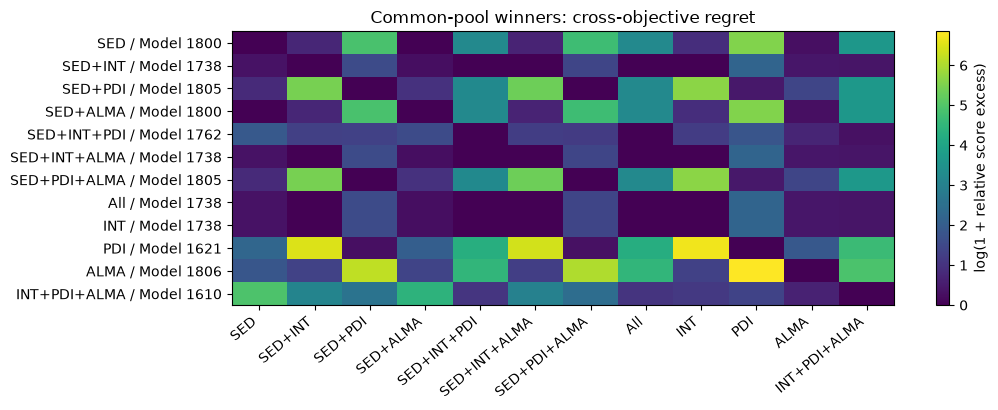

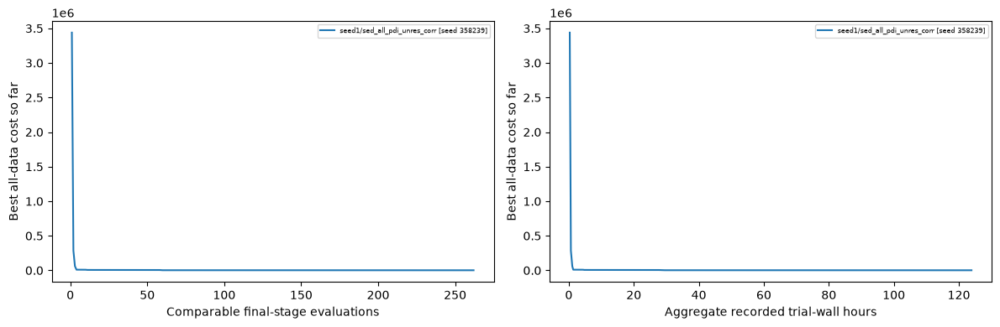

In [8]:
if full_pool_available:
    winner_parts = []
    for objective in scores:
        indices = scores.index[scores[objective].eq(scores[objective].min())]
        winners = pool.loc[indices].copy()
        winners['selected_by'] = objective
        for group in group_scores:
            winners['group_'+group] = group_scores.loc[indices,group]
        winners['all_data_cost'] = scores.loc[indices,'All']
        winner_parts.append(winners)
    common_best = pd.concat(winner_parts,ignore_index=True)
    display(common_best[['selected_by','model_id','history','all_data_cost',
        *['group_'+name for name in GROUPS], *['param__'+name for name in PARAMETERS]]])
    # All tied winners get a separate row rather than averaging their parameter values.
    winner_indices = pool.set_index('evaluation_id').index.get_indexer(common_best.evaluation_id)
    regret = scores.iloc[winner_indices].reset_index(drop=True)
    regret = (regret-scores.min())/scores.min().abs().replace(0,np.nan)
    regret.index = common_best.selected_by+' / '+common_best.model_id
    show('winner_cross_objective_regret',plot_heatmap(np.log1p(regret),
         'Common-pool winners: cross-objective regret', 'log(1 + relative score excess)'))

    # Compare convergence only under the same target objective/compatibility group.
    # Cumulative evaluation time sums all recorded trial durations, including failures/lower stages.
    # It is aggregate trial-wall time, NOT elapsed scheduler time or CPU-hours.
    time_rows = evaluations.sort_values(['history','endtime','record_index']).copy()
    time_rows['aggregate_trial_hours'] = time_rows.time_seconds.fillna(0).clip(lower=0).groupby(time_rows.history).cumsum()/3600
    elapsed = time_rows.set_index('evaluation_id').aggregate_trial_hours
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    progress_parts=[]
    for history,rows in pool.groupby('history',sort=False):
        ordered=rows.sort_values(['endtime','record_index'])
        best=ordered.cost.cummin()
        axes[0].plot(np.arange(1,len(ordered)+1),best,label=history)
        axes[1].plot(ordered.evaluation_id.map(elapsed),best,label=history)
        progress_parts.append(pd.DataFrame({'history':history,'evaluation_id':ordered.evaluation_id,
            'final_evaluation_count':np.arange(1,len(ordered)+1),'best_all_cost':best,
            'aggregate_trial_hours':ordered.evaluation_id.map(elapsed)}))
    for ax,label in zip(axes,['Comparable final-stage evaluations','Aggregate recorded trial-wall hours']):
        ax.set(xlabel=label,ylabel='Best all-data cost so far')
        ax.legend(fontsize=6)
    fig.tight_layout()
    show('search_progress',fig)
    progress=pd.concat(progress_parts,ignore_index=True)


## Supplement — parameter changes when observations are added

Compare each available one-group addition on the same fully scored candidates, including `All minus a group → All`. This complements View B, whose candidate pool can be larger for comparisons requiring fewer scores.

- `shift`: Wasserstein distance divided by the allowed numeric span (log coordinates when declared), or categorical total-variation distance.
- `width_ratio`: new/old 10–90% width; below one means a narrower selected numeric range. Undefined when the old width is zero.
- `median_shift`: signed median movement divided by the allowed span.
- `sample_jaccard`: intersection/union of selected evaluation IDs.

`DISPLAY_ALLOWANCE` controls the displayed value ranges; `DISPLAY_FRACTION` controls the matched-count heatmaps. `MIN_MODELS` masks sparse effects. Value tables retain saved units, category fractions, boundary occupancy and tied best values. A collection of marginal medians need not be an evaluated model.


,objective,parameter,kind,n_selected,supported,minimum_in_parameter_units,q10_in_parameter_units,q25_in_parameter_units,median_in_parameter_units,q75_in_parameter_units,q90_in_parameter_units,maximum_in_parameter_units,category_fractions,best_parameter_values,fraction_near_boundary
432,SED,alpha_viscosity,categorical,6,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""0.1"": 0.5, ""0.01"": 0.0, ""0.001"": 0.166666666...",[0.0001],NaN
433,SED,disk_Rmid,linear,6,False,11.602328,12.369260,15.024180,20.784481,24.417430,28.028953,30.461606,NaN,[30.461605777964],0.000000
434,SED,disk_pa,linear,6,False,95.000000,105.500000,121.750000,145.000000,154.000000,167.000000,179.000000,NaN,[95],0.166667
435,SED,disk_total_dust_mass,log10,6,False,0.000151,0.000215,0.000354,0.000874,0.006660,0.009081,0.009671,NaN,[0.0084917192082],0.000000
436,SED,inclination,linear,6,False,10.000000,11.500000,13.750000,20.000000,26.250000,38.500000,50.000000,NaN,[50],0.166667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
643,INT+PDI+ALMA,zone_1_species_1_porosity,linear,6,False,0.091596,0.100845,0.163436,0.409137,0.594953,0.678684,0.729034,NaN,[0.4948126494884],0.000000
644,INT+PDI+ALMA,zone_1_surface_density_exp,linear,6,False,0.598489,0.962668,1.326847,2.089288,3.077863,3.375863,3.598484,NaN,[0.5984892435372],0.000000
645,INT+PDI+ALMA,zone_2_Rc,linear,6,False,151.000000,178.500000,206.750000,221.000000,304.250000,332.500000,337.000000,NaN,[206],0.166667
646,INT+PDI+ALMA,zone_2_Rout,linear,6,False,322.000000,336.500000,370.000000,427.000000,517.750000,551.000000,554.000000,NaN,[548],0.000000


,scope,mode,level,objective,n_pool,n_selected,cutoff,best_score
0,pooled,allowance,0.1,SED,262,1,32.369569,29.426881
1,pooled,allowance,0.1,SED+INT,262,1,225.095879,204.632617
2,pooled,allowance,0.1,SED+PDI,262,2,383.854342,348.958493
3,pooled,allowance,0.1,SED+ALMA,262,1,53.033801,48.212547
4,pooled,allowance,0.1,SED+INT+PDI,262,3,2031.544155,1846.858322
...,...,...,...,...,...,...,...,...
79,pooled,fraction,0.2,All,262,53,8287.625316,1870.782329
80,pooled,fraction,0.2,INT,262,53,1650.516277,163.290228
81,pooled,fraction,0.2,PDI,262,53,1546.911756,179.194064
82,pooled,fraction,0.2,ALMA,262,53,35.867781,14.231622


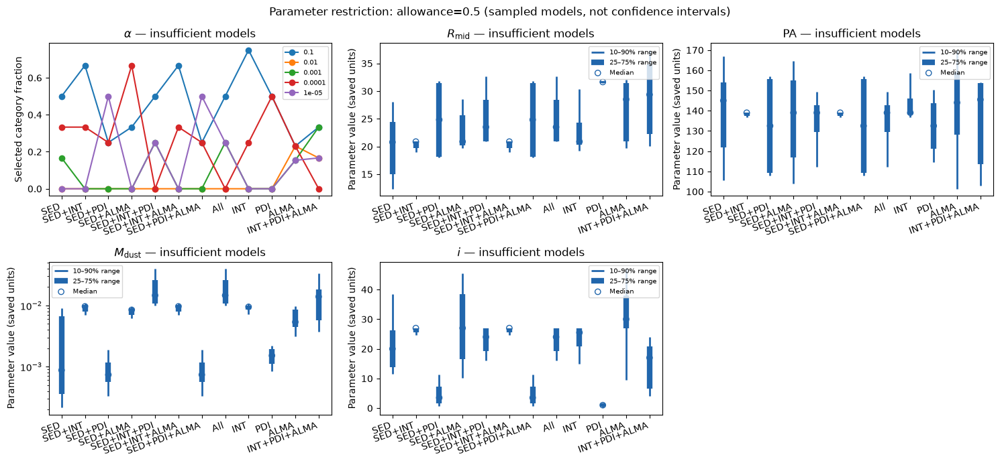

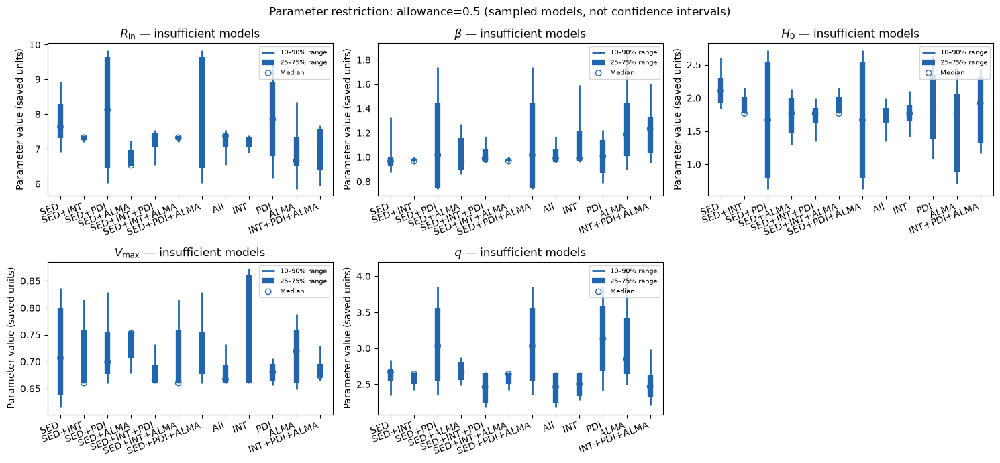

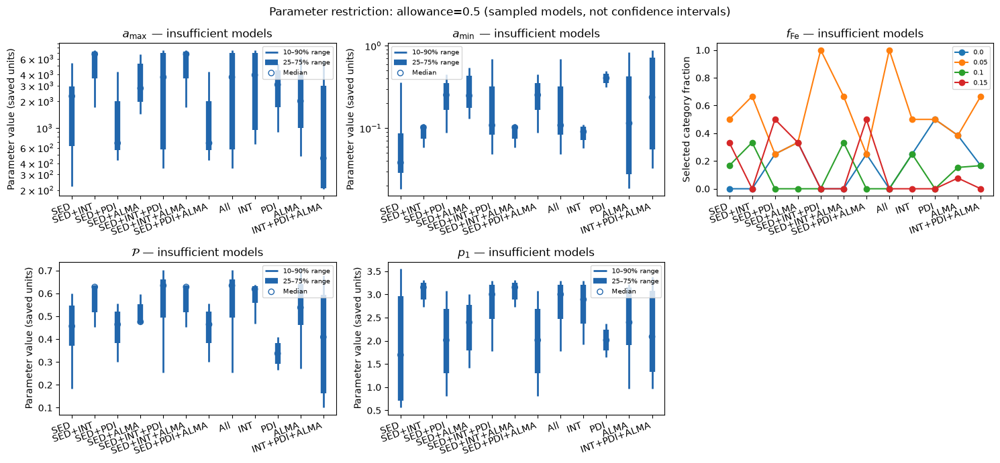

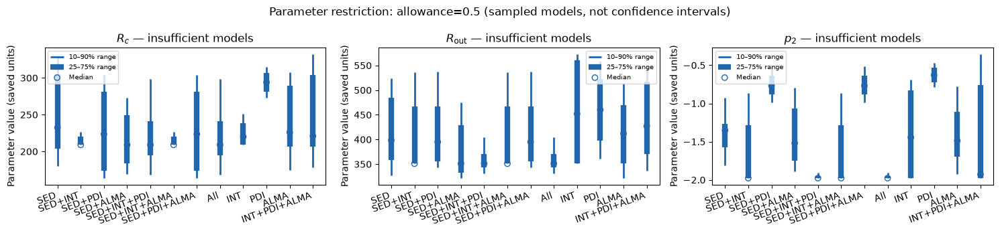

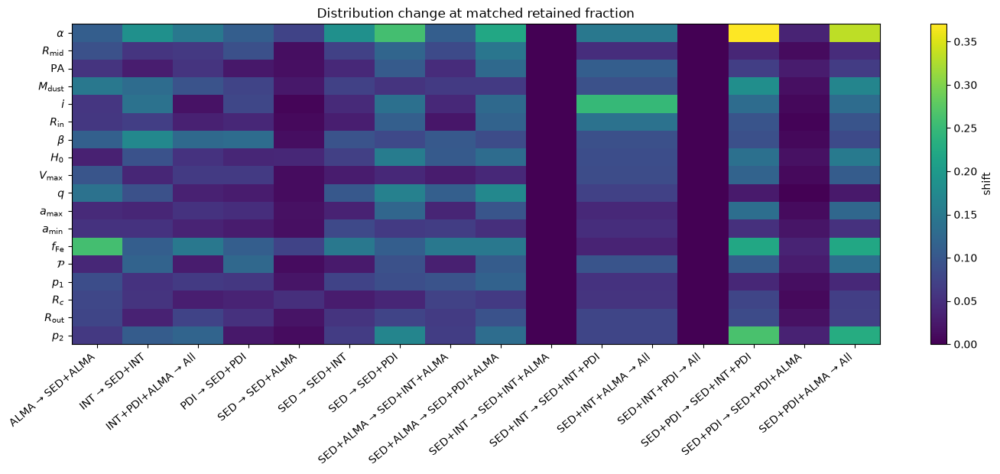

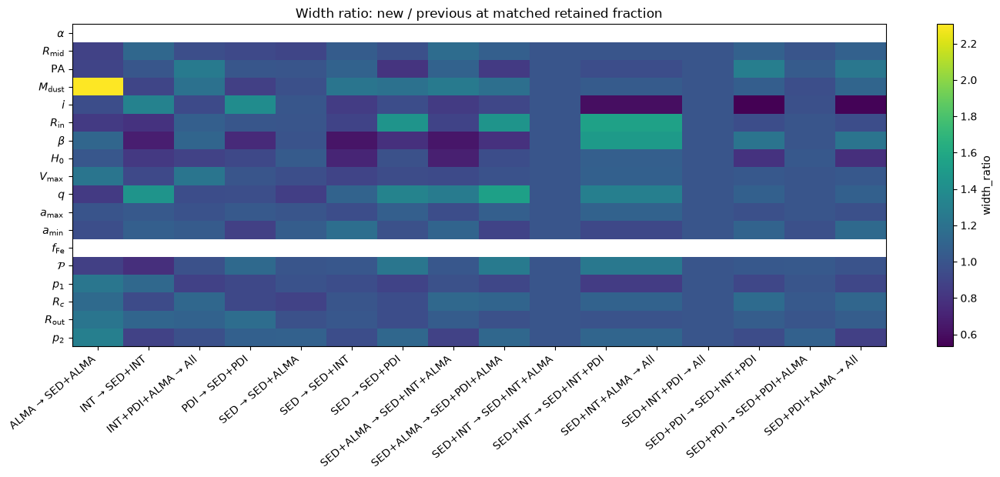

In [9]:
if full_pool_available:
    selection_levels={'allowance':sorted(set(RELATIVE_ALLOWANCES+[DISPLAY_ALLOWANCE])),
                      'fraction':sorted(set(MATCHED_FRACTIONS+[DISPLAY_FRACTION]))}

    metrics,selection_counts,effects=restriction_tables(pool,scores,definitions,references,additions,
        selection_levels,ABSOLUTE_ALLOWANCE,MIN_MODELS)

    main_values=metrics[(metrics.scope=='pooled') & (metrics['mode']=='allowance')
                       & np.isclose(metrics.level,DISPLAY_ALLOWANCE)].copy()

    value_columns=['objective','parameter','kind','n_selected','supported','minimum_in_parameter_units',
        'q10_in_parameter_units','q25_in_parameter_units','median_in_parameter_units',
        'q75_in_parameter_units','q90_in_parameter_units','maximum_in_parameter_units',
        'category_fractions','best_parameter_values','fraction_near_boundary']

    display(main_values.reindex(columns=value_columns))
    display(selection_counts[selection_counts.scope.eq('pooled')])

    # Actual value intervals, not only width. All objectives are comparisons, not a chronological sequence.
    order={name:i for i,name in enumerate(objectives)}
    plot_metrics=metrics[metrics.scope.eq('pooled')].copy()
    plot_metrics['step']=plot_metrics.objective.map(order)
    plot_metrics['subset']=plot_metrics.objective
    for first in range(0,len(PARAMETERS),5):
        show(f'parameter_values_{first}',plot_restriction(plot_metrics,PARAMETERS[first:first+5],
                                                       mode='allowance',value=DISPLAY_ALLOWANCE))
    matched=effects[(effects.scope=='pooled')&(effects['mode']=='fraction')
                    &np.isclose(effects.level,DISPLAY_FRACTION)].copy()

    matched['contrast']=matched.before+' → '+matched.after

    for field,title in [('shift','Distribution change'),('width_ratio','Width ratio: new / previous')]:
        matrix=matched.assign(value=matched[field].where(matched.supported)).pivot(
            index='parameter',columns='contrast',values='value')
        show('attribution_'+field,plot_heatmap(matrix,title+' at matched retained fraction',field))


## Supplement — changes across thresholds and search snapshots

Inspect the same summaries across selection thresholds, source histories, chronological prefixes (`PREFIX_FRACTIONS`) and leave-one-history-out pools. This shows which patterns are stable in the saved sample and which move as the search grows. Unequal search coverage can affect pooled distributions.

The optional history bootstrap runs only when `VERIFIED_REPLICATE_HISTORIES` explicitly lists at least five independent, comparable histories. `BOOTSTRAP_REPETITIONS` and `RANDOM_SEED` control that calculation. Its intervals concern between-history repeatability, not physical parameter uncertainty. Leave the list empty when those histories are unavailable; the other checks still run.


In [10]:
if full_pool_available:
    robustness=effects[effects.scope.ne('pooled')].copy()
    display(robustness[(robustness['mode']=='fraction')&np.isclose(robustness.level,DISPLAY_FRACTION)])
    # Each row is a history/objective best and selected parameter distribution.
    history_values=metrics[(metrics.scope!='pooled')&(metrics['mode']=='allowance')
                          &np.isclose(metrics.level,DISPLAY_ALLOWANCE)]
    display(history_values[history_values.objective.eq('All')].reindex(columns=['scope',*value_columns]))

    prefix_rows=[]
    for history,rows in pool.groupby('history',sort=False):
        ordered=rows.sort_values(['endtime','record_index'])
        for fraction in PREFIX_FRACTIONS:
            prefix=ordered.iloc[:max(1,int(np.ceil(len(ordered)*fraction)))]
            keep,cutoff=competitive_mask(scores.loc[prefix.index,'All'],'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
            sample=prefix.loc[keep]
            for name,ref in references.items():
                from observation_convergence_utils import parameter_metrics
                row,_,_=parameter_metrics(prefix,sample,name,definitions[name],min_models=MIN_MODELS,reference=ref)
                prefix_rows.append(dict(history=history,prefix_fraction=fraction,best_cost=scores.loc[prefix.index,'All'].min(),**row))
    prefix_stability=pd.DataFrame(prefix_rows)
    display(prefix_stability.reindex(columns=['history','prefix_fraction','parameter','n_selected','supported',
        'best_cost','q10_in_parameter_units','median_in_parameter_units','q90_in_parameter_units']))
    # Leave out each history in turn to inspect its influence on the pooled selection.
    keep,_=competitive_mask(scores.All,'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
    pooled_selected=pool.loc[keep]
    leave_history_rows=[]
    for history in pool.history.unique():
        remaining=pool[pool.history.ne(history)]
        if remaining.empty:
            continue
        selected_mask,_=competitive_mask(scores.loc[remaining.index,'All'],'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
        for name,ref in references.items():
            leave_history_rows.append(dict(omitted_history=history,parameter=name,
                **distribution_effect(pooled_selected,remaining.loc[selected_mask],name,ref)))
    leave_history_out=pd.DataFrame(leave_history_rows)
    display(leave_history_out)
    bootstrap_intervals=pd.DataFrame()
    if VERIFIED_REPLICATE_HISTORIES:
        if not set(VERIFIED_REPLICATE_HISTORIES)<=set(pool.history):
            raise ValueError('Unknown verified history names.')
        bootstrap_intervals=bootstrap_history_effects(effects,VERIFIED_REPLICATE_HISTORIES,
                                                     BOOTSTRAP_REPETITIONS,RANDOM_SEED)
        display(bootstrap_intervals)
    else:
        print('No verified replicate design: reporting descriptive robustness, not bootstrap confidence intervals.')


,scope,mode,level,before,after,added,parameter,kind,sample_jaccard,supported,n_before,n_after,shift,width_ratio,median_shift
3456,seed1/sed_all_pdi_unres_corr [seed 358239],fraction,0.1,SED,SED+INT,INT,alpha_viscosity,categorical,0.317073,True,27,27,0.185185,NaN,NaN
3457,seed1/sed_all_pdi_unres_corr [seed 358239],fraction,0.1,SED,SED+INT,INT,disk_Rmid,linear,0.317073,True,27,27,0.072073,1.052146,0.119737
3458,seed1/sed_all_pdi_unres_corr [seed 358239],fraction,0.1,SED,SED+INT,INT,disk_pa,linear,0.317073,True,27,27,0.041975,1.088146,0.022222
3459,seed1/sed_all_pdi_unres_corr [seed 358239],fraction,0.1,SED,SED+INT,INT,disk_total_dust_mass,log10,0.317073,True,27,27,0.071263,1.222281,0.163909
3460,seed1/sed_all_pdi_unres_corr [seed 358239],fraction,0.1,SED,SED+INT,INT,inclination,linear,0.317073,True,27,27,0.043704,0.848649,-0.020000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3739,seed1/sed_all_pdi_unres_corr [seed 358239],fraction,0.1,INT+PDI+ALMA,All,SED,zone_1_species_1_porosity,linear,0.255814,True,27,27,0.028520,0.976700,-0.137616
3740,seed1/sed_all_pdi_unres_corr [seed 358239],fraction,0.1,INT+PDI+ALMA,All,SED,zone_1_surface_density_exp,linear,0.255814,True,27,27,0.063002,0.875776,0.041441
3741,seed1/sed_all_pdi_unres_corr [seed 358239],fraction,0.1,INT+PDI+ALMA,All,SED,zone_2_Rc,linear,0.255814,True,27,27,0.030556,1.124665,0.100000
3742,seed1/sed_all_pdi_unres_corr [seed 358239],fraction,0.1,INT+PDI+ALMA,All,SED,zone_2_Rout,linear,0.255814,True,27,27,0.074568,1.091954,0.120000


,scope,objective,parameter,kind,n_selected,supported,minimum_in_parameter_units,q10_in_parameter_units,q25_in_parameter_units,median_in_parameter_units,q75_in_parameter_units,q90_in_parameter_units,maximum_in_parameter_units,category_fractions,best_parameter_values,fraction_near_boundary
2070,seed1/sed_all_pdi_unres_corr [seed 358239],All,alpha_viscosity,categorical,4,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""0.1"": 0.5, ""0.01"": 0.0, ""0.001"": 0.25, ""0.00...",[0.1],NaN
2071,seed1/sed_all_pdi_unres_corr [seed 358239],All,disk_Rmid,linear,4,False,20.880817,20.880817,20.880817,23.508339,28.480908,32.701992,35.516048,NaN,[20.880816698434],0.00
2072,seed1/sed_all_pdi_unres_corr [seed 358239],All,disk_pa,linear,4,False,101.000000,112.400000,129.500000,139.000000,142.750000,149.500000,154.000000,NaN,[139],0.00
2073,seed1/sed_all_pdi_unres_corr [seed 358239],All,disk_total_dust_mass,log10,4,False,0.009671,0.010088,0.010713,0.014637,0.025932,0.039824,0.049086,NaN,[0.0096708341228],0.00
2074,seed1/sed_all_pdi_unres_corr [seed 358239],All,inclination,linear,4,False,14.000000,16.100000,19.250000,24.000000,27.000000,27.000000,27.000000,NaN,[27],0.00
2075,seed1/sed_all_pdi_unres_corr [seed 358239],All,zone_1_Rin,linear,4,False,6.198870,6.537271,7.044872,7.365806,7.456666,7.550136,7.612450,NaN,[7.4047384057745],0.00
2076,seed1/sed_all_pdi_unres_corr [seed 358239],All,zone_1_flaring_exp,linear,4,False,0.945114,0.951413,0.960861,0.988048,1.065714,1.166024,1.232898,NaN,[0.9661101630252],0.00
2077,seed1/sed_all_pdi_unres_corr [seed 358239],All,zone_1_scale_height,linear,4,False,1.160897,1.343077,1.616347,1.768164,1.846851,1.988487,2.082912,NaN,[1.7681638438511],0.00
2078,seed1/sed_all_pdi_unres_corr [seed 358239],All,zone_1_species_1_Vmax,linear,4,False,0.660324,0.660324,0.660324,0.667135,0.694857,0.732495,0.757587,NaN,[0.6603236156225],0.00
2079,seed1/sed_all_pdi_unres_corr [seed 358239],All,zone_1_species_1_aexp,linear,4,False,2.130238,2.176364,2.245553,2.464129,2.652718,2.667929,2.678069,NaN,[2.6780692591606],0.00


,history,prefix_fraction,parameter,n_selected,supported,best_cost,q10_in_parameter_units,median_in_parameter_units,q90_in_parameter_units
0,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,alpha_viscosity,5,False,2594.729040,NaN,NaN,NaN
1,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,disk_Rmid,5,False,2594.729040,17.243411,27.052890,34.968194
2,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,disk_pa,5,False,2594.729040,116.400000,126.000000,148.800000
3,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,disk_total_dust_mass,5,False,2594.729040,0.000963,0.008271,0.014505
4,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,inclination,5,False,2594.729040,5.200000,9.000000,17.000000
5,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,zone_1_Rin,5,False,2594.729040,5.662809,6.198870,7.957244
6,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,zone_1_flaring_exp,5,False,2594.729040,0.737976,0.800167,1.080205
7,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,zone_1_scale_height,5,False,2594.729040,1.314867,1.871439,2.289332
8,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,zone_1_species_1_Vmax,5,False,2594.729040,0.687005,0.765638,0.847481
9,seed1/sed_all_pdi_unres_corr [seed 358239],0.50,zone_1_species_1_aexp,5,False,2594.729040,2.618933,3.722524,4.396408


""


No verified replicate design: reporting descriptive robustness, not bootstrap confidence intervals.


## Supplement — parameter associations and sampled score envelopes

Two complementary displays help explore possible parameter trade-offs:

1. Spearman associations compare all candidates with allowance-selected candidates, pooled and by history. `PAIR_PLOTS` limits displayed pairs; the full table remains available. Correlation can reflect search coverage, selection or parameter bounds as well as physical compensation.
2. Per-parameter bins show the lowest saved score, with sparse bins masked by `PROFILE_MIN_MODELS`. These are sampled envelopes: other parameters were not reoptimised at each bin. A gap means insufficient saved coverage, not an excluded parameter range.

Linear/log coordinates and categories follow the recorded definitions. PA remains linear in this notebook. Use model/data predictions to examine the physical meaning of an association.


,x,y,n_all,rho_all,n_selected,rho_selected,change_in_rho,scope
0,disk_Rmid,disk_pa,262,-0.018976,4,NaN,NaN,pooled
1,disk_Rmid,disk_total_dust_mass,262,0.009660,4,NaN,NaN,pooled
2,disk_Rmid,inclination,262,-0.026614,4,NaN,NaN,pooled
3,disk_Rmid,zone_1_Rin,262,-0.003145,4,NaN,NaN,pooled
4,disk_Rmid,zone_1_flaring_exp,262,-0.015114,4,NaN,NaN,pooled
5,disk_Rmid,zone_1_scale_height,262,0.023690,4,NaN,NaN,pooled
6,disk_Rmid,zone_1_species_1_Vmax,262,-0.000785,4,NaN,NaN,pooled
7,disk_Rmid,zone_1_species_1_aexp,262,-0.038231,4,NaN,NaN,pooled
8,disk_Rmid,zone_1_species_1_amax,262,0.007684,4,NaN,NaN,pooled
9,disk_Rmid,zone_1_species_1_amin,262,0.003428,4,NaN,NaN,pooled


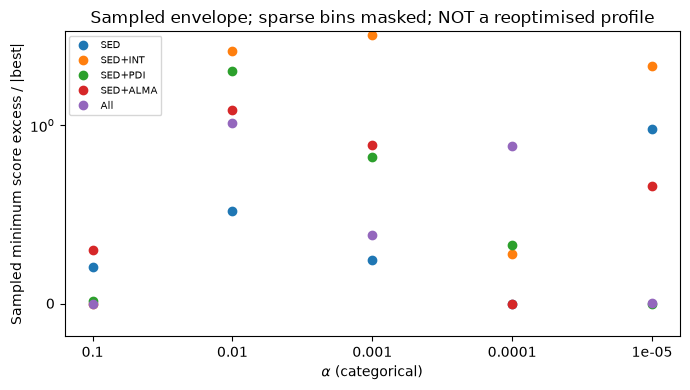

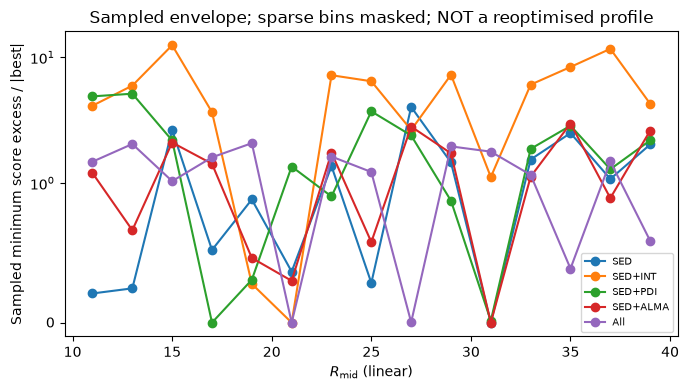

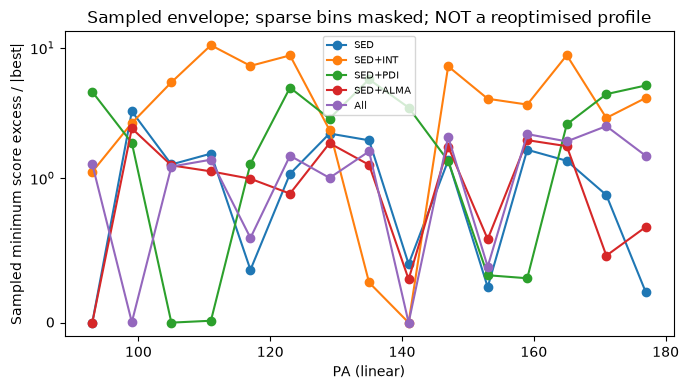

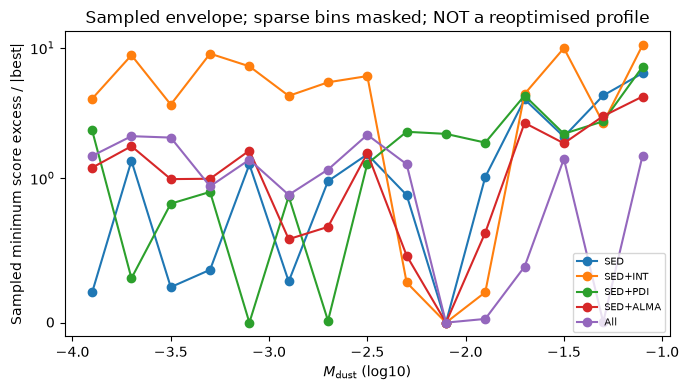

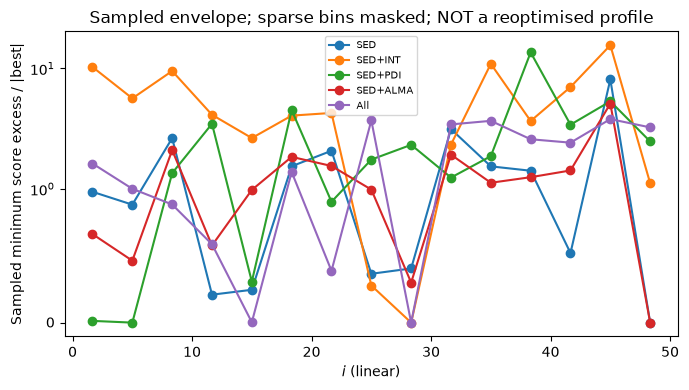

...

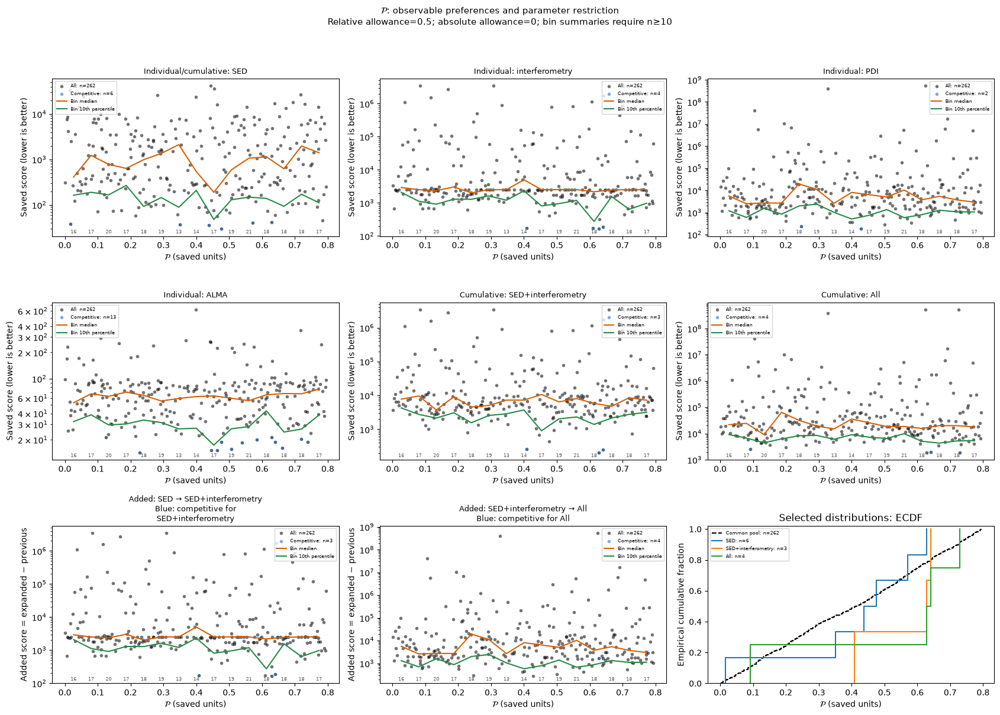

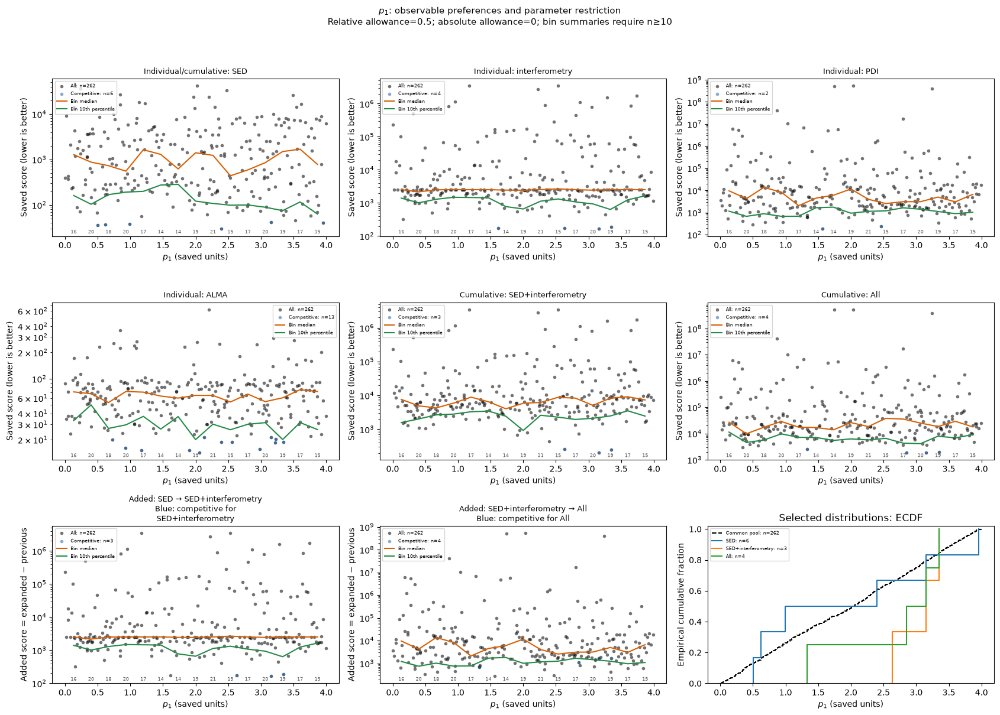

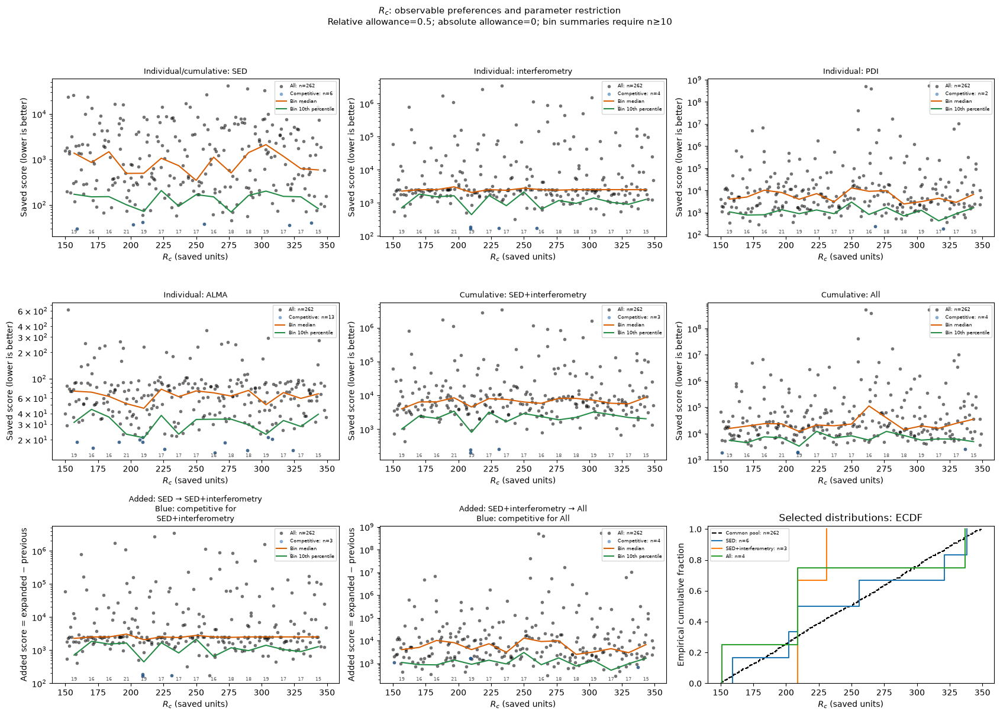

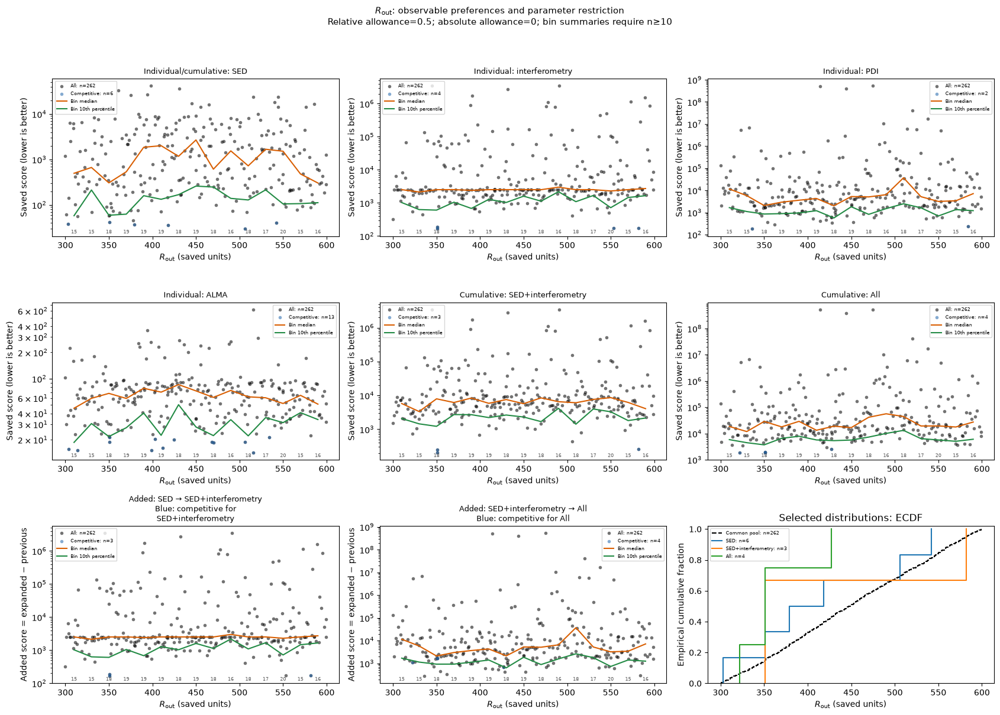

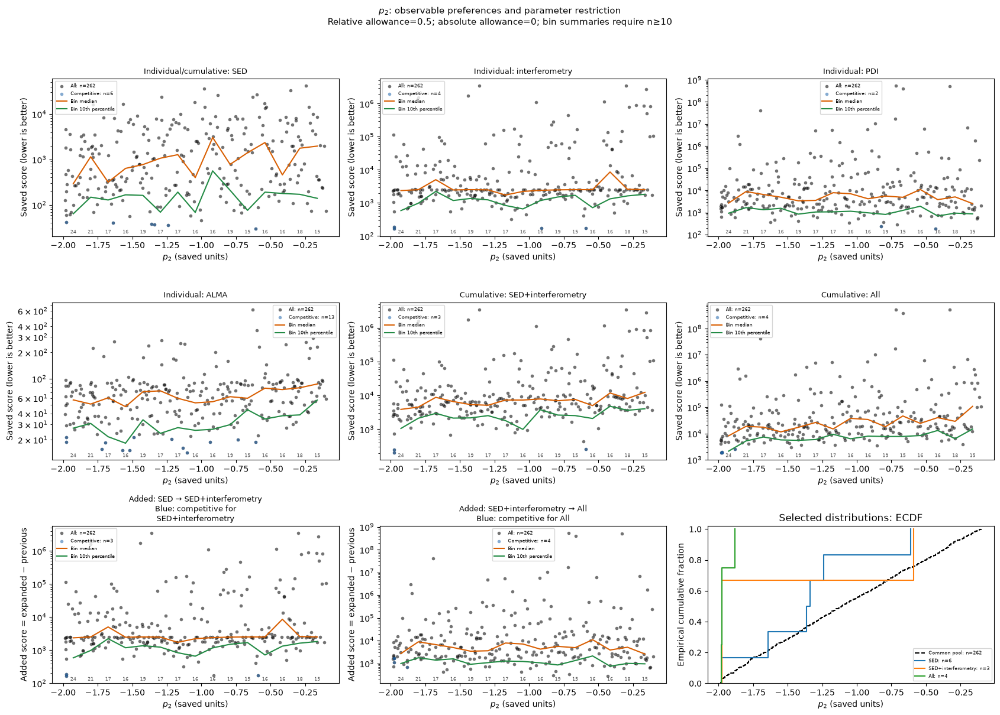

In [11]:
if full_pool_available:
    pair_parts=[]
    for scope,rows in [('pooled',pool),*pool.groupby('history',sort=False)]:
        keep,_=competitive_mask(scores.loc[rows.index,'All'],'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
        table=association_table(rows,rows.loc[keep],references,MIN_MODELS)
        table['scope']=scope
        pair_parts.append(table)
    associations=pd.concat(pair_parts,ignore_index=True)
    display(associations.sort_values('rho_selected',key=lambda x:x.abs(),ascending=False).head(30))
    strongest=associations[associations.scope.eq('pooled')].dropna(subset=['rho_selected']).sort_values(
        'rho_selected',key=lambda x:x.abs(),ascending=False).head(PAIR_PLOTS)
    for row in strongest.itertuples():
        fig,ax=plt.subplots(figsize=(6,4))
        for frame,color,label in [(pool,'black','All candidates'),(pooled_selected,'#2166ac','Allowance-selected')]:
            x=parameter_values(frame,row.x,references[row.x])
            y=parameter_values(frame,row.y,references[row.y])
            paired=pd.concat([x.rename('x'),y.rename('y')],axis=1).dropna()
            ax.scatter(paired.x,paired.y,s=POINT_SIZE,alpha=POINT_ALPHA,color=color,marker='o',linewidths=0,label=label)
        ax.set(xlabel=f'{parameter_label(row.x)} ({references[row.x]["kind"]})',ylabel=f'{parameter_label(row.y)} ({references[row.y]["kind"]})',
               title=f'Spearman: selected {row.rho_selected:.2f}; all {row.rho_all:.2f}')
        ax.legend()
        fig.tight_layout()
        show('pair_'+row.x+'_'+row.y,fig)

    # All model parameters, using the same coordinate definitions as View A.
    profile_references = cost_references
    profiles=empirical_profiles(pool,scores,profile_references,PROFILE_MIN_MODELS)
    for name in profile_references:
        fig,ax=plt.subplots(figsize=(7,4))
        for objective in ['SED','SED+INT','SED+PDI','SED+ALMA','All']:
            rows=profiles[(profiles.parameter==name)&(profiles.objective==objective)]
            denominator=abs(scores[objective].min())
            if denominator==0:
                continue
            ax.plot(rows.position,(rows.excess_minimum/denominator).where(rows.supported),
                    marker='o',linestyle='none' if profile_references[name]['kind']=='categorical' else '-',label=objective)
        if profile_references[name]['kind']=='categorical':
            ax.set_xticks(range(len(profile_references[name]['categories'])),profile_references[name]['categories'])
        ax.set(xlabel=f'{parameter_label(name)} ({profile_references[name]["kind"]})',ylabel='Sampled minimum score excess / |best|',
               title='Sampled envelope; sparse bins masked; NOT a reoptimised profile')
        ax.set_yscale('symlog',linthresh=1)
        ax.legend(fontsize=7)
        fig.tight_layout()
        show('profile_'+name,fig)
    # Detailed original-score scatter, binned medians/deciles and distributions.
    # This label is an explicit rescoring experiment, not a claimed historical sequence.
    for name in profile_references:
        fig,_,_=parameter_score_diagnostic(pool,name,profile_references[name],['SED','SED+interferometry','All'],
            allowance=DISPLAY_ALLOWANCE,absolute_allowance=ABSOLUTE_ALLOWANCE,
            min_bin_models=PROFILE_MIN_MODELS,score_scale='log',point_size=POINT_SIZE,point_alpha=POINT_ALPHA)
        show('score_values_'+name,fig)


## Supplement — candidate families and Pareto trade-offs

`FAMILY_ALLOWANCE` selects models near the current all-data minimum. Complete-linkage clustering groups them using `FAMILY_DISTANCE_CUTS`: mean span-scaled numeric distance, with a 0/1 mismatch for categories and equal weight per parameter. The groups are exploratory and can change with the cutoff, new evaluations or another setup. PA is treated linearly.

The Pareto table retains candidates that no other saved candidate improves in every observation group simultaneously. This exposes competing observational preferences without changing the original score weights. It does not select a final model; use the saved evaluation IDs to inspect their predicted observations.


,distance_cut,family,n,best_score,best_ids,histories,largest_distance_to_best,cutoff
0,0.1,1,2,1870.782329,"[""seed1/sed_all_pdi_unres_corr [seed 358239]/r...",seed1/sed_all_pdi_unres_corr [seed 358239],0.011168,2057.860562
1,0.1,2,1,1875.904473,"[""seed1/sed_all_pdi_unres_corr [seed 358239]/r...",seed1/sed_all_pdi_unres_corr [seed 358239],0.231413,2057.860562
2,0.2,1,2,1870.782329,"[""seed1/sed_all_pdi_unres_corr [seed 358239]/r...",seed1/sed_all_pdi_unres_corr [seed 358239],0.011168,2057.860562
3,0.2,2,1,1875.904473,"[""seed1/sed_all_pdi_unres_corr [seed 358239]/r...",seed1/sed_all_pdi_unres_corr [seed 358239],0.231413,2057.860562
4,0.3,1,3,1870.782329,"[""seed1/sed_all_pdi_unres_corr [seed 358239]/r...",seed1/sed_all_pdi_unres_corr [seed 358239],0.231413,2057.860562


,model_id,history,objective_score,score_excess,distance_to_best,param__alpha_viscosity,param__disk_Rmid,param__disk_pa,param__disk_total_dust_mass,param__inclination,param__zone_1_Rin,param__zone_1_flaring_exp,param__zone_1_scale_height,param__zone_1_species_1_Vmax,param__zone_1_species_1_aexp,param__zone_1_species_1_amax,param__zone_1_species_1_amin,param__zone_1_species_1_component_2_volume_fraction_iron,param__zone_1_species_1_porosity,param__zone_1_surface_density_exp,param__zone_2_Rc,param__zone_2_Rout,param__zone_2_surface_density_exp
1,Model 1762,seed1/sed_all_pdi_unres_corr [seed 358239],1875.904473,5.122144,0.231413,0.00001,26.135861,101,0.049086,14,7.612450,0.945114,2.082912,0.757587,2.283991,701.909317,0.025965,0.05,0.729034,2.851730,151,322,-1.978414
2,Model 1764,seed1/sed_all_pdi_unres_corr [seed 358239],1918.781323,47.998994,0.011168,0.10000,20.880817,139,0.011061,27,7.326873,1.009986,1.768164,0.660324,2.644267,6785.793112,0.114778,0.05,0.640660,3.348757,209,351,-1.977123
0,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239],1870.782329,0.000000,0.000000,0.10000,20.880817,139,0.009671,27,7.404738,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123


,model_id,history,group_SED,group_INT,group_PDI,group_ALMA
1,Model 1567,seed1/sed_all_pdi_unres_corr [seed 358239],115.811995,285762.529747,237.700492,56.114380
6,Model 1807,seed1/sed_all_pdi_unres_corr [seed 358239],904.593807,1537.587940,7823.467315,16.192549
16,Model 1634,seed1/sed_all_pdi_unres_corr [seed 358239],90.402480,62450.889006,707.636503,32.484915
22,Model 1712,seed1/sed_all_pdi_unres_corr [seed 358239],206.700933,5999.166557,457.555118,84.099578
32,Model 1778,seed1/sed_all_pdi_unres_corr [seed 358239],279.699004,5038.715744,356.227543,75.432521
46,Model 1793,seed1/sed_all_pdi_unres_corr [seed 358239],37.798016,6362.458723,12916.130539,38.235289
51,Model 1799,seed1/sed_all_pdi_unres_corr [seed 358239],2117.277474,2515.297671,1278.771725,23.521202
52,Model 1800,seed1/sed_all_pdi_unres_corr [seed 358239],29.426881,403.328413,46064.907366,18.785665
55,Model 1804,seed1/sed_all_pdi_unres_corr [seed 358239],232.335062,2140.776980,1098.826275,51.306428
56,Model 1805,seed1/sed_all_pdi_unres_corr [seed 358239],66.791771,46843.273060,282.166722,59.682780


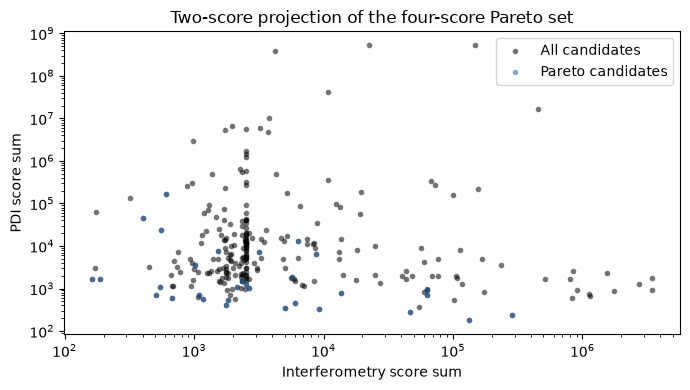

sampled_families  selected_candidates
allowance distance_cut                                       
0.10      0.1                          2                    3
          0.2                          2                    3
          0.3                          1                    3
0.25      0.1                          2                    3
          0.2                          2                    3
          0.3                          1                    3
0.50      0.1                          3                    4
          0.2                          3                    4
          0.3                          2                    4
1.00      0.1                          6                    7
          0.2                          6                    7
          0.3                          4                    7

,x,y,n_all,rho_all,n_selected,rho_selected,change_in_rho,distance_cut,family


Within-family correlations are masked when fewer than MIN_MODELS candidates are available.


In [12]:
if full_pool_available:
    family_members,family_summary=alternative_families(pool,scores.All,references,FAMILY_ALLOWANCE,
        ABSOLUTE_ALLOWANCE,FAMILY_DISTANCE_CUTS)
    display(family_summary)
    # One copy per evaluation for the candidate follow-up table; clustering cuts remain in family_members.
    alternatives=family_members.drop_duplicates('evaluation_id').copy()
    display(alternatives[['model_id','history','objective_score','score_excess','distance_to_best',
                          *['param__'+name for name in PARAMETERS]]].sort_values('distance_to_best',ascending=False))
    pareto=pool.loc[pareto_mask(group_scores)].copy()
    for group in GROUPS:
        pareto['group_'+group]=group_scores.loc[pareto.index,group]
    display(pareto[['model_id','history',*['group_'+name for name in GROUPS]]])
    fig,ax=plt.subplots(figsize=(7,4))
    for frame,color,label in [(pool,'black','All candidates'),(pareto,'#2166ac','Pareto candidates')]:
        ax.scatter(group_scores.loc[frame.index,'INT'],group_scores.loc[frame.index,'PDI'],
                   color=color,s=POINT_SIZE,alpha=POINT_ALPHA,marker='o',linewidths=0,label=label)
    ax.set(xlabel='Interferometry score sum',ylabel='PDI score sum',title='Two-score projection of the four-score Pareto set')
    if group_scores.INT.gt(0).all():
        ax.set_xscale('log')
    if group_scores.PDI.gt(0).all():
        ax.set_yscale('log')
    ax.legend()
    fig.tight_layout()
    show('pareto_projection',fig)

    # Repeat family counting across tolerances. Families may merge/split with either setting.
    family_resolution_parts=[]
    for allowance in sorted(set(RELATIVE_ALLOWANCES+[FAMILY_ALLOWANCE])):
        _,summary=alternative_families(pool,scores.All,references,allowance,
                                      ABSOLUTE_ALLOWANCE,FAMILY_DISTANCE_CUTS)
        summary['allowance']=allowance
        family_resolution_parts.append(summary)
    family_resolution=pd.concat(family_resolution_parts,ignore_index=True)
    display(family_resolution.groupby(['allowance','distance_cut']).agg(
        sampled_families=('family','size'),selected_candidates=('n','sum')))
    # Inspect whether pooled associations persist within a family; do not infer them from mixtures.
    family_pair_parts=[]
    for (cut,family),members in family_members.groupby(['distance_cut','family']):
        frame=pool.loc[pool.evaluation_id.isin(members.evaluation_id)]
        table=association_table(pool,frame,references,MIN_MODELS)
        table['distance_cut']=cut
        table['family']=family
        family_pair_parts.append(table)
    family_associations=pd.concat(family_pair_parts,ignore_index=True)
    display(family_associations.dropna(subset=['rho_selected']).head(20))
    print('Within-family correlations are masked when fewer than MIN_MODELS candidates are available.')


## Supplement — sensitivity to observation-group weights

Temporarily multiply one group's score by each value in `WEIGHT_FACTORS`, leaving the other groups unchanged. Record the lowest-score candidate, its original total score, selected count and selection overlap with the original objective.

This is an analysis-only experiment showing dependence on relative observational priorities. The temporary scores do not replace the recorded objective or choose new optimisation weights.


In [13]:
if full_pool_available:
    weight_rows=[]
    original_mask,_=competitive_mask(scores.All,'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
    original_ids=set(pool.loc[original_mask,'evaluation_id'])
    for group in GROUPS:
        for factor in WEIGHT_FACTORS:
            perturbed=scores.All+(factor-1)*group_scores[group]
            mask,_=competitive_mask(perturbed,'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)
            selected_ids=set(pool.loc[mask,'evaluation_id'])
            winners=pool.loc[perturbed.eq(perturbed.min())]
            for index,row in winners.iterrows():
                weight_rows.append(dict(group=group,factor=factor,model_id=row.model_id,
                    evaluation_id=row.evaluation_id,history=row.history,modified_minimum=perturbed.min(),
                    original_all_cost=scores.loc[index,'All'],n_selected=int(mask.sum()),
                    jaccard=len(original_ids&selected_ids)/len(original_ids|selected_ids),
                    **{name:row['param__'+name] for name in PARAMETERS}))
    weight_sensitivity=pd.DataFrame(weight_rows)
    display(weight_sensitivity)


,group,factor,model_id,evaluation_id,history,modified_minimum,original_all_cost,n_selected,jaccard,alpha_viscosity,disk_Rmid,disk_pa,...,zone_1_flaring_exp,zone_1_scale_height,zone_1_species_1_Vmax,zone_1_species_1_aexp,zone_1_species_1_amax,zone_1_species_1_amin,zone_1_species_1_component_2_volume_fraction_iron,zone_1_species_1_porosity,zone_1_surface_density_exp,zone_2_Rc,zone_2_Rout,zone_2_surface_density_exp
0,SED,0.5,Model 1762,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],1776.609085,1875.904473,5,0.80,0.00001,26.135861,101,...,0.945114,2.082912,0.757587,2.283991,701.909317,0.025965,0.05,0.729034,2.851730,151,322,-1.978414
1,SED,1.0,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],1870.782329,1870.782329,4,1.00,0.10000,20.880817,139,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
2,SED,2.0,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],1912.124718,1870.782329,3,0.75,0.10000,20.880817,139,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
3,INT,0.5,Model 1762,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],1602.507915,1875.904473,4,1.00,0.00001,26.135861,101,...,0.945114,2.082912,0.757587,2.283991,701.909317,0.025965,0.05,0.729034,2.851730,151,322,-1.978414
4,INT,1.0,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],1870.782329,1870.782329,4,1.00,0.10000,20.880817,139,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
5,INT,2.0,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],2034.072557,1870.782329,3,0.75,0.10000,20.880817,139,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
6,PDI,0.5,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],1048.360646,1870.782329,3,0.75,0.10000,20.880817,139,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
7,PDI,1.0,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],1870.782329,1870.782329,4,1.00,0.10000,20.880817,139,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123
8,PDI,2.0,Model 1762,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],2977.378903,1875.904473,5,0.80,0.00001,26.135861,101,...,0.945114,2.082912,0.757587,2.283991,701.909317,0.025965,0.05,0.729034,2.851730,151,322,-1.978414
9,ALMA,0.5,Model 1738,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],1860.129156,1870.782329,4,1.00,0.10000,20.880817,139,...,0.966110,1.768164,0.660324,2.678069,7753.771822,0.102059,0.05,0.628333,3.153241,209,351,-1.977123


## Revisiting this snapshot

As models accumulate or setups change, rerun from the input/loading cells and inspect the inventory before comparing results. Useful questions are whether low-score regions move, whether new parameter families appear, and which residual patterns change.

Compare observation effects within compatible setups. Compare different physical setups through their predictions and residuals, with their assumptions visible. This notebook does not prescribe the next setup, a run budget, a stopping rule or a final model choice.


## Export the supplemental snapshot

`SAVE_OUTPUTS` controls CSV, PNG and settings exports to `OUTPUT_DIR`. Tables retain evaluation IDs, candidate membership and settings so the snapshot can be revisited. Existing filenames are replaced when exporting again; use another output directory to retain separate snapshots.


In [14]:
if full_pool_available:
    tables={'inventory':inventory,'coverage':coverage,'cost_audit':cost_audit,'recorded_scoring':recorded_scoring,
        'native_best':native_best,'pool_inventory':pool_inventory.reset_index(),'common_pool':pool,
        'parameter_dictionary':parameter_dictionary,'repeat_counts':repeat_counts.reset_index(),
        'common_best':common_best,'score_matrix':scores.assign(evaluation_id=pool.evaluation_id),
        'cross_objective_regret':regret.reset_index(),'progress':progress,
        'parameter_metrics':metrics,'selection_counts':selection_counts,'dataset_effects':effects,
        'history_values':history_values,'prefix_stability':prefix_stability,'leave_history_out':leave_history_out,
        'bootstrap_intervals':bootstrap_intervals,'associations':associations,'sampled_profiles':profiles,
        'family_members':family_members,'family_summary':family_summary,
        'family_resolution':family_resolution,'family_associations':family_associations,'pareto':pareto,
        'weight_sensitivity':weight_sensitivity}
    source_hashes_after={str(path):hashlib.sha256(path.read_bytes()).hexdigest() for path in source_paths}
    assert source_hashes_before==source_hashes_after, 'Modelling source changed during analysis; investigate.'
    settings=dict(run_folders={k:str(v) for k,v in RUN_FOLDERS.items()},pool=selected_pool_id,
        objectives=objectives,parameters=PARAMETERS,references=references,selection_levels=selection_levels,
        absolute_allowance=ABSOLUTE_ALLOWANCE,display_allowance=DISPLAY_ALLOWANCE,display_fraction=DISPLAY_FRACTION,
        min_models=MIN_MODELS,histogram_bins=HISTOGRAM_BINS,profile_min_models=PROFILE_MIN_MODELS,
        profile_parameters=list(profile_references),point_size=POINT_SIZE,point_alpha=POINT_ALPHA,pair_plots=PAIR_PLOTS,
        family_allowance=FAMILY_ALLOWANCE,family_distance_cuts=FAMILY_DISTANCE_CUTS,weight_factors=WEIGHT_FACTORS,
        prefix_fractions=PREFIX_FRACTIONS,verified_replicates=VERIFIED_REPLICATE_HISTORIES,
        bootstrap_repetitions=BOOTSTRAP_REPETITIONS,random_seed=RANDOM_SEED,
        current_modelling_source_hashes=source_hashes_after,
        analysis_source_hashes={name:hashlib.sha256((NOTEBOOK_DIR/name).read_bytes()).hexdigest()
            for name in ['model_analysis_utils.py','run_summary_utils.py','observation_convergence_utils.py']})
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
        for name,table in tables.items():
            table.to_csv(OUTPUT_DIR/(name+'.csv'),index=False)
        for name,figure in figures.items():
            figure.savefig(OUTPUT_DIR/(name+'.png'),dpi=140,bbox_inches='tight')
        (OUTPUT_DIR/'full_pool_settings.json').write_text(json.dumps(settings,indent=2))
        print('Exported to',OUTPUT_DIR)
    else:
        print('Exports disabled; tables and figures available in memory.')
    print('Verified modelling source unchanged during execution.')
    print('Analysis:',len(pool),'saved evaluations;',len(PARAMETERS),'varied parameters;',len(objectives),'rescoring objectives.')


Exported to /fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/model_analysis_outputs
Verified modelling source unchanged during execution.
Analysis: 262 saved evaluations; 18 varied parameters; 12 rescoring objectives.


## Export Views A/B and the weighted plots

Export membership, selections, parameter summaries, weights and figure settings independently of whether the fully scored supplement exists. Pool labels are local to this snapshot; full keys and evaluation IDs identify the underlying records.


In [15]:
view_settings=dict(run_folders={k:str(v) for k,v in RUN_FOLDERS.items()},
    physical_pool=selected_physical_pool, physical_pool_key=base_candidates.physical_pool_key.iloc[0],
    final_budget_only=True, repeated_evaluations='retained separately',
    native_cost_audit=True, parameters=view_parameters, references=view_references,
    objectives=objective_design(), selection_levels=view_selection_levels,
    absolute_allowance=ABSOLUTE_ALLOWANCE, min_models=MIN_MODELS,
    view_a_cost_allowances=VIEW_A_COST_ALLOWANCES, view_a_cost_absolute_slack=0.,
    view_a_panels_per_page=VIEW_A_PANELS_PER_PAGE,
    views={'available_per_objective':'Different candidates allowed; no attribution across objectives',
           'shared_per_comparison':'Identical candidates for both objectives; union of required scores'},
    history_hashes=inventory[['history','history_sha256']].to_dict('records'),
    analysis_source_hashes={name:hashlib.sha256((NOTEBOOK_DIR/name).read_bytes()).hexdigest()
        for name in ['model_analysis_utils.py','run_summary_utils.py','observation_convergence_utils.py','parameter_labels.py','score_weighted_pool.py']})
view_settings['score_weighting'] = dict(enabled=SCORE_WEIGHTED_ENABLED,
    base_measure='equal_per_retained_evaluation_including_repeats',
    retain_fraction=SCORE_WEIGHTED_RETAIN_FRACTION, cutoff_ties_included=True,
    temperature_rule='half_weight_delta / log(2)', objectives=SCORE_WEIGHTED_OBJECTIVES,
    parameters=weighted_parameters, references=weighted_references,
    parameter_groups={label: list(refs) for label, refs in weighted_parameter_groups.items()},
    numeric_support='shared complete cases across all selected numeric parameters',
    half_weight_fractions=SCORE_WEIGHTED_HALF_WEIGHT_FRACTIONS,
    absolute_overrides=[dict(objective=k[0] if isinstance(k, tuple) else k,
        score_pool_key=k[1] if isinstance(k, tuple) else None, deltas=v)
        for k,v in SCORE_WEIGHTED_ABSOLUTE_DELTAS.items()],
    contour_masses=SCORE_WEIGHTED_CONTOUR_MASSES, bins=SCORE_WEIGHTED_BINS,
    smooth=SCORE_WEIGHTED_SMOOTH, min_weight_ess=SCORE_WEIGHTED_MIN_ESS,
    plot_style=SCORE_WEIGHTED_STYLE, reference_setting=SCORE_WEIGHTED_REFERENCE_SETTING,
    cloud_color="original objective score", color_scale=SCORE_WEIGHTED_COLOR_SCALE,
    color_map="magma[0.20:0.95], full score range without clipping", reference_lines="best displayed evaluation, not known truth",
    multimodal=True, marginal_summary="68% HDI bands of smoothed plotted weight; mass shared across bands",
    chainconsumer_version=score_weighted_package_version,
    interpretation='Descriptive distribution conditional on best-score fraction of adaptive saved evaluation pool')
assert source_hashes_before=={str(path):hashlib.sha256(path.read_bytes()).hexdigest() for path in source_paths}
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    physical_pool_inventory.to_csv(OUTPUT_DIR/'physical_pool_inventory.csv')
    for name,table in pool_views.items():
        table.to_csv(OUTPUT_DIR/('pool_views_'+name+'.csv'),index=False)
    for name,figure in figures.items():
        if name.startswith(('available_per_objective_','shared_per_comparison_')):
            figure.savefig(OUTPUT_DIR/(name+'.png'),dpi=140,bbox_inches='tight')
    (OUTPUT_DIR/'pool_views_settings.json').write_text(json.dumps(view_settings,indent=2))
    print('Exported both primary pool views to',OUTPUT_DIR)
else:
    print('Both primary views are available in pool_views; exports disabled.')


Exported both primary pool views to /fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/model_analysis_outputs
